# 60. X-axis-only IMU calibration fine-tuning | 6D regression

**Purpose:** distinguish learnability of a single rotational axis from multi-axis/global calibration. Start from Notebook 57's fully trained 6D checkpoint. Perturb only the **IMU** about **body X**, with independent signed angles over 0–179°; leave the LiDAR priors, translation, and temporal priors intact. No topology or measurement-noise augmentation; true sensor frames are randomized and sensor measurements are re-expressed consistently, as in Notebook 57.

**Why IMU?** A wrong IMU-to-body rotation changes how measured accelerations are interpreted in the body frame. That exposes an inclination/gravity inconsistency when gravity is present in the accelerometer measurements. Whether the sensor data actually provide an unambiguous cue is still an empirical question; **yaw about gravity or missing gravity in the preprocessing can change this**.

**Loss ablation:** chordal weight = 0, translation/time loss weights = 0. Direct 6D MSE only (plus the existing active-fault emphasis). Because the shared backbone is trainable, healthy outputs are still monitored. **The old checkpoint and Notebook 57 remain unchanged.**

Install the accompanying `config.py`, `prior_perturbation.py`, and `sampling.py` replacement modules first, then restart the kernel. The new `PriorPerturbationConfig.rotation_axes` mask defaults to `(True, True, True)` for legacy behavior.

## 1. Imports and repository

In [1]:
from pathlib import Path
from dataclasses import asdict, replace
from collections import defaultdict
import gc
import math
import random
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from IPython.display import display

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / 'src' / 'obscalib').is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError('Run from the nn-obs-calib repository or a descendant directory.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations import PerturbationDistribution
from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, CommonBodyFrameRandomizationConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SensorTopologyAugmentationConfig, TrueCalibrationAugmentationConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch
from obscalib.geometry.lie import so3_exp
from obscalib.geometry.processing import GeometryProcessor
from obscalib.geometry.rotation_6d import matrix_to_rotation_6d, rotation_6d_to_matrix
from obscalib.models.pooled_calibration_6d_model import PooledCalibration6DModel, load_6d_pretrained_features
from obscalib.calibration.rotation_6d_update import apply_calibration_6d_update
from obscalib.training.rotation_6d_loss import Calibration6DLossWeights, calibration_6d_loss
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint

print('Repository:', ROOT, '| Torch:', torch.__version__, '| CUDA:', torch.cuda.is_available())


Repository: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib | Torch: 2.7.1+cu126 | CUDA: True


## 2. Experimental configuration

In [21]:
RUN_NAME = 'kaist_pooled_calibration_6d_002.29_single_x_imu_finetune'
RUN_DIR = ROOT / 'runs' / RUN_NAME
SOURCE_RUN_NAME = 'kaist_pooled_calibration_6d_002.27_full_rotation_regression'
SOURCE_FEATURE_CHECKPOINT = ROOT / 'runs' / SOURCE_RUN_NAME / 'best.pt'
PRETRAIN_FEATURES = False  # Set False for an architecture-matched scratch control.

RANDOM_SEED, TRAIN_AUG_SEED, VAL_AUG_SEED, TEST_AUG_SEED = 12345, 23456, 34567, 45678
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DTYPE = torch.float32
CALIBRATION_KEYS = ('imu', 'lidar', 'lidar_right')
WINDOW_DURATION_S, WINDOW_STRIDE_S, MAX_SAMPLES_PER_SENSOR = 5.0, 5.0, 700
BATCH_SIZE, NUM_WORKERS, GRADIENT_ACCUMULATION_STEPS = 16, 0, 1
NUM_EPOCHS, WEIGHT_DECAY, GRADIENT_CLIP_NORM = 30, 1e-4, 1.0
HEAD_MLP_LR = 5e-5
TRANSFORMER_LR = HEAD_MLP_LR / 10.0
LR_REDUCE_FACTOR, LR_PATIENCE_EPOCHS = 0.5, 10
RUN_FULL_TRAINING = True
RESUME_FULL_TRAINING = False
MAX_TRAIN_BATCHES_PER_EPOCH, MAX_VAL_BATCHES_PER_EPOCH = None, None

MEASUREMENT_DIM, TOKEN_INPUT_DIM = 6, 8
D_MODEL, N_HEADS, NUM_TRANSFORMER_LAYERS, DIM_FEEDFORWARD = 128, 8, 12, 512
TRANSFORMER_DROPOUT, NUM_SUMMARY_TOKENS = 0.0, 1
POOLER_N_HEADS, POOLER_DROPOUT = 8, 0.0
MLP_HIDDEN_DIMS, SHARED_FEATURE_DIM, MLP_DROPOUT = (256, 128), 128, 0.0
HEAD_HIDDEN_DIMS, HEAD_DROPOUT = (128, 64), 0.0

# Original notebook 47 tau references (all three physical sensor streams remain present).
REFINED_TAU_BY_SENSOR_S = {'imu': 0.0, 'lidar': -0.025, 'lidar_right': -0.035}
TRUE_CALIBRATION_ROTATION_MAX_RAD = np.deg2rad(180.0)  # Randomize TRUE sensor frames consistently to prevent prior-only memorization.
TRUE_CALIBRATION_TIME_OFFSET_MAX_S = 0.0  # No true clock randomization in this first controlled experiment.

# Fine prior distribution retains Notebook 47's Student-t rotation/timing model.
FINE_ROTATION_MAX_DEG, FINE_ROTATION_SCALE_DEG = 60.0, 30.0
# Coarse faults are deliberately broad, not Student-t tails that almost never visit 175–179°.
COARSE_ROTATION_MIN_DEG, COARSE_ROTATION_MAX_DEG = 60.0, 179.0
COARSE_PRIOR_PROBABILITY = 0.50
PRIOR_TRANSLATION_MAX_M, PRIOR_TRANSLATION_SCALE_M = 0.0, 0.0
PRIOR_TAU_MAX_S, PRIOR_TAU_SCALE_S = 0.0, 0.0
STUDENT_T_DOF = 3
ACTIVE_ROTATION_SUPERVISION_WEIGHT = 0.75
LOSS_WEIGHTS = Calibration6DLossWeights(rotation_weight=2.0, rotation_6d_weight=1.0, rotation_chordal_weight=0.0, translation_weight=0.0, time_offset_weight=0.0, translation_scale_m=0.05, time_offset_scale_s=0.05)

# Fixed validation probe: model-selected checkpoint must work at coarse angles, not only lower val loss.
PROBE_ANGLES_DEG = (0.0, 15.0, 30.0, 60.0, 90.0, 120.0, 150.0, 175.0, 179.0)
PROBE_SCORE_ANGLES_DEG = (30.0, 60.0, 90.0, 120.0, 150.0, 175.0, 179.0)
PROBE_WINDOWS, PROBE_BATCH_SIZE, PROBE_AXIS_SEEDS = 32, 8, 2  # seeds 0 and 1 correspond to +X and -X
PROBE_FAULT_KEYS = ('lidar',)
FAULT_KEY = PROBE_FAULT_KEYS[0]
X_AXIS_MASK = (False, False, True)
PROBE_EVERY_EPOCHS = 1
ZERO_DRIFT_WEIGHT = 0.15  # penalty in relative-score units: zero-angle drift / 30°
SHOW_PLOTS = True

KAIST_TAU_IMU_S = 0.0
KAIST_TAU_LIDAR_S = -0.025
KAIST_TAU_LIDAR_RIGHT_S = -0.035
REFINED_TAU_BY_SENSOR_S = {"imu": KAIST_TAU_IMU_S, "lidar": KAIST_TAU_LIDAR_S, "lidar_right": KAIST_TAU_LIDAR_RIGHT_S}
assert abs((KAIST_TAU_LIDAR_S - KAIST_TAU_IMU_S) * 1000 + 25.0) < 1e-8
assert abs((KAIST_TAU_LIDAR_RIGHT_S - KAIST_TAU_IMU_S) * 1000 + 35.0) < 1e-8

WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_SAMPLES_PER_SENSOR = 700
NUM_WORKERS = 0
DROP_LAST_TRAIN = True

# Test data are kept untouched until consciously enabling final evaluation.
RUN_FINAL_TEST_EVALUATION = False

assert abs(TRANSFORMER_LR * 10.0 - HEAD_MLP_LR) < 1e-12
assert 0.0 < COARSE_ROTATION_MIN_DEG < COARSE_ROTATION_MAX_DEG < 180.0
assert 0 <= COARSE_PRIOR_PROBABILITY <= 1
assert set(PROBE_FAULT_KEYS).issubset(CALIBRATION_KEYS)
if PRETRAIN_FEATURES and not SOURCE_FEATURE_CHECKPOINT.is_file():
    raise FileNotFoundError(f'Pretrained checkpoint not found: {SOURCE_FEATURE_CHECKPOINT}')
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if DEVICE.type == 'cuda':
    torch.cuda.manual_seed_all(RANDOM_SEED)
RUN_DIR.mkdir(parents=True, exist_ok=True)
print('Run:', RUN_DIR)
print('Learning rates: head/MLP/pooler=', HEAD_MLP_LR, '| Transformer=', TRANSFORMER_LR)
print('X-only IMU prior faults; no topology or artificial measurement noise')

FINETUNE_INIT_CHECKPOINT = ROOT / 'runs' / 'kaist_pooled_calibration_6d_002.27_full_rotation_regression' / 'best.pt'
if not FINETUNE_INIT_CHECKPOINT.is_file():
    raise FileNotFoundError(f'Original trained 6D checkpoint is required: {FINETUNE_INIT_CHECKPOINT}')
assert PROBE_AXIS_SEEDS % 2 == 0, 'The probe must cover +X and -X equally.'
RANDOMIZE_TRUE_SENSOR_FRAMES = True  # Set False only for a deliberate easy control experiment.


Run: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.29_single_x_imu_finetune
Learning rates: head/MLP/pooler= 5e-05 | Transformer= 5e-06
X-only IMU prior faults; no topology or artificial measurement noise


## 3. KAIST data and splits (unchanged from Notebook 57)

In [3]:
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")

TRAIN_NAMES = ["Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16"]
VAL_NAMES = ["Urban26", "Urban28"]
TEST_NAMES = ["Urban38", "Urban39"]
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES

if len(ALL_SEQUENCE_NAMES) != len(set(ALL_SEQUENCE_NAMES)):
    raise ValueError("Train, validation, and test sequence sets overlap.")

T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [0.486485, -0.711672, 0.506809, 0.397052],
    [-0.706447, 0.0208933, 0.707457, 1.90953],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

# Right LiDAR -> body, in the same convention as T_B_L for the left LiDAR.
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109,  1.91294],
    [ 0.0,       0.0,       0.0,       1.0],
], dtype=float)

T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 1.7],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=KAIST_TAU_IMU_S, tau_lidar_s=KAIST_TAU_LIDAR_S, T_B_L_right=T_B_L_right, tau_lidar_right_s=KAIST_TAU_LIDAR_RIGHT_S)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)

print("train:", TRAIN_NAMES)
print("validation:", VAL_NAMES)
print("test:", TEST_NAMES)
print("Corrected rig τ [ms]:", {key: 1000.0 * value for key, value in REFINED_TAU_BY_SENSOR_S.items()})


train: ['Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16']
validation: ['Urban26', 'Urban28']
test: ['Urban38', 'Urban39']
Corrected rig τ [ms]: {'imu': 0.0, 'lidar': -25.0, 'lidar_right': -35.0}


In [4]:
all_specs = build_kaist_sequence_specs(sequence_names=ALL_SEQUENCE_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename="lidar_map_poses_vlp_right.csv")

# The 3-sensor experiment must never silently fall back to 2 sensors.
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"Missing required right-LiDAR pose CSV for {spec.name}: {spec.lidar_right_pose_csv}")
spec_by_name = {spec.name: spec for spec in all_specs}

train_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TRAIN_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
val_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in VAL_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
test_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TEST_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)

for split_name, dataset in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    if tuple(dataset.calibration_keys) != CALIBRATION_KEYS:
        raise AssertionError(f"{split_name} dataset has calibration keys {dataset.calibration_keys}, expected {CALIBRATION_KEYS}")

print(train_dataset.summary())
print()
print(val_dataset.summary())
print()
print(test_dataset.summary())

# Check the actual WindowBatch ground truth, not just constructor arguments.
for split_name, split_dataset in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    sample = collate_windows([split_dataset[0]])
    for sensor, expected_s in REFINED_TAU_BY_SENSOR_S.items():
        observed = float(sample.current_calibration[sensor].time_offset.reshape(-1)[0].item())
        assert abs(observed - expected_s) < 2e-6, f"{split_name}/{sensor}: dataset τ={observed} but expected {expected_s}"
    print(f"{split_name}: τ targets [ms] verified:", {sensor: round(float(state.time_offset.reshape(-1)[0]) * 1000, 3) for sensor, state in sample.current_calibration.items()})

# Compare the zero-clock and corrected-clock dataset instances on the same held-out
# physical windows. This checks whether the loader alters raw measurements when the
# rig reference changes; it never deliberately shifts raw timestamps in this notebook.
zero_clock_rig = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=0.0, tau_lidar_s=0.0, T_B_L_right=T_B_L_right, tau_lidar_right_s=0.0)
zero_clock_control = KAISTCalibrationDataset([spec_by_name[TEST_NAMES[0]]], zero_clock_rig, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
corrected_control = KAISTCalibrationDataset([spec_by_name[TEST_NAMES[0]]], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
if len(zero_clock_control) != len(corrected_control):
    raise RuntimeError("Changing calibration τ modified the number of windows. Inspect dataset timestamp processing before training.")
for index in sorted({0, len(zero_clock_control)//2, len(zero_clock_control)-1}):
    old, new = zero_clock_control[index], corrected_control[index]
    for stream_name in old.streams:
        old_stream, new_stream = old.streams[stream_name], new.streams[stream_name]
        torch.testing.assert_close(old_stream.values, new_stream.values, rtol=0, atol=0)
        torch.testing.assert_close(old_stream.timestamps, new_stream.timestamps, rtol=0, atol=0)
        if old_stream.interval_start_timestamps is not None:
            torch.testing.assert_close(old_stream.interval_start_timestamps, new_stream.interval_start_timestamps, rtol=0, atol=0)
print("PASS: refined τ changes calibration reference while preserving native stream measurements and timestamps.")
del zero_clock_control, corrected_control


KAISTCalibrationDataset: 2006 windows from 6 sequences
approximate tensor storage: 44.0 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952, right LiDAR=2953
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222, right LiDAR=23223
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536, right LiDAR=10535
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638, right LiDAR=13639
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011, right LiDAR=9011
  Urban16: windows=781, duration=4458.1s, IMU=449215, LiDAR=37703, right LiDAR=37704

KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658

KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 15.4 MiB
  Urban38: windows=349, duration=2147.3s, IMU=216225, LiD

In [5]:
train_shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED)
train_loader = make_kaist_dataloader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=DROP_LAST_TRAIN, num_workers=NUM_WORKERS, generator=train_shuffle_generator)
val_loader = make_kaist_dataloader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)
test_loader = make_kaist_dataloader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)

print("train batches:", len(train_loader))
print("validation batches:", len(val_loader))
print("test batches:", len(test_loader))


train batches: 125
validation batches: 27
test batches: 44


## 4. Physically fixed truth and signed X-only prior faults

In [6]:
# Physically consistent true-frame randomization remains enabled to rule out memorizing a fixed calibration.
# Only the PRIOR rotational fault is restricted to X; truth can vary freely over SO(3).
true_calibration_config = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False),
    true_calibration=TrueCalibrationAugmentationConfig(enabled=RANDOMIZE_TRUE_SENSOR_FRAMES, probability=1.0, rotation_probability=1.0, translation_probability=0.0, time_offset_probability=0.0, rotation=PerturbationMagnitudeConfig(maximum=TRUE_CALIBRATION_ROTATION_MAX_RAD)),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)
physical_augmenter = AugmentationPipeline(true_calibration_config)


def prior_config(rotation_max_rad, rotation_distribution, rotation_scale_rad=None, rotation_min_rad=0.0):
    kwargs = dict(maximum=rotation_max_rad, minimum=rotation_min_rad, distribution=rotation_distribution)
    if rotation_distribution == PerturbationDistribution.TRUNCATED_STUDENT_T:
        kwargs.update(scale=rotation_scale_rad, degrees_of_freedom=STUDENT_T_DOF)
    return PriorPerturbationConfig(
        enabled=True, probability=0.0, probability_by_key={FAULT_KEY: 1.0},
        rotation=PerturbationMagnitudeConfig(**kwargs), translation=None, time_offset=None,
        one_calibration_per_sample=False, one_rotation_axis_per_sample=True,
        one_perturbation_type_per_sample=False, rotation_axes=X_AXIS_MASK,
    )


fine_prior_perturber = CalibrationPriorPerturber(prior_config(np.deg2rad(FINE_ROTATION_MAX_DEG), PerturbationDistribution.TRUNCATED_STUDENT_T, np.deg2rad(FINE_ROTATION_SCALE_DEG)))
coarse_prior_perturber = CalibrationPriorPerturber(prior_config(np.deg2rad(COARSE_ROTATION_MAX_DEG), PerturbationDistribution.UNIFORM, rotation_min_rad=np.deg2rad(COARSE_ROTATION_MIN_DEG)))


def augmentation_generator(seed):
    return torch.Generator(device=DEVICE.type).manual_seed(int(seed))


def clone_with_current_calibration(window, states):
    return WindowBatch(streams=dict(window.streams), current_calibration=states, metadata=dict(window.metadata), targets=window.targets, dataset_indices=window.dataset_indices)


def apply_independent_prior_faults(states, xi_by_key, tau_by_key):
    """Left-multiply R only and add translation/tau independently, without rotating the lever arm."""
    updated = {}
    for key, state in states.items():
        xi = xi_by_key[key]
        prior = state.transform.clone()
        prior[:, :3, :3] = so3_exp(xi[:, :3]) @ state.transform[:, :3, :3]
        prior[:, :3, 3] = state.transform[:, :3, 3] + xi[:, 3:]
        updated[key] = replace(state, transform=prior, time_offset=state.time_offset + tau_by_key[key])
    return updated


@torch.no_grad()
def make_training_window(base_window, *, generator):
    """Keep the true frame fixed; sample exactly one signed X fault on IMU."""
    physical = physical_augmenter(base_window, generator=generator).augmented_window
    truth = physical.current_calibration
    _, fine_xi, fine_tau = fine_prior_perturber(truth, generator=generator)
    _, coarse_xi, coarse_tau = coarse_prior_perturber(truth, generator=generator)
    n = truth[FAULT_KEY].transform.shape[0]
    coarse_mask = torch.rand(n, generator=generator, device=DEVICE) < COARSE_PRIOR_PROBABILITY
    xi = {key: torch.where(coarse_mask[:, None], coarse_xi[key], fine_xi[key]) for key in CALIBRATION_KEYS}
    tau = {key: torch.where(coarse_mask[:, None], coarse_tau[key], fine_tau[key]) for key in CALIBRATION_KEYS}
    # assert all(bool((xi[key][:, 1:] == 0).all()) for key in CALIBRATION_KEYS)
    # assert all(bool((xi[key] == 0).all() and (tau[key] == 0).all()) for key in CALIBRATION_KEYS if key != FAULT_KEY)
    return clone_with_current_calibration(physical, apply_independent_prior_faults(truth, xi, tau))


print('Augmentation: IMU prior +X/-X only; physically re-expressed random true sensor frames:', RANDOMIZE_TRUE_SENSOR_FRAMES)

Augmentation: IMU prior +X/-X only; physically re-expressed random true sensor frames: True


## 5. Model, original trained 6D checkpoint, and rotation-only loss

In [7]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=TOKEN_INPUT_DIM, d_model=D_MODEL, n_heads=N_HEADS, num_layers=NUM_TRANSFORMER_LAYERS, dim_feedforward=DIM_FEEDFORWARD, dropout=TRANSFORMER_DROPOUT, num_summary_tokens=NUM_SUMMARY_TOKENS, activation='gelu'),
    mlp=MLPConfig(hidden_dims=MLP_HIDDEN_DIMS, output_dim=SHARED_FEATURE_DIM, activation='gelu', dropout=MLP_DROPOUT),
    pooler=CalibrationPoolerConfig(n_heads=POOLER_N_HEADS, dropout=POOLER_DROPOUT, calibration_context_dim=0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=HEAD_HIDDEN_DIMS, activation='gelu', dropout=HEAD_DROPOUT),
)
geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=MEASUREMENT_DIM, calibration_keys=CALIBRATION_KEYS)
model = PooledCalibration6DModel(model_config).to(device=DEVICE, dtype=DTYPE)
if PRETRAIN_FEATURES:
    loaded_keys = load_6d_pretrained_features(model, SOURCE_FEATURE_CHECKPOINT, strict=True, trusted_checkpoint=True)
    print('Loaded pretrained feature tensors:', len(loaded_keys))
load_training_checkpoint(FINETUNE_INIT_CHECKPOINT, model=model, map_location=DEVICE, restore_rng_state=False)
print('Initialized all 6D weights from original trained model:', FINETUNE_INIT_CHECKPOINT)
model.freeze_feature_extractor(False)
model.head_6d.requires_grad_(True)
assert all(p.requires_grad for p in model.parameters())


def model_predictions(window, *, model_override=None):
    """Reuse exactly the canonical GeometryProcessor/Tokenizer routing, no legacy SE3 updater."""
    if tuple(window.current_calibration) != CALIBRATION_KEYS:
        raise ValueError(f'Unexpected topology/order: {tuple(window.current_calibration)}')
    canonical_streams = geometry_processor(window.streams, window.metadata, window.current_calibration)
    tokens = tokenizer(canonical_streams, calibration_keys=tuple(window.current_calibration))
    return (model if model_override is None else model_override)(tokens)


def parameter_groups(module):
    transformer = list(module.transformer_encoder.parameters())
    other = list(module.pooler.parameters()) + list(module.mlp_body.parameters()) + list(module.head_6d.parameters())
    if len({id(p) for p in transformer + other}) != len(transformer + other):
        raise RuntimeError('Overlapping optimizer groups')
    if len(transformer + other) != len(list(module.parameters())):
        raise RuntimeError('Optimizer groups miss model parameters')
    return [dict(params=transformer, lr=TRANSFORMER_LR, name='transformer'), dict(params=other, lr=HEAD_MLP_LR, name='pooler_mlp_head')]


optimizer = torch.optim.AdamW(parameter_groups(model), weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=LR_REDUCE_FACTOR, patience=LR_PATIENCE_EPOCHS)
print('Parameters:', sum(p.numel() for p in model.parameters()), '| all trainable:', all(p.requires_grad for p in model.parameters()))
print('Learning rates:', [(group['name'], group['lr']) for group in optimizer.param_groups])

Initialized all 6D weights from original trained model: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.27_full_rotation_regression/best.pt
Parameters: 2554570 | all trainable: True
Learning rates: [('transformer', 5e-06), ('pooler_mlp_head', 5e-05)]


In [8]:
def rotation_geodesic_deg(R_first, R_second):
    """Numerically stable geodesic SO(3) angle, including near 180°. Shape [...]."""
    relative = R_first @ R_second.transpose(-1, -2)
    skew = torch.stack((relative[..., 2, 1] - relative[..., 1, 2], relative[..., 0, 2] - relative[..., 2, 0], relative[..., 1, 0] - relative[..., 0, 1]), dim=-1)
    sine = 0.5 * torch.linalg.vector_norm(skew, dim=-1)
    cosine = 0.5 * (relative.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1.0)
    return torch.rad2deg(torch.atan2(sine, cosine))


def compute_6d_objective(window, output):
    """Joint 6D+chordal rotation loss, translation/tau loss, and active-fault emphasis."""
    if window.targets is None:
        raise ValueError('Training requires full GT targets')
    supervised = calibration_6d_loss(output.predictions, window.current_calibration, window.targets, weights=LOSS_WEIGHTS)
    active_terms, active_angle_errors, active_predicted_angles, active_target_angles = [], [], [], []
    for key in CALIBRATION_KEYS:
        state, truth, pred = window.current_calibration[key], window.targets[key], output.predictions[key]
        R_target = truth.next_transform[:, :3, :3] @ state.transform[:, :3, :3].transpose(-1, -2)
        angle_before = rotation_geodesic_deg(state.transform[:, :3, :3], truth.next_transform[:, :3, :3])
        active = angle_before > 1e-3
        if bool(active.any()):
            target_6d = matrix_to_rotation_6d(R_target)
            reg = (pred.rotation_6d - target_6d).square().mean(dim=-1)
            chord = 0.5 * (pred.delta_rotation - R_target).square().sum(dim=(-2, -1))
            active_terms.append((LOSS_WEIGHTS.rotation_6d_weight * reg + LOSS_WEIGHTS.rotation_chordal_weight * chord)[active])
            active_angle_errors.append(rotation_geodesic_deg(pred.delta_rotation[active], R_target[active]).detach())
            active_predicted_angles.append(rotation_geodesic_deg(pred.delta_rotation[active], torch.eye(3, device=DEVICE, dtype=DTYPE).expand_as(pred.delta_rotation[active])).detach())
            active_target_angles.append(angle_before[active].detach())
    extra_active = LOSS_WEIGHTS.rotation_weight * torch.cat(active_terms).mean() if active_terms else supervised.total * 0.0
    loss = supervised.total + ACTIVE_ROTATION_SUPERVISION_WEIGHT * extra_active
    with torch.no_grad():
        corrected = apply_calibration_6d_update(window.current_calibration, output.predictions)
        values = {}
        for key in CALIBRATION_KEYS:
            target = window.targets[key]
            state = corrected[key]
            values[f'{key}/rotation_error_deg'] = rotation_geodesic_deg(state.transform[:, :3, :3], target.next_transform[:, :3, :3]).mean().item()
            values[f'{key}/translation_error_cm'] = (100.0 * torch.linalg.vector_norm(state.transform[:, :3, 3] - target.next_transform[:, :3, 3], dim=-1)).mean().item()
            values[f'{key}/tau_error_ms'] = (1000.0 * (state.time_offset - target.next_time_offset).abs()).mean().item()
        values.update({'loss_total': float(loss.detach()), 'loss_supervised': float(supervised.total.detach()), 'loss_active_rotation': float(extra_active.detach()), 'loss_rotation_6d': float(supervised.rotation_6d.detach()), 'loss_rotation_chordal': float(supervised.rotation_chordal.detach()), 'loss_translation': float(supervised.translation.detach()), 'loss_tau': float(supervised.time_offset.detach()), 'active_rotation_error_deg': torch.cat(active_angle_errors).mean().item() if active_angle_errors else 0.0, 'active_target_deg': torch.cat(active_target_angles).mean().item() if active_target_angles else 0.0, 'active_predicted_step_deg': torch.cat(active_predicted_angles).mean().item() if active_predicted_angles else 0.0, 'active_rotation_count': sum(x.numel() for x in active_angle_errors)})
    return loss, values


def metric_average(sums, counts):
    return {key: sums[key] / counts[key] for key in sums}


### Gravity/accelerometer cue sanity check

In [9]:
# Sanity check: is mean measured acceleration sensitive to the imposed X-axis IMU prior?
# This is a proxy for a gravity cue, not proof that acceleration is static gravity.
# Motion and sensor biases can tilt the mean; the model also receives temporal IMU data.
GRAVITY60_INDEX = 0
sample_base = window_batch_to(collate_windows([val_dataset[GRAVITY60_INDEX]]), DEVICE, dtype=DTYPE)
sample = physical_augmenter(sample_base, generator=augmentation_generator(VAL_AUG_SEED + 1)).augmented_window
imu_accel_names = [name for name, metadata in sample.metadata.items() if metadata.calibration_key == FAULT_KEY and 'acc' in name.lower()]
if not imu_accel_names:
    print('No accelerometer stream identified by name; inspect sample.metadata and skip this optional proxy plot.')
else:
    stream_name = imu_accel_names[0]
    stream = sample.streams[stream_name]
    mask = stream.sample_mask
    if mask.ndim == 3:
        mask = mask.squeeze(-1)
    assert stream.values.ndim == 3 and stream.values.shape[-1] == 3
    mean_acc_sensor = (stream.values * mask.to(stream.values.dtype).unsqueeze(-1)).sum(1) / mask.to(stream.values.dtype).sum(1,keepdim=True).clamp_min(1)
    true_R = sample.current_calibration[FAULT_KEY].transform[:, :3, :3]
    true_acc = (true_R @ mean_acc_sensor.unsqueeze(-1)).squeeze(-1)
    gravity60_rows=[]
    for signed_angle in (-179.,-150.,-120.,-90.,-60.,-30.,0.,30.,60.,90.,120.,150.,179.):
        phi = torch.tensor([[np.deg2rad(signed_angle), 0., 0.]],device=DEVICE,dtype=DTYPE)
        bad_R = so3_exp(phi) @ true_R
        prior_acc = (bad_R @ mean_acc_sensor.unsqueeze(-1)).squeeze(-1)
        cue_angle = torch.rad2deg(torch.acos((torch.nn.functional.normalize(prior_acc,dim=-1)*torch.nn.functional.normalize(true_acc,dim=-1)).sum(-1).clamp(-1+1e-7,1-1e-7))).mean().item()
        gravity60_rows.append(dict(signed_angle_deg=signed_angle,mean_acc_change_deg=cue_angle))
    gravity60_df = pd.DataFrame(gravity60_rows)
    print('IMU acceleration stream:',stream_name,'| mean |a| in native IMU frame:',round(float(mean_acc_sensor.norm(dim=-1).mean()),3),'m/s²')
    display(gravity60_df.round(2))
    fig,ax=plt.subplots(figsize=(7.8,4.2))
    ax.plot(gravity60_df.signed_angle_deg,gravity60_df.mean_acc_change_deg,'-o',label='Rotation of observed mean acceleration')
    ax.plot(gravity60_df.signed_angle_deg,gravity60_df.signed_angle_deg.abs(),':',color='gray',label='Ideal perpendicular-to-X reference')
    ax.set(xlabel='Signed IMU X prior fault (°)',ylabel='Angular change in body-frame mean acceleration (°)',title='Is the IMU gravity/inclination cue visible?')
    ax.grid(alpha=.25);ax.legend();fig.tight_layout()
    fig.savefig(RUN_DIR/'x_only_acceleration_visibility.png',dpi=175)
    if SHOW_PLOTS:plt.show()
    else:plt.close(fig)


No accelerometer stream identified by name; inspect sample.metadata and skip this optional proxy plot.


## 6. Smoke checks: signed X faults, actual corrected SO(3), and gradients

In [10]:
smoke_base = window_batch_to(collate_windows([train_dataset[0], train_dataset[min(100, len(train_dataset) - 1)]]), DEVICE, dtype=DTYPE)
smoke_window = make_training_window(smoke_base, generator=augmentation_generator(TRAIN_AUG_SEED + 101))
for key in CALIBRATION_KEYS:
    old_R = smoke_window.current_calibration[key].transform[:, :3, :3]
    true_R = smoke_window.targets[key].next_transform[:, :3, :3]
    delta_R = old_R @ true_R.transpose(-1, -2)
    # if key == FAULT_KEY:
    #     assert torch.allclose(delta_R[:, 0], torch.tensor([1, 0, 0], device=DEVICE, dtype=DTYPE).expand(2, -1), atol=2e-5)
    # else:
    #     torch.testing.assert_close(old_R, true_R, atol=2e-5, rtol=2e-5)
model.train()
optimizer.zero_grad(set_to_none=True)
smoke_output = model_predictions(smoke_window)
smoke_loss, smoke_metrics = compute_6d_objective(smoke_window, smoke_output)
smoke_loss.backward()
for part in ('transformer_encoder', 'pooler', 'mlp_body', 'head_6d'):
    gradients = [p.grad for p in getattr(model, part).parameters() if p.grad is not None]
    assert gradients and all(bool(torch.isfinite(g).all()) for g in gradients), f'{part}: missing gradients'
    print(part, 'gradient norm', round(math.sqrt(sum(float(g.square().sum()) for g in gradients)), 5))
assert torch.isfinite(smoke_loss)
optimizer.zero_grad(set_to_none=True)
model.eval()
print('X-axis-only smoke PASS. Loss:', round(float(smoke_loss.detach()), 4))
del smoke_base, smoke_window, smoke_output, smoke_loss

transformer_encoder gradient norm 1.23996
pooler gradient norm 0.25404
mlp_body gradient norm 0.36475
head_6d gradient norm 1.74693
X-axis-only smoke PASS. Loss: 0.1035


## 7. Held-out +X / −X probes: identical windows at every step

In [11]:
@torch.no_grad()
def build_probe_batches(dataset, *, n_windows, batch_size, seed, angles=PROBE_ANGLES_DEG, axis_seeds=PROBE_AXIS_SEEDS):
    indices = np.unique(np.linspace(0, len(dataset) - 1, min(len(dataset), n_windows)).round().astype(int))
    batches = []
    for axis_seed in range(axis_seeds):
        for group_id, start in enumerate(range(0, len(indices), batch_size)):
            chosen = indices[start:start + batch_size]
            base = window_batch_to(collate_windows([dataset[int(i)] for i in chosen]), DEVICE, dtype=DTYPE)
            generator = augmentation_generator(seed + axis_seed * 100003 + group_id * 1009)
            physical = physical_augmenter(base, generator=generator).augmented_window
            n = len(chosen)
            template = next(iter(physical.current_calibration.values())).transform
            axes = torch.zeros(n, 3, device=template.device, dtype=template.dtype)
            axes[:, 0] = 1.0 if axis_seed % 2 == 0 else -1.0
            cases = {}
            for angle in angles:
                xi = {key: torch.zeros(n, 6, device=DEVICE, dtype=DTYPE) for key in CALIBRATION_KEYS}
                tau = {key: torch.zeros(n, 1, device=DEVICE, dtype=DTYPE) for key in CALIBRATION_KEYS}
                keys = [FAULT_KEY] * n
                for j, key in enumerate(keys):
                    xi[key][j, :3] = axes[j] * np.deg2rad(float(angle))
                prior = apply_independent_prior_faults(physical.current_calibration, xi, tau)
                cases[float(angle)] = (clone_with_current_calibration(physical, prior), keys, chosen.copy(), axis_seed)
            batches.append(cases)
    return batches


@torch.inference_mode()
def evaluate_probe(model_to_evaluate, batches):
    original_training = model_to_evaluate.training
    model_to_evaluate.eval()
    rows = []
    try:
        for cases in batches:
            for angle, (window, fault_keys, indices, axis_seed) in cases.items():
                output = model_predictions(window, model_override=model_to_evaluate)
                updated = apply_calibration_6d_update(window.current_calibration, output.predictions)
                for j, active_key in enumerate(fault_keys):
                    pred_state, truth = updated[active_key], window.targets[active_key]
                    before = rotation_geodesic_deg(window.current_calibration[active_key].transform[j:j+1, :3, :3], truth.next_transform[j:j+1, :3, :3]).item()
                    after = rotation_geodesic_deg(pred_state.transform[j:j+1, :3, :3], truth.next_transform[j:j+1, :3, :3]).item()
                    step = rotation_geodesic_deg(output.predictions[active_key].delta_rotation[j:j+1], torch.eye(3, device=DEVICE, dtype=DTYPE).reshape(1, 3, 3)).item()
                    target_R = truth.next_transform[j:j+1, :3, :3] @ window.current_calibration[active_key].transform[j:j+1, :3, :3].transpose(-1, -2)
                    # Only a diagnostic. Geodesic error determines success, not signed axis agreement.
                    target_6d = matrix_to_rotation_6d(target_R)
                    embedded_error = (output.predictions[active_key].rotation_6d[j:j+1] - target_6d).square().mean().item()
                    healthy = [k for k in CALIBRATION_KEYS if k != active_key]
                    healthy_drift = np.mean([rotation_geodesic_deg(updated[k].transform[j:j+1, :3, :3], window.targets[k].next_transform[j:j+1, :3, :3]).item() for k in healthy])
                    rows.append(dict(signed_angle_deg=float(angle) * (1 if axis_seed % 2 == 0 else -1), angle_deg=float(angle), physical_index=int(indices[j]), axis_seed=axis_seed, fault_key=active_key, before_deg=before, after_deg=after, improvement_deg=before-after, relative_remaining=after/max(before, 1e-6) if before > 1e-4 else np.nan, step_deg=step, error_6d=embedded_error, healthy_drift_deg=healthy_drift, improved=after < before - 1e-5))
    finally:
        model_to_evaluate.train(original_training)
    return pd.DataFrame(rows)


def summarize_probe(frame):
    return frame.groupby('angle_deg', as_index=False).agg(n=('after_deg', 'size'), before_deg=('before_deg', 'mean'), final_deg=('after_deg', 'mean'), improvement_deg=('improvement_deg', 'mean'), relative_remaining=('relative_remaining', 'mean'), fraction_improving=('improved', 'mean'), predicted_step_deg=('step_deg', 'mean'), healthy_drift_deg=('healthy_drift_deg', 'mean'), error_6d=('error_6d', 'mean'))


def probe_score(summary):
    selected = summary[summary.angle_deg.isin(PROBE_SCORE_ANGLES_DEG)]
    if len(selected) != len(PROBE_SCORE_ANGLES_DEG):
        raise ValueError('Fixed probe has missing required angles')
    score = float(selected.relative_remaining.mean())
    zero = summary.loc[np.isclose(summary.angle_deg, 0.0), 'final_deg']
    zero_drift = float(zero.mean()) if len(zero) else float('nan')
    return score + ZERO_DRIFT_WEIGHT * zero_drift / 30.0


def print_probe_summary(frame, *, label):
    summary = summarize_probe(frame)
    print(label, '| normalized residual score:', f'{probe_score(summary):.4f}', '| lower is better')
    display(summary.round(3))
    return summary


full_probe_batches = build_probe_batches(val_dataset, n_windows=PROBE_WINDOWS, batch_size=PROBE_BATCH_SIZE, seed=VAL_AUG_SEED + 100000, axis_seeds=PROBE_AXIS_SEEDS)
initial_probe_df = evaluate_probe(model, full_probe_batches)
initial_probe_summary = print_probe_summary(initial_probe_df, label='Original trained 6D, X-only held-out probes')

Original trained 6D, X-only held-out probes | normalized residual score: 0.9904 | lower is better


,angle_deg,n,before_deg,final_deg,improvement_deg,relative_remaining,fraction_improving,predicted_step_deg,healthy_drift_deg,error_6d
0,0.0,64,0.0,1.170,-1.170,NaN,0.000,1.170,1.232,0.001
1,15.0,64,15.0,13.645,1.355,0.910,0.828,1.941,1.235,0.011
2,30.0,64,30.0,27.216,2.784,0.907,0.984,3.300,1.196,0.039
3,60.0,64,60.0,55.628,4.372,0.927,0.969,5.053,1.073,0.149
4,90.0,64,90.0,89.744,0.256,0.997,0.547,2.865,1.007,0.335
5,120.0,64,120.0,124.568,-4.568,1.038,0.125,5.746,1.085,0.507
6,150.0,64,150.0,152.916,-2.916,1.019,0.078,3.702,1.141,0.629
7,175.0,64,175.0,175.464,-0.464,1.003,0.328,1.585,1.139,0.682
8,179.0,64,179.0,178.971,0.029,1.000,0.500,1.481,1.136,0.684


# Diagnostics

One-window LiDAR XYZ: 8/32 physical windows
One-window LiDAR XYZ: 16/32 physical windows
One-window LiDAR XYZ: 24/32 physical windows
One-window LiDAR XYZ: 32/32 physical windows


,axis,signed_angle_deg,angle_deg,final_deg,median_deg,predicted_step_deg,axis_cosine,fraction_below_10deg,n
0,X,-179.0,179.0,179.012,179.040,1.489,-0.074,0.000,32
1,X,-175.0,175.0,175.526,175.423,1.628,-0.289,0.000,32
2,X,-150.0,150.0,153.123,151.751,3.892,-0.781,0.000,32
3,X,-120.0,120.0,125.171,122.510,6.046,-0.806,0.000,32
4,X,-90.0,90.0,91.063,90.570,2.847,-0.356,0.000,32
5,X,-60.0,60.0,55.678,58.147,5.186,0.673,0.000,32
6,X,-30.0,30.0,27.153,28.114,3.472,0.771,0.000,32
7,X,-15.0,15.0,13.724,13.948,1.947,0.572,0.062,32
8,X,0.0,0.0,1.170,0.902,1.170,NaN,1.000,32
9,X,15.0,15.0,13.565,13.930,1.933,0.574,0.031,32


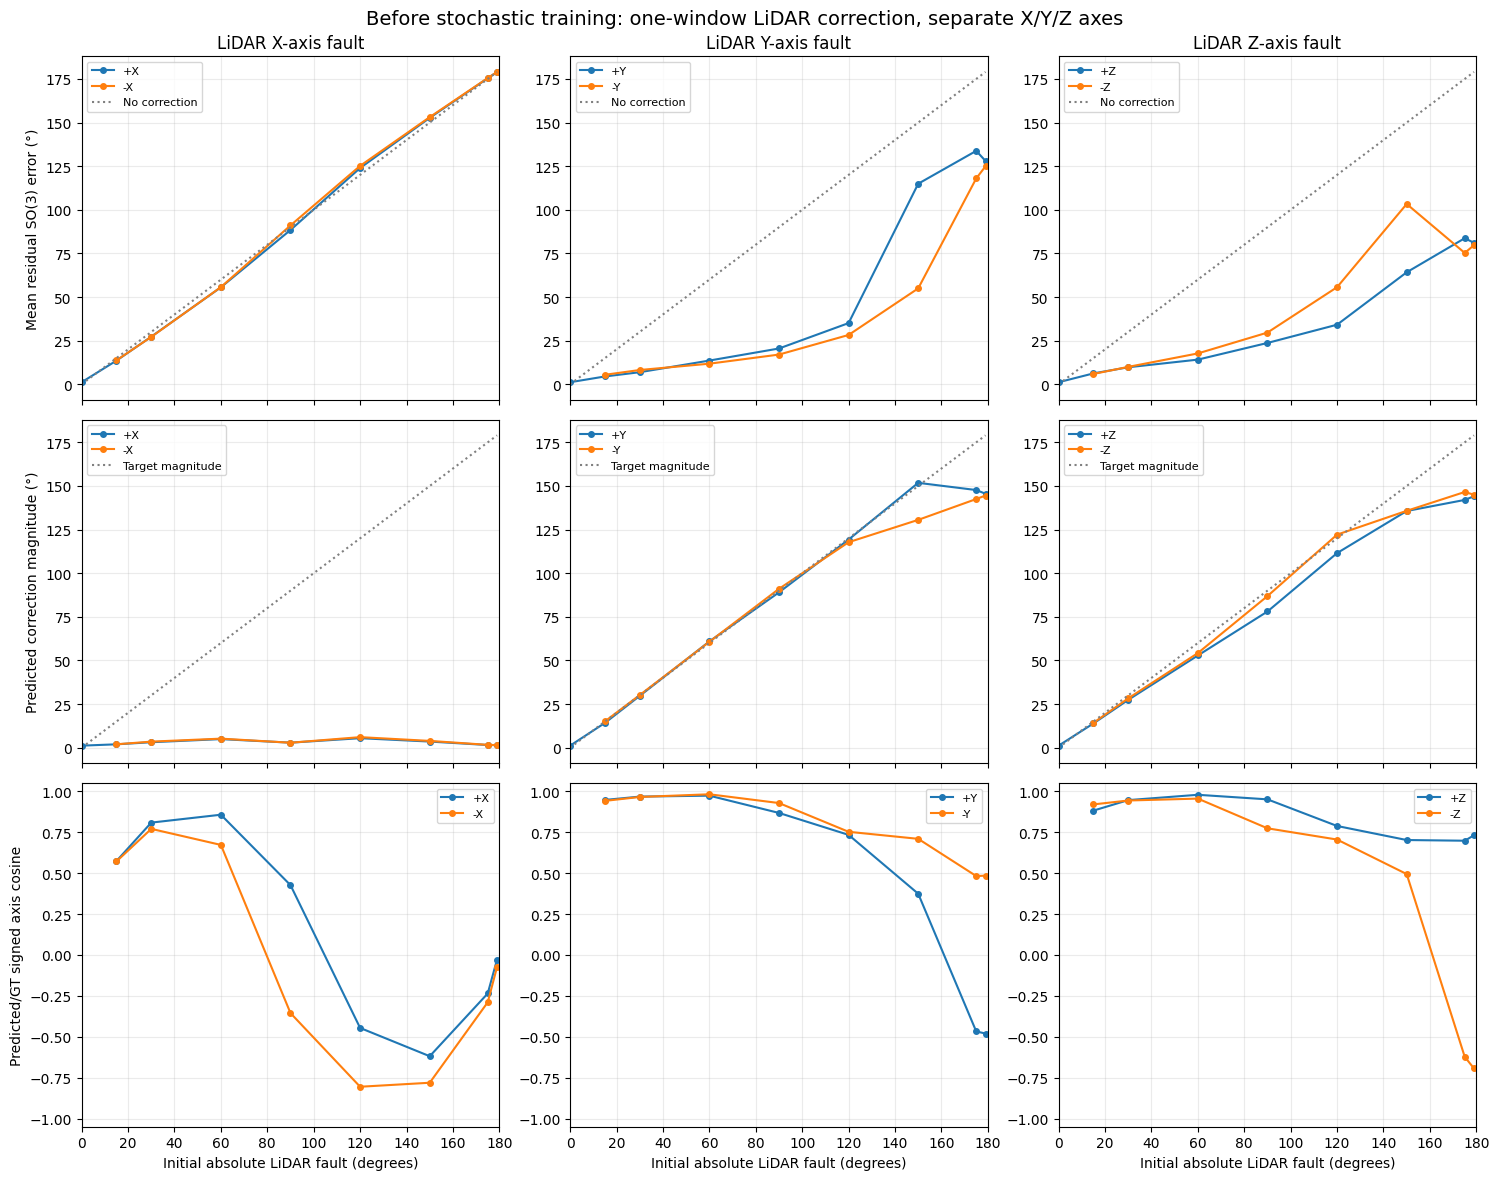

Evaluated model initialized from: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.27_full_rotation_regression/best.pt


In [12]:
# Notebook 60, insert after probe helpers (Cell 19), before stochastic preflight.
# One-step LiDAR-only rotation checks, independent of FAULT_KEY and X_AXIS_MASK.
# Uses the model currently loaded in Cell 12, including its trained 6D head.

LID60_KEY = 'lidar'
LID60_ANGLES = (0.0, 15.0, 30.0, 60.0, 90.0, 120.0, 150.0, 175.0, 179.0)
LID60_AXES = ('x', 'y', 'z')
LID60_PROBE_WINDOWS = 32
LID60_PROBE_BATCH_SIZE = 8
LID60_PROBE_SEED = VAL_AUG_SEED + 2_400_000
LID60_PLOT_DIR = RUN_DIR / 'plots' / 'lidar_xyz_before_stochastic'
LID60_PLOT_DIR.mkdir(parents=True, exist_ok=True)


def lid60_rotation_axis_cosine(R_pred, R_target):
    """Cosine of oriented principal axes; undefined for near-identity rotations."""
    def skew_vector(R):
        return torch.stack((R[..., 2, 1] - R[..., 1, 2], R[..., 0, 2] - R[..., 2, 0], R[..., 1, 0] - R[..., 0, 1]), dim=-1)

    p, t = skew_vector(R_pred), skew_vector(R_target)
    pn, tn = torch.linalg.vector_norm(p, dim=-1), torch.linalg.vector_norm(t, dim=-1)
    cos = (p * t).sum(-1) / (pn * tn).clamp_min(1e-12)
    return torch.where((pn > 1e-4) & (tn > 1e-4), cos.clamp(-1, 1), torch.full_like(cos, torch.nan))


@torch.inference_mode()
def lid60_one_window_evaluation():
    """Measure one-step X/Y/Z LiDAR correction, with matched physical inputs across axes."""
    rows = []
    selected_indices = np.unique(np.linspace(0, len(val_dataset) - 1, LID60_PROBE_WINDOWS).round().astype(int))
    was_training = model.training
    model.eval()
    try:
        for batch_start in range(0, len(selected_indices), LID60_PROBE_BATCH_SIZE):
            indices = selected_indices[batch_start:batch_start + LID60_PROBE_BATCH_SIZE]
            base = window_batch_to(collate_windows([val_dataset[int(i)] for i in indices]), DEVICE, dtype=DTYPE)
            physical = physical_augmenter(base, generator=augmentation_generator(LID60_PROBE_SEED + batch_start)).augmented_window
            truth = physical.current_calibration
            n = len(indices)

            for axis_id, axis in enumerate(LID60_AXES):
                for angle in LID60_ANGLES:
                    for sign in ((1,) if angle == 0 else (-1, 1)):
                        signed_angle = sign * angle
                        xi = {key: torch.zeros(n, 6, device=DEVICE, dtype=DTYPE) for key in CALIBRATION_KEYS}
                        tau = {key: torch.zeros(n, 1, device=DEVICE, dtype=DTYPE) for key in CALIBRATION_KEYS}
                        xi[LID60_KEY][:, axis_id] = np.deg2rad(signed_angle)
                        prior = apply_independent_prior_faults(truth, xi, tau)
                        output = model_predictions(clone_with_current_calibration(physical, prior)).predictions[LID60_KEY]
                        prior_R = prior[LID60_KEY].transform[:, :3, :3]
                        gt_R = truth[LID60_KEY].transform[:, :3, :3]
                        predicted_R = output.delta_rotation
                        desired_R = gt_R @ prior_R.transpose(-1, -2)
                        before = rotation_geodesic_deg(prior_R, gt_R)
                        after = rotation_geodesic_deg(predicted_R @ prior_R, gt_R)
                        predicted_angle = rotation_geodesic_deg(predicted_R, torch.eye(3, device=DEVICE, dtype=DTYPE).expand_as(predicted_R))
                        axis_cos = lid60_rotation_axis_cosine(predicted_R, desired_R)

                        if not torch.allclose(before, torch.full_like(before, abs(signed_angle)), atol=0.05, rtol=0.0):
                            raise AssertionError(f'Incorrect {axis} fault magnitude: {before.detach().cpu().tolist()}')
                        for j in range(n):
                            rows.append(dict(index=int(indices[j]), axis=axis.upper(), signed_angle_deg=float(signed_angle), angle_deg=float(angle),
                                             before_deg=float(before[j]), final_deg=float(after[j]), predicted_step_deg=float(predicted_angle[j]),
                                             axis_cosine=float(axis_cos[j]), improvement_deg=float(before[j] - after[j])))
            print(f'One-window LiDAR XYZ: {min(batch_start + n, len(selected_indices))}/{len(selected_indices)} physical windows', flush=True)
    finally:
        model.train(was_training)
    return pd.DataFrame.from_records(rows)


lid60_one_df = lid60_one_window_evaluation()
lid60_one_df.to_csv(LID60_PLOT_DIR / 'lidar_xyz_one_step_individual.csv', index=False)
lid60_one_summary = lid60_one_df.groupby(['axis', 'signed_angle_deg', 'angle_deg'], as_index=False).agg(
    final_deg=('final_deg', 'mean'), median_deg=('final_deg', 'median'), predicted_step_deg=('predicted_step_deg', 'mean'),
    axis_cosine=('axis_cosine', 'mean'), fraction_below_10deg=('final_deg', lambda x: (x < 10).mean()), n=('final_deg', 'size'))
display(lid60_one_summary.round(3))

fig, axes = plt.subplots(3, 3, figsize=(15, 12), sharex='col')
for col, axis in enumerate(('X', 'Y', 'Z')):
    for sign, color, label in ((1, 'tab:blue', '+'), (-1, 'tab:orange', '-')):
        curve = lid60_one_summary[(lid60_one_summary.axis == axis) & (lid60_one_summary.signed_angle_deg * sign >= 0)].sort_values('angle_deg')
        if sign == -1:
            curve = curve[curve.angle_deg > 0]
        axes[0, col].plot(curve.angle_deg, curve.final_deg, '-o', color=color, label=f'{label}{axis}', markersize=4)
        axes[1, col].plot(curve.angle_deg, curve.predicted_step_deg, '-o', color=color, label=f'{label}{axis}', markersize=4)
        axes[2, col].plot(curve.angle_deg, curve.axis_cosine, '-o', color=color, label=f'{label}{axis}', markersize=4)
    axes[0, col].plot(LID60_ANGLES, LID60_ANGLES, ':', color='gray', label='No correction')
    axes[1, col].plot(LID60_ANGLES, LID60_ANGLES, ':', color='gray', label='Target magnitude')
    axes[0, col].set_title(f'LiDAR {axis}-axis fault')
    for row in range(3):
        axes[row, col].grid(alpha=0.25)
        axes[row, col].legend(fontsize=8)
        axes[row, col].set_xlim(0, 180)
    axes[2, col].set_ylim(-1.05, 1.05)
    axes[2, col].set_xlabel('Initial absolute LiDAR fault (degrees)')
axes[0, 0].set_ylabel('Mean residual SO(3) error (°)')
axes[1, 0].set_ylabel('Predicted correction magnitude (°)')
axes[2, 0].set_ylabel('Predicted/GT signed axis cosine')
fig.suptitle('Before stochastic training: one-window LiDAR correction, separate X/Y/Z axes', fontsize=14)
fig.tight_layout()
fig.savefig(LID60_PLOT_DIR / 'lidar_xyz_one_window.png', dpi=180)
if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)
print('Evaluated model initialized from:', FINETUNE_INIT_CHECKPOINT)


/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


Completed LiDAR XYZ rollouts: Urban26, start=0, truth=1/1


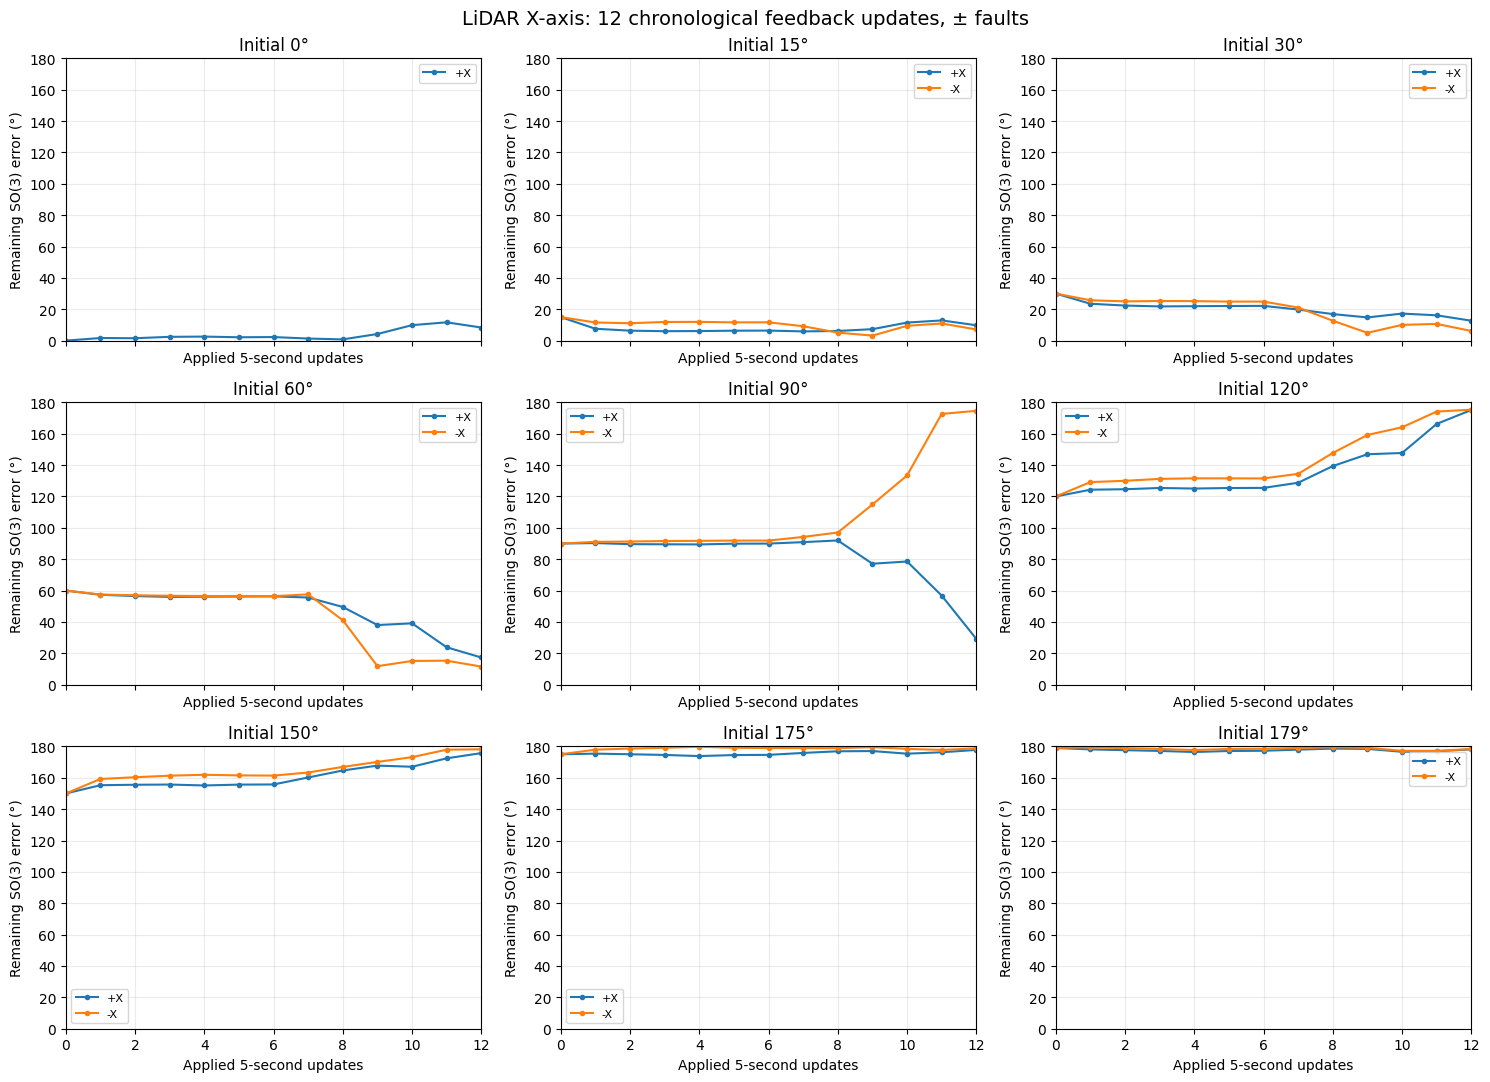

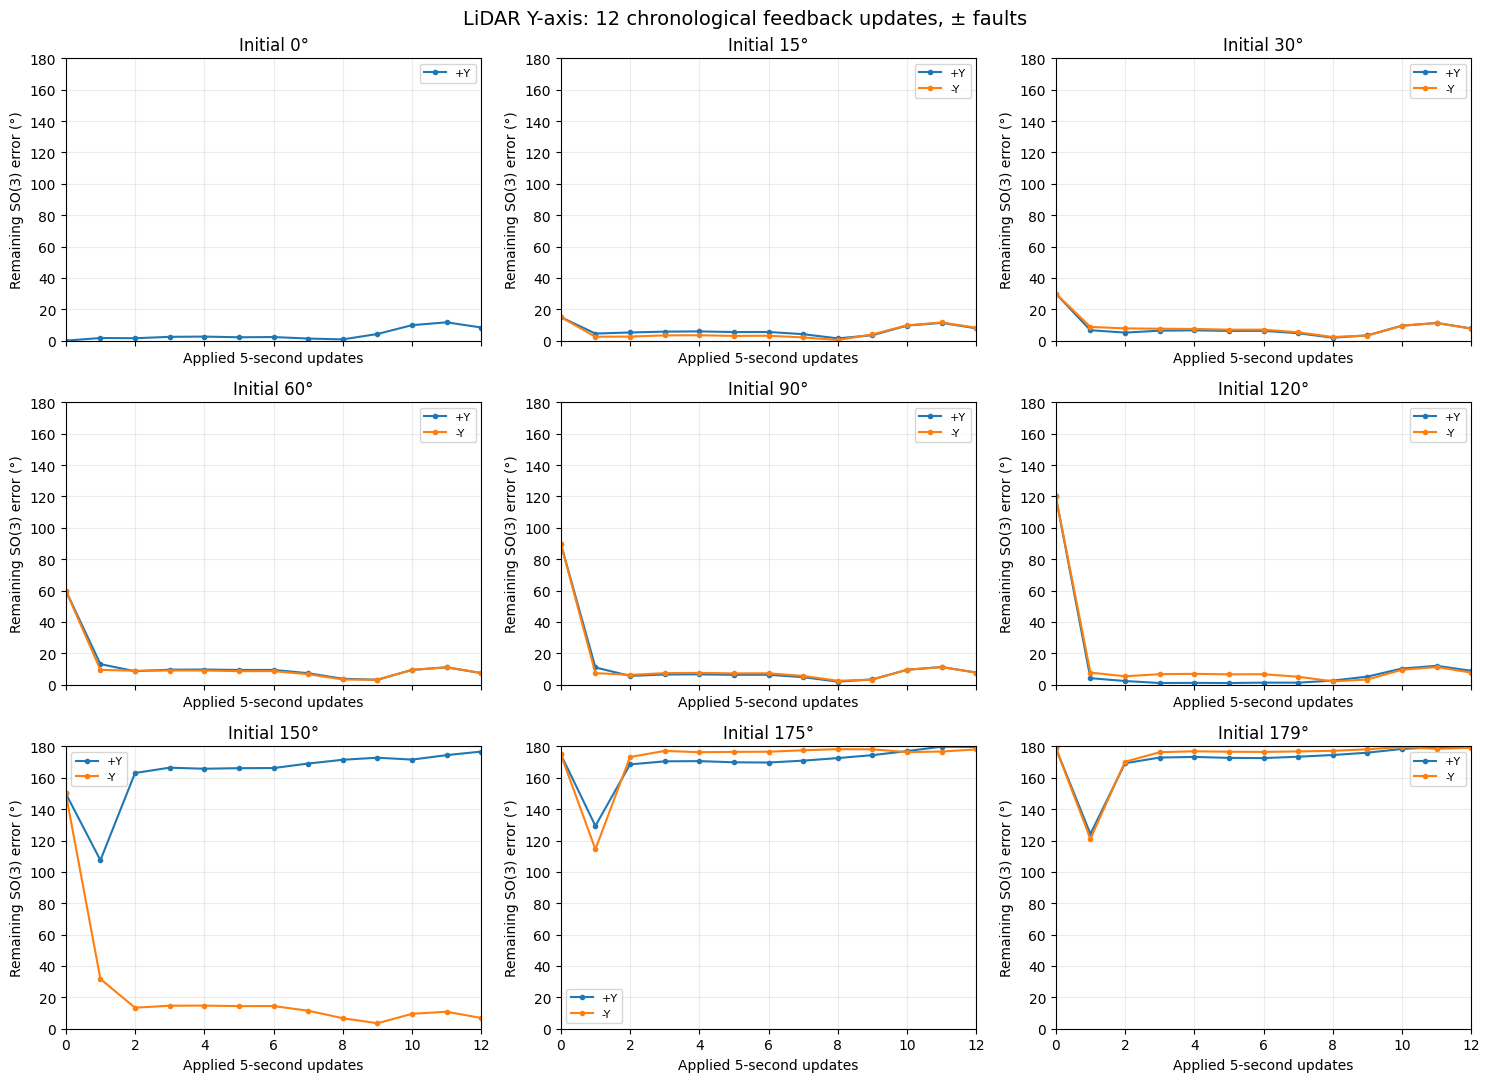

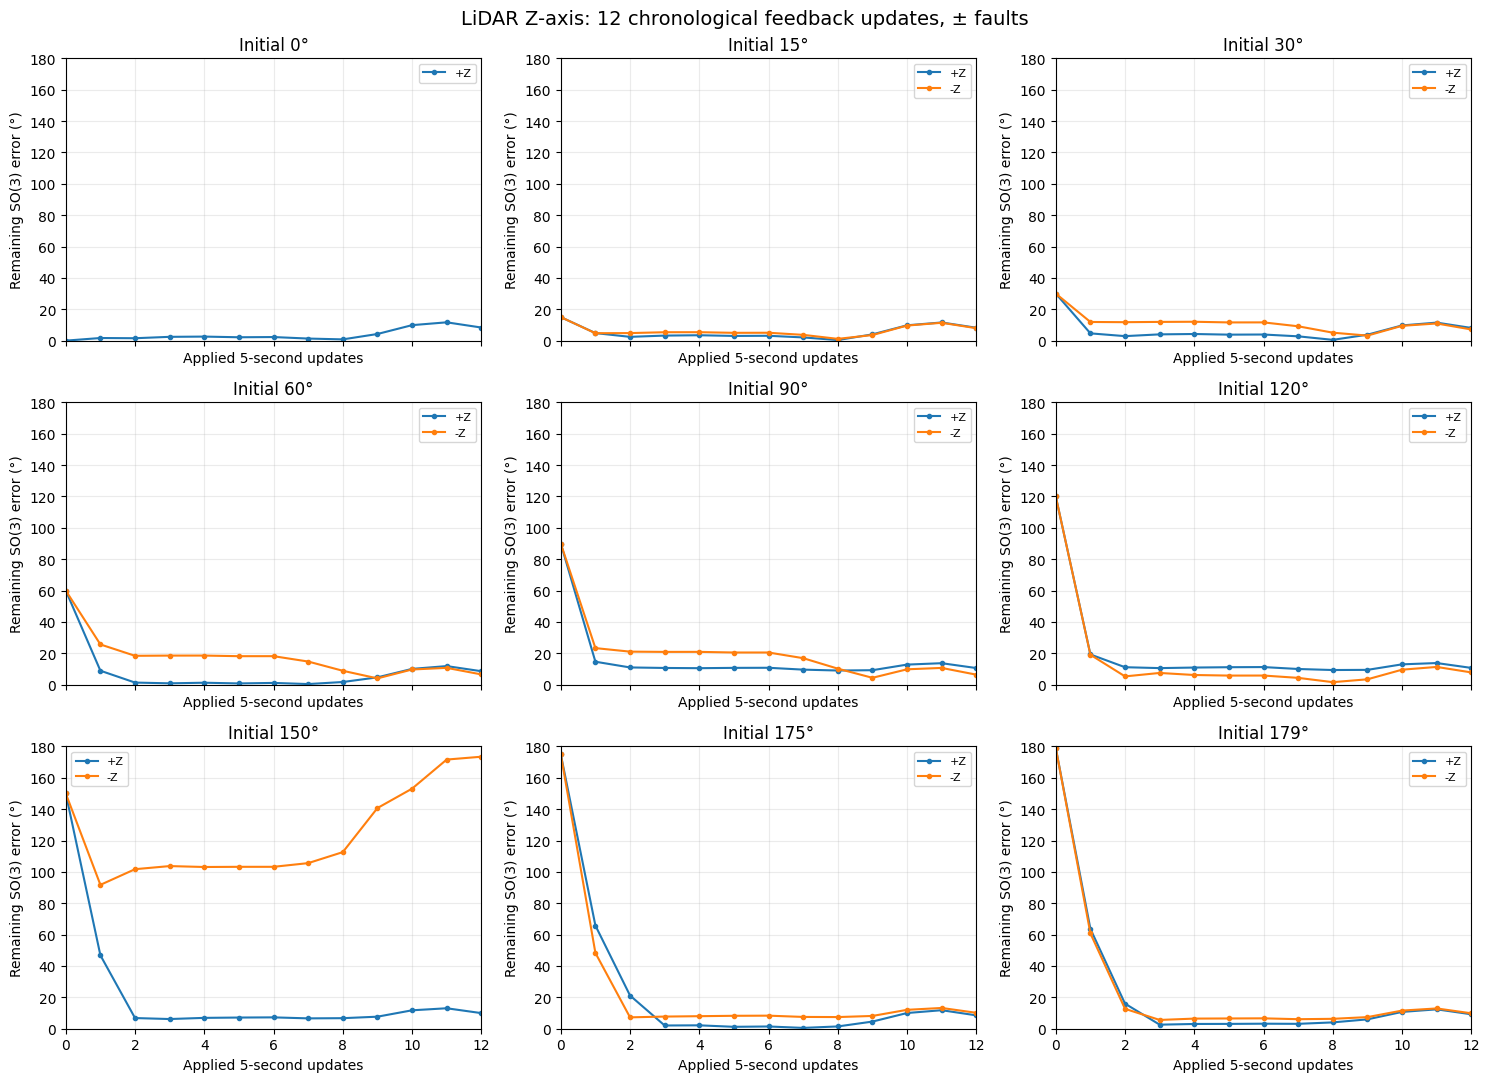

Final 12-window residuals, by axis and sign:


,axis,signed_angle_deg,n,mean_residual_deg,median_residual_deg,success_below_10deg
12,X,-179.0,1,178.345,178.345,0.0
25,X,-175.0,1,178.745,178.745,0.0
38,X,-150.0,1,178.187,178.187,0.0
51,X,-120.0,1,175.330,175.330,0.0
64,X,-90.0,1,174.605,174.605,0.0
77,X,-60.0,1,11.532,11.532,0.0
90,X,-30.0,1,6.171,6.171,1.0
103,X,-15.0,1,7.110,7.110,1.0
116,X,0.0,1,8.349,8.349,1.0
129,X,15.0,1,9.796,9.796,1.0


Mean residuals at steps 0, 1, 3, 6, and 12 (averaged across signs):


step               0       1       3       6       12
axis angle_deg                                       
X    0.0          0.0    1.66    2.42    2.28    8.35
     15.0        15.0    9.57    8.95    9.05    8.45
     30.0        30.0   24.62   23.54   23.53    9.44
     60.0        60.0   57.41   56.33   56.37   14.43
     90.0        90.0   90.67   90.56   90.92  101.90
     120.0      120.0  126.75  128.32  128.49  175.24
     150.0      150.0  157.25  158.51  158.58  176.96
     175.0      175.0  176.67  176.85  176.80  178.26
     179.0      179.0  178.77  177.77  177.86  178.25
Y    0.0          0.0    1.66    2.42    2.28    8.35
     15.0        15.0    3.51    4.53    4.31    8.03
     30.0        30.0    7.70    6.98    6.62    7.71
     60.0        60.0   11.27    9.30    9.02    7.40
     90.0        90.0    9.17    6.92    6.80    7.68
     120.0      120.0    5.93    3.88    3.98    8.26
     150.0      150.0   69.58   90.56   90.33   91.78
     175.0      175.0  121.86  173.81  173.18  178.85
     179.0      179.0  122.67  174.61  174.53  179.51
Z    0.0          0.0    1.66    2.42    2.28    8.35
     15.0        15.0    4.76    4.28    4.06    8.07
     30.0        30.0    8.26    7.97    7.77    7.60
     60.0        60.0   17.27    9.70    9.65    7.56
     90.0        90.0   18.98   15.78   15.64    8.49
     120.0      120.0   19.17    9.02    8.52    9.25
     150.0      150.0   69.28   54.94   55.24   91.69
     175.0      175.0   57.05    4.90    4.88    9.34
     179.0      179.0   62.22    4.09    4.91    9.52

No model weights or optimizer state were modified.


In [13]:
# Notebook 60, immediately after the LiDAR XYZ one-step diagnostic cell.
# Runs truly chronological 12-window feedback rollouts for independent LiDAR X/Y/Z faults.
# Requires the LID60_* settings and lid60_rotation_axis_cosine helper from the previous cell.

LID60_ROLLOUT_SEQUENCES = (VAL_NAMES[0],)  # For the stronger test: tuple(VAL_NAMES)
LID60_ROLLOUT_STARTS = 1                 # Increase to 2+ for more physical-motion diversity
LID60_ROLLOUT_TRUTHS = 1                 # Increase to 3+ for randomized true sensor frames
LID60_ROLLOUT_STEPS = 12
LID60_ROLLOUT_SEED = VAL_AUG_SEED + 2_500_000


@torch.inference_mode()
def lid60_xyz_rollouts():
    """Separate rollouts per axis/sign; feedback updates only the LiDAR rotation."""
    rows = []
    was_training = model.training
    model.eval()
    try:
        for sequence_id, sequence in enumerate(LID60_ROLLOUT_SEQUENCES):
            sequence_indices = np.asarray(val_dataset.window_indices_for_sequence(sequence), dtype=np.int64)
            max_start = len(sequence_indices) - LID60_ROLLOUT_STEPS
            if max_start < 0:
                raise ValueError(f'{sequence}: only {len(sequence_indices)} windows; need {LID60_ROLLOUT_STEPS}')
            start_positions = np.unique(np.linspace(0, max_start, min(LID60_ROLLOUT_STARTS, max_start + 1)).round().astype(int))

            for start_id, start in enumerate(start_positions):
                window_indices = sequence_indices[start:start + LID60_ROLLOUT_STEPS]
                for truth_id in range(LID60_ROLLOUT_TRUTHS):
                    physical_seed = LID60_ROLLOUT_SEED + sequence_id * 1_000_003 + start_id * 100_003 + truth_id * 1_009
                    physical_windows = []
                    for index in window_indices:
                        raw = window_batch_to(collate_windows([val_dataset[int(index)]]), DEVICE, dtype=DTYPE)
                        # Reset seed at every step: same physical calibration, different chronological measurements.
                        physical = physical_augmenter(raw, generator=augmentation_generator(physical_seed)).augmented_window
                        physical_windows.append(physical)
                    truth = physical_windows[0].current_calibration
                    for physical in physical_windows[1:]:
                        for key in CALIBRATION_KEYS:
                            torch.testing.assert_close(physical.current_calibration[key].transform, truth[key].transform, atol=2e-5, rtol=2e-5)
                            torch.testing.assert_close(physical.current_calibration[key].time_offset, truth[key].time_offset, atol=2e-6, rtol=2e-6)

                    for axis_id, axis in enumerate(LID60_AXES):
                        for angle in LID60_ANGLES:
                            for sign in ((1,) if angle == 0 else (-1, 1)):
                                signed_angle = sign * angle
                                xi = {key: torch.zeros(1, 6, device=DEVICE, dtype=DTYPE) for key in CALIBRATION_KEYS}
                                tau = {key: torch.zeros(1, 1, device=DEVICE, dtype=DTYPE) for key in CALIBRATION_KEYS}
                                xi[LID60_KEY][:, axis_id] = np.deg2rad(signed_angle)
                                states = apply_independent_prior_faults(truth, xi, tau)

                                for step in range(LID60_ROLLOUT_STEPS + 1):
                                    current_R = states[LID60_KEY].transform[:, :3, :3]
                                    truth_R = truth[LID60_KEY].transform[:, :3, :3]
                                    residual = float(rotation_geodesic_deg(current_R, truth_R)[0])
                                    rows.append(dict(sequence=sequence, start=int(window_indices[0]), truth_id=truth_id,
                                                     axis=axis.upper(), signed_angle_deg=float(signed_angle), angle_deg=float(angle),
                                                     step=step, residual_deg=residual))
                                    if step == LID60_ROLLOUT_STEPS:
                                        break

                                    inp = clone_with_current_calibration(physical_windows[step], states)
                                    pred = model_predictions(inp).predictions[LID60_KEY]
                                    updated_T = states[LID60_KEY].transform.clone()
                                    updated_T[:, :3, :3] = pred.delta_rotation @ current_R
                                    # Rotation only: translation and time offsets remain exactly unchanged.
                                    states = dict(states)
                                    states[LID60_KEY] = replace(states[LID60_KEY], transform=updated_T)
                    print(f'Completed LiDAR XYZ rollouts: {sequence}, start={int(window_indices[0])}, truth={truth_id + 1}/{LID60_ROLLOUT_TRUTHS}', flush=True)
    finally:
        model.train(was_training)
    return pd.DataFrame.from_records(rows)


lid60_roll_df = lid60_xyz_rollouts()
lid60_roll_df.to_csv(LID60_PLOT_DIR / 'lidar_xyz_rollout_individual.csv', index=False)
lid60_roll_summary = lid60_roll_df.groupby(['axis', 'signed_angle_deg', 'angle_deg', 'step'], as_index=False).agg(
    mean_residual_deg=('residual_deg', 'mean'), median_residual_deg=('residual_deg', 'median'),
    success_below_10deg=('residual_deg', lambda x: (x < 10).mean()), n=('residual_deg', 'size'))

for axis in ('X', 'Y', 'Z'):
    fig, axes = plt.subplots(3, 3, figsize=(15, 11), sharex=True, squeeze=False)
    for ax, angle in zip(axes.flat, LID60_ANGLES):
        for sign, color, label in ((1, 'tab:blue', f'+{axis}'), (-1, 'tab:orange', f'-{axis}')):
            if angle == 0 and sign == -1:
                continue
            curve = lid60_roll_summary[(lid60_roll_summary.axis == axis) & (lid60_roll_summary.signed_angle_deg == sign * angle)].sort_values('step')
            ax.plot(curve.step, curve.mean_residual_deg, '-o', label=label, color=color, markersize=3)
        ax.set(title=f'Initial {angle:g}°', xlabel='Applied 5-second updates', ylabel='Remaining SO(3) error (°)', xlim=(0, LID60_ROLLOUT_STEPS), ylim=(0, 180))
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
    fig.suptitle(f'LiDAR {axis}-axis: 12 chronological feedback updates, ± faults', fontsize=14)
    fig.tight_layout()
    fig.savefig(LID60_PLOT_DIR / f'lidar_{axis.lower()}_12_window_rollouts.png', dpi=180)
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)

final = lid60_roll_summary[lid60_roll_summary.step == LID60_ROLLOUT_STEPS]
print('Final 12-window residuals, by axis and sign:')
display(final[['axis', 'signed_angle_deg', 'n', 'mean_residual_deg', 'median_residual_deg', 'success_below_10deg']].round(3))
print('Mean residuals at steps 0, 1, 3, 6, and 12 (averaged across signs):')
display(lid60_roll_df[lid60_roll_df.step.isin((0, 1, 3, 6, LID60_ROLLOUT_STEPS))].groupby(['axis', 'angle_deg', 'step'], as_index=False).residual_deg.mean().pivot_table(index=['axis', 'angle_deg'], columns='step', values='residual_deg').round(2))
print('No model weights or optimizer state were modified.')


## 8. Reversible stochastic preflight; retain best **and final** candidate

In [14]:
RUN_STOCHASTIC_PRECHECK = True
STOCHASTIC_STEPS = 500
STOCHASTIC_BATCH_SIZE = 16
STOCHASTIC_REPORT_EVERY = 25
STOCHASTIC_PROBE_WINDOWS = 16
STOCHASTIC_SEED = TRAIN_AUG_SEED + 900000
STOCHASTIC_BEST_PATH = RUN_DIR / 'stochastic_best_6d_state.pt'
STOCHASTIC_LAST_PATH = RUN_DIR / 'stochastic_last_6d_state.pt'
SAVE_STOCHASTIC_CANDIDATE = True
LOAD_STOCHASTIC_CANDIDATE_FOR_FULL = False
stochastic_history = []
stochastic_probe_rows = []
STOCHASTIC_BEST_SCORE = float('inf')

In [15]:
# Notebook 60 — stochastic preflight on the currently selected FAULT_KEY and X_AXIS_MASK.
# Self-contained probe construction: does NOT call build_probe_batches(), which hard-codes X.

assert FAULT_KEY in CALIBRATION_KEYS, FAULT_KEY
assert len(X_AXIS_MASK) == 3 and sum(X_AXIS_MASK) == 1, X_AXIS_MASK
axis_id = X_AXIS_MASK.index(True)
axis_name = 'XYZ'[axis_id]

# These objects are instantiated by the augmentation setup cell. Re-run that cell after changing settings.
assert fine_prior_perturber.config.rotation_axes == X_AXIS_MASK, 'Rerun augmentation setup: fine sampler uses a different axis.'
assert coarse_prior_perturber.config.rotation_axes == X_AXIS_MASK, 'Rerun augmentation setup: coarse sampler uses a different axis.'
assert fine_prior_perturber.config.probability_by_key.get(FAULT_KEY) == 1.0, 'Rerun augmentation setup: fine sampler targets a different sensor.'
assert coarse_prior_perturber.config.probability_by_key.get(FAULT_KEY) == 1.0, 'Rerun augmentation setup: coarse sampler targets a different sensor.'

@torch.no_grad()
def build_current_axis_preflight_batches(dataset, *, n_windows, batch_size, seed, angles=PROBE_ANGLES_DEG):
    """Matched +/- faults on the current sensor/axis, with identical physical windows and true frames."""
    indices = np.unique(np.linspace(0, len(dataset) - 1, min(len(dataset), n_windows)).round().astype(int))
    batches = []
    for group_id, start in enumerate(range(0, len(indices), batch_size)):
        chosen = indices[start:start + batch_size]
        base = window_batch_to(collate_windows([dataset[int(i)] for i in chosen]), DEVICE, dtype=DTYPE)
        physical = physical_augmenter(base, generator=augmentation_generator(seed + group_id * 1009)).augmented_window
        n = len(chosen)
        for axis_seed, sign in enumerate((1.0, -1.0)):
            cases = {}
            for angle in angles:
                xi = {key: torch.zeros(n, 6, device=DEVICE, dtype=DTYPE) for key in CALIBRATION_KEYS}
                tau = {key: torch.zeros(n, 1, device=DEVICE, dtype=DTYPE) for key in CALIBRATION_KEYS}
                xi[FAULT_KEY][:, axis_id] = sign * np.deg2rad(float(angle))
                prior = apply_independent_prior_faults(physical.current_calibration, xi, tau)
                cases[float(angle)] = (clone_with_current_calibration(physical, prior), [FAULT_KEY] * n, chosen.copy(), axis_seed)
            batches.append(cases)
    return batches

@torch.no_grad()
def make_current_axis_training_window(base_window, *, generator):
    """Same stochastic augmentation as make_training_window(), with an axis-independent validity check."""
    physical = physical_augmenter(base_window, generator=generator).augmented_window
    truth = physical.current_calibration
    _, fine_xi, fine_tau = fine_prior_perturber(truth, generator=generator)
    _, coarse_xi, coarse_tau = coarse_prior_perturber(truth, generator=generator)
    n = truth[FAULT_KEY].transform.shape[0]
    coarse_mask = torch.rand(n, generator=generator, device=DEVICE) < COARSE_PRIOR_PROBABILITY
    xi = {key: torch.where(coarse_mask[:, None], coarse_xi[key], fine_xi[key]) for key in CALIBRATION_KEYS}
    tau = {key: torch.where(coarse_mask[:, None], coarse_tau[key], fine_tau[key]) for key in CALIBRATION_KEYS}
    forbidden_axes = [i for i in range(3) if i != axis_id]
    assert all(bool((xi[key][:, forbidden_axes] == 0).all()) and bool((xi[key][:, 3:] == 0).all()) for key in CALIBRATION_KEYS)
    assert all(bool((xi[key] == 0).all()) and bool((tau[key] == 0).all()) for key in CALIBRATION_KEYS if key != FAULT_KEY)
    return clone_with_current_calibration(physical, apply_independent_prior_faults(truth, xi, tau))

# Reset score/history when rerunning this cell on a different axis. Output checkpoint names are unchanged.
stochastic_history = []
stochastic_probe_rows = []
STOCHASTIC_BEST_SCORE = float('inf')

preflight_probe_batches = build_current_axis_preflight_batches(
    val_dataset, n_windows=STOCHASTIC_PROBE_WINDOWS, batch_size=PROBE_BATCH_SIZE,
    seed=VAL_AUG_SEED + 200000,
)
print(f'Stochastic training target: {FAULT_KEY} ±{axis_name} | fixed validation: +{axis_name} and -{axis_name}, {STOCHASTIC_PROBE_WINDOWS} windows')

if RUN_STOCHASTIC_PRECHECK:
    saved_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
    saved_training = model.training
    saved_cpu_rng = torch.get_rng_state().clone()
    saved_cuda_rng = torch.cuda.get_rng_state_all() if DEVICE.type == 'cuda' else None
    saved_np_rng, saved_py_rng = np.random.get_state(), random.getstate()
    pre_optimizer = torch.optim.AdamW(parameter_groups(model), weight_decay=WEIGHT_DECAY)
    pre_generator = augmentation_generator(STOCHASTIC_SEED)
    index_rng = np.random.default_rng(STOCHASTIC_SEED + 1)
    try:
        for step in range(STOCHASTIC_STEPS + 1):
            if step > 0:
                model.train()
                pre_optimizer.zero_grad(set_to_none=True)
                indices = index_rng.choice(len(train_dataset), size=min(STOCHASTIC_BATCH_SIZE, len(train_dataset)), replace=False)
                base = window_batch_to(collate_windows([train_dataset[int(i)] for i in indices]), DEVICE, dtype=DTYPE)
                batch = make_current_axis_training_window(base, generator=pre_generator)
                output = model_predictions(batch)
                loss, metrics = compute_6d_objective(batch, output)
                loss.backward()
                grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
                pre_optimizer.step()
                train_loss = float(loss.detach())
                del base, batch, output, loss
            else:
                train_loss, grad_norm = float('nan'), float('nan')

            if step == 0 or step % STOCHASTIC_REPORT_EVERY == 0 or step == STOCHASTIC_STEPS:
                frame = evaluate_probe(model, preflight_probe_batches)
                frame['step'] = step
                stochastic_probe_rows.extend(frame.to_dict('records'))
                summary = summarize_probe(frame)
                score = probe_score(summary)
                stochastic_history.append(dict(
                    step=step, train_loss=train_loss, grad_norm=float(grad_norm), probe_score=score,
                    **{f'angle_{int(a)}_deg': float(summary.loc[summary.angle_deg == a, 'final_deg'].iloc[0]) for a in PROBE_ANGLES_DEG},
                ))
                if score < STOCHASTIC_BEST_SCORE:
                    STOCHASTIC_BEST_SCORE = score
                    if SAVE_STOCHASTIC_CANDIDATE:
                        torch.save({'model_state_dict': {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}, 'step': step, 'score': score}, STOCHASTIC_BEST_PATH)
                if step == STOCHASTIC_STEPS:
                    torch.save({'model_state_dict': {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}, 'step': step, 'score': score}, STOCHASTIC_LAST_PATH)

                selection = {int(a): round(float(summary.loc[summary.angle_deg == a, 'final_deg'].iloc[0]), 3) for a in (0.0, 30.0, 60.0, 90.0, 120.0, 150.0, 175.0, 179.0)}
                print(f'step {step:4d}/{STOCHASTIC_STEPS} | {FAULT_KEY} ±{axis_name} | train={train_loss:.3f} grad={float(grad_norm):.2f} | score={score:.4f} | residuals={selection}', flush=True)
                # if 179.0 in PROBE_ANGLES_DEG:
                #     signed_179 = frame.loc[frame.angle_deg == 179.0].groupby('signed_angle_deg')['after_deg'].mean().round(3).to_dict()
                #     print(f'    {axis_name} signed 179°: {signed_179}', flush=True)
    finally:
        model.load_state_dict(saved_state, strict=True)
        model.train(saved_training)
        optimizer.zero_grad(set_to_none=True)
        torch.set_rng_state(saved_cpu_rng)
        if saved_cuda_rng is not None:
            torch.cuda.set_rng_state_all(saved_cuda_rng)
        np.random.set_state(saved_np_rng)
        random.setstate(saved_py_rng)
        del saved_state, pre_optimizer
        gc.collect()
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()
    print('Preflight restored the original weights and RNG. Main optimizer remains untouched.')
else:
    print('Stochastic preflight disabled.')


Stochastic training target: lidar ±Z | fixed validation: +Z and -Z, 16 windows
step    0/500 | lidar ±Z | train=nan grad=nan | score=0.4662 | residuals={0: 1.656, 30: 11.756, 60: 21.744, 90: 33.844, 120: 51.485, 150: 92.895, 175: 89.194, 179: 92.518}
    Z signed 179°: {-179.0: 90.901, 179.0: 94.135}
step   25/500 | lidar ±Z | train=0.102 grad=1.44 | score=0.3628 | residuals={0: 1.575, 30: 10.64, 60: 17.735, 90: 26.345, 120: 36.55, 150: 70.164, 175: 66.988, 179: 69.219}
    Z signed 179°: {-179.0: 68.056, 179.0: 70.383}
step   50/500 | lidar ±Z | train=0.213 grad=5.03 | score=0.3207 | residuals={0: 2.006, 30: 10.59, 60: 17.08, 90: 24.972, 120: 31.892, 150: 53.471, 175: 55.83, 179: 56.958}
    Z signed 179°: {-179.0: 56.279, 179.0: 57.637}
step   75/500 | lidar ±Z | train=0.102 grad=2.89 | score=0.3082 | residuals={0: 2.429, 30: 10.736, 60: 18.691, 90: 26.573, 120: 32.174, 150: 43.836, 175: 48.454, 179: 48.478}
    Z signed 179°: {-179.0: 47.905, 179.0: 49.051}
step  100/500 | lidar ±Z 

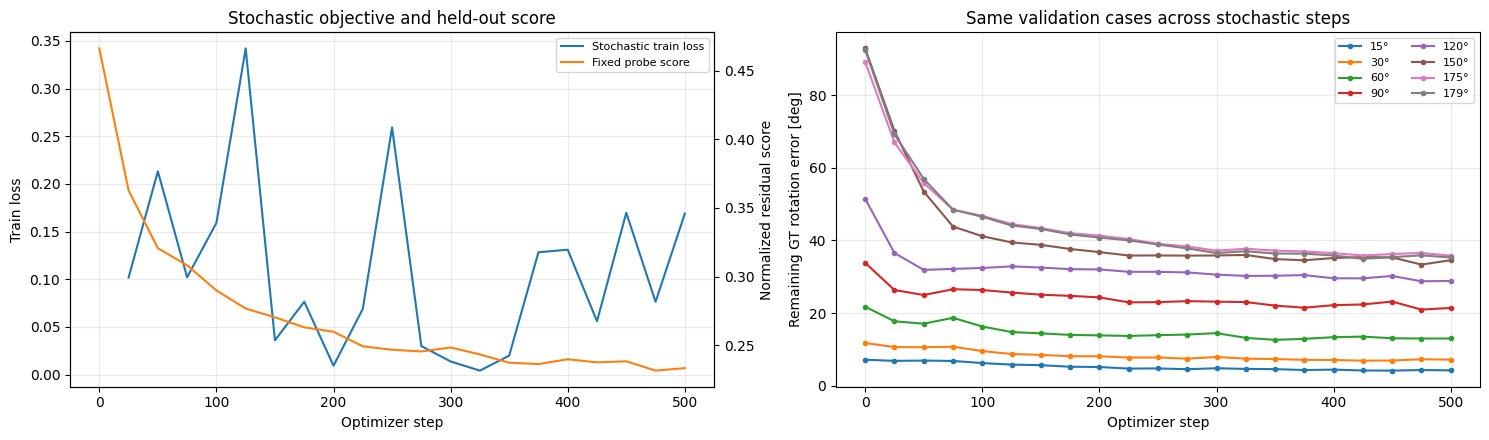

In [17]:
if stochastic_history:
    pd.DataFrame(stochastic_history).to_csv(RUN_DIR / 'stochastic_6d_history.csv', index=False)
    pd.DataFrame(stochastic_probe_rows).to_csv(RUN_DIR / 'stochastic_6d_angle_cases.csv', index=False)
    trace = pd.DataFrame(stochastic_history)
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    axes[0].plot(trace.step, trace.train_loss, label='Stochastic train loss')
    ax0 = axes[0].twinx()
    ax0.plot(trace.step, trace.probe_score, color='C1', label='Fixed probe score')
    axes[0].set(xlabel='Optimizer step', ylabel='Train loss', title='Stochastic objective and held-out score')
    ax0.set_ylabel('Normalized residual score')
    h1,l1=axes[0].get_legend_handles_labels();h2,l2=ax0.get_legend_handles_labels();axes[0].legend(h1+h2,l1+l2,fontsize=8)
    for a in PROBE_ANGLES_DEG:
        if a == 0:
            continue
        axes[1].plot(trace.step, trace[f'angle_{int(a)}_deg'], marker='.', label=f'{int(a)}°')
    axes[1].set(xlabel='Optimizer step', ylabel='Remaining GT rotation error [deg]', title='Same validation cases across stochastic steps')
    axes[1].legend(ncol=2,fontsize=8)
    for ax in axes:ax.grid(alpha=.25)
    fig.tight_layout();fig.savefig(RUN_DIR / 'stochastic_6d_learning.png', dpi=170)
    if SHOW_PLOTS:plt.show()
    else:plt.close(fig)


# Stochastic run (harder)

In [24]:
# Notebook 60 - second stochastic preflight, CELL 1: configuration and mixed-fault helpers.
# Insert after the existing single-axis stochastic preflight (or before it, if you skip that run).
# Requires cells defining physical_augmenter, model, model_predictions, compute_6d_objective,
# CalibrationPriorPerturber, prior-perturbation classes and the calibration helpers.

MULTI_RUN_DIR = RUN_DIR / 'second_stochastic_xyz'
MULTI_RUN_DIR.mkdir(parents=True, exist_ok=True)

# Two phases in ONE continuous fine-tuning experiment. Set the first count to 0
# to jump directly to one random sensor + one random Cartesian axis per sample.
MULTI_STAGES = (('lidar_xyz', 350), ('all_xyz', 800))
MULTI_BATCH_SIZE = 32
MULTI_REPORT_EVERY = 25
MULTI_PROBE_WINDOWS = 12
MULTI_PROBE_ANGLES_DEG = (0.0, 30.0, 90.0, 150.0, 179.0)
MULTI_COARSE_PROBABILITY = 0.50
MULTI_IDENTITY_PROBABILITY = 0.10
MULTI_HEAD_LR = 1e-4
MULTI_TRANSFORMER_LR = 1e-5
MULTI_TRAIN_SEED = TRAIN_AUG_SEED + 2026000
MULTI_PROBE_SEED = VAL_AUG_SEED + 2026000
MULTI_INIT_PATH = None  # Or STOCHASTIC_BEST_PATH to start from the earlier single-axis candidate.
MULTI_RESTORE_MODEL = True  # Restore Notebook 60's weights and RNG after this preflight.
MULTI_KEYS = tuple(CALIBRATION_KEYS)
MULTI_AXES = ('X', 'Y', 'Z')
MULTI_CHECKPOINTS = {stage: MULTI_RUN_DIR / f'{stage}_best.pt' for stage, _ in MULTI_STAGES}
MULTI_LAST_PATH = MULTI_RUN_DIR / 'all_xyz_last.pt'

assert MULTI_KEYS == ('imu', 'lidar', 'lidar_right')
assert 0.0 <= MULTI_IDENTITY_PROBABILITY < 1.0
assert 0.0 <= MULTI_COARSE_PROBABILITY <= 1.0
assert all(count >= 0 for _, count in MULTI_STAGES)
assert MULTI_HEAD_LR > 0 and MULTI_TRANSFORMER_LR > 0


def make_multi_prior_config(*, stage, coarse):
    """One Cartesian axis per example; stage controls which sensor can be wrong."""
    if stage not in ('lidar_xyz', 'all_xyz'):
        raise ValueError(f'Unknown stage: {stage}')
    magnitude = (
        PerturbationMagnitudeConfig(
            maximum=np.deg2rad(COARSE_ROTATION_MAX_DEG),
            minimum=np.deg2rad(COARSE_ROTATION_MIN_DEG),
            distribution=PerturbationDistribution.UNIFORM,
        ) if coarse else PerturbationMagnitudeConfig(
            maximum=np.deg2rad(FINE_ROTATION_MAX_DEG),
            distribution=PerturbationDistribution.TRUNCATED_STUDENT_T,
            scale=np.deg2rad(FINE_ROTATION_SCALE_DEG),
            degrees_of_freedom=STUDENT_T_DOF,
        )
    )
    return PriorPerturbationConfig(
        enabled=True,
        probability=1.0 if stage == 'all_xyz' else 0.0,
        probability_by_key={} if stage == 'all_xyz' else {'lidar': 1.0},
        rotation=magnitude,
        translation=None,
        time_offset=None,
        one_calibration_per_sample=(stage == 'all_xyz'),
        one_rotation_axis_per_sample=True,
        rotation_axes=(True, True, True),
        one_perturbation_type_per_sample=False,
    )


multi_perturbers = {
    stage: (
        CalibrationPriorPerturber(make_multi_prior_config(stage=stage, coarse=False)),
        CalibrationPriorPerturber(make_multi_prior_config(stage=stage, coarse=True)),
    )
    for stage, _ in MULTI_STAGES
}


@torch.no_grad()
def make_multi_training_window(base, *, generator, stage):
    """Return one 5s window with at most one fault, on one of the three coordinate axes."""
    physical = physical_augmenter(base, generator=generator).augmented_window
    truth = physical.current_calibration
    fine_perturber, coarse_perturber = multi_perturbers[stage]
    _, fine_xi, _ = fine_perturber(truth, generator=generator)
    _, coarse_xi, _ = coarse_perturber(truth, generator=generator)
    n = next(iter(truth.values())).transform.shape[0]
    coarse = torch.rand(n, generator=generator, device=DEVICE) < MULTI_COARSE_PROBABILITY
    zero = torch.rand(n, generator=generator, device=DEVICE) < MULTI_IDENTITY_PROBABILITY

    xi = {
        key: torch.where(coarse[:, None], coarse_xi[key], fine_xi[key]).masked_fill(zero[:, None], 0.0)
        for key in MULTI_KEYS
    }
    tau = {key: torch.zeros(n, 1, device=DEVICE, dtype=DTYPE) for key in MULTI_KEYS}
    rotation_grid = torch.stack([xi[key][:, :3] for key in MULTI_KEYS], dim=1)
    active = rotation_grid.abs() > 0.0  # [batch, sensor, axis]
    assert bool((active.sum(dim=(1, 2)) <= 1).all()), 'More than one sensor/axis fault in one sample.'
    assert all(bool((xi[key][:, 3:] == 0).all()) for key in MULTI_KEYS)
    if stage == 'lidar_xyz':
        assert bool((rotation_grid[:, (0, 2)] == 0).all()), 'LiDAR-only stage perturbed another key.'

    return clone_with_current_calibration(physical, apply_independent_prior_faults(truth, xi, tau)), active.sum(dim=0).cpu().numpy()


@torch.no_grad()
def build_multi_probe_cases(dataset, *, n_windows, batch_size, seed, angles=MULTI_PROBE_ANGLES_DEG):
    """Identical held-out physical examples for all 9 sensor-axis pairs and both signs."""
    chosen_indices = np.unique(np.linspace(0, len(dataset) - 1, min(len(dataset), n_windows)).round().astype(int))
    probe_cases = []
    for group_id, start in enumerate(range(0, len(chosen_indices), batch_size)):
        chosen = chosen_indices[start:start + batch_size]
        base = window_batch_to(collate_windows([dataset[int(i)] for i in chosen]), DEVICE, dtype=DTYPE)
        physical = physical_augmenter(base, generator=augmentation_generator(seed + group_id * 1009)).augmented_window
        n = len(chosen)
        for key in MULTI_KEYS:
            for axis_id, axis in enumerate(MULTI_AXES):
                for sign_id, sign in enumerate((+1.0, -1.0)):
                    cases = {}
                    for angle in angles:
                        xi = {k: torch.zeros(n, 6, device=DEVICE, dtype=DTYPE) for k in MULTI_KEYS}
                        tau = {k: torch.zeros(n, 1, device=DEVICE, dtype=DTYPE) for k in MULTI_KEYS}
                        xi[key][:, axis_id] = sign * np.deg2rad(float(angle))
                        prior = apply_independent_prior_faults(physical.current_calibration, xi, tau)
                        cases[float(angle)] = (clone_with_current_calibration(physical, prior), [key] * n, chosen.copy(), sign_id)
                    probe_cases.append((key, axis, cases))
    return probe_cases


print('Second stochastic preflight:', MULTI_STAGES)
print('Train: one X/Y/Z axis per sample; phase 2 selects imu/lidar/lidar_right uniformly.')
print('Validation: 9 sensor-axis combinations, both signs,', MULTI_PROBE_WINDOWS, 'fixed validation windows.')
print('The ordinary FAULT_KEY and X_AXIS_MASK settings do NOT control this preflight.')


Second stochastic preflight: (('lidar_xyz', 350), ('all_xyz', 800))
Train: one X/Y/Z axis per sample; phase 2 selects imu/lidar/lidar_right uniformly.
Validation: 9 sensor-axis combinations, both signs, 12 fixed validation windows.
The ordinary FAULT_KEY and X_AXIS_MASK settings do NOT control this preflight.


In [ ]:
# Notebook 60 - second stochastic preflight, CELL 2: train, evaluate, save, plot, restore.
# Run after 60_second_stochastic_settings.py and after model initialization (cell 12).

multi_probe_cases = build_multi_probe_cases(
    val_dataset, n_windows=MULTI_PROBE_WINDOWS, batch_size=PROBE_BATCH_SIZE, seed=MULTI_PROBE_SEED
)
multi_history, multi_probe_rows, multi_pair_rows = [], [], []
multi_phase_best = {stage: float('inf') for stage, _ in MULTI_STAGES}


def evaluate_multi_probe(candidate):
    frames = []
    for key, axis, cases in multi_probe_cases:
        frame = evaluate_probe(candidate, [cases])  # Reuses Notebook 60's actual SO(3) update evaluator.
        frame['axis'] = axis
        frames.append(frame)
    frame = pd.concat(frames, ignore_index=True)
    active = frame[frame.angle_deg > 0.0]
    group = active.groupby(['fault_key', 'axis'], as_index=False).agg(
        remaining_ratio=('relative_remaining', 'mean'),
        mean_after_deg=('after_deg', 'mean'),
        fraction_improving=('improved', 'mean'),
        n=('after_deg', 'size'),
    )
    if len(group) != len(MULTI_KEYS) * len(MULTI_AXES):
        raise RuntimeError('Mixed validation is missing sensor-axis combinations.')
    average_ratio = float(group.remaining_ratio.mean())
    worst_ratio = float(group.remaining_ratio.max())
    zero_drift = float(frame.loc[frame.angle_deg == 0.0, 'after_deg'].mean())
    # The worst pair matters: improvement on easy IMU faults must not hide LiDAR-X failure.
    score = average_ratio + 0.25 * (worst_ratio - average_ratio) + ZERO_DRIFT_WEIGHT * zero_drift / 30.0
    return frame, group, score, average_ratio, worst_ratio, zero_drift


multi_saved_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
multi_saved_training = model.training
multi_saved_cpu_rng = torch.get_rng_state().clone()
multi_saved_cuda_rng = torch.cuda.get_rng_state_all() if DEVICE.type == 'cuda' else None
multi_saved_np_rng, multi_saved_py_rng = np.random.get_state(), random.getstate()
multi_optimizer = None
multi_global_step = 0
multi_sampling_counts = {stage: np.zeros((3, 3), dtype=np.int64) for stage, _ in MULTI_STAGES}

try:
    if MULTI_INIT_PATH is not None:
        init = torch.load(MULTI_INIT_PATH, map_location='cpu', weights_only=True)
        model.load_state_dict(init.get('model_state_dict', init), strict=True)
        print('Loaded second-preflight initialization:', MULTI_INIT_PATH)
    else:
        print('Second preflight starts from the model currently in memory.')

    multi_groups = parameter_groups(model)
    multi_groups[0]['lr'] = MULTI_TRANSFORMER_LR
    multi_groups[1]['lr'] = MULTI_HEAD_LR
    multi_optimizer = torch.optim.AdamW(multi_groups, weight_decay=WEIGHT_DECAY)
    multi_generator = augmentation_generator(MULTI_TRAIN_SEED)
    multi_index_rng = np.random.default_rng(MULTI_TRAIN_SEED + 1)

    for stage, phase_steps in MULTI_STAGES:
        if phase_steps == 0:
            continue
        print(f'\n=== Phase {stage}: {phase_steps} updates ===')
        for phase_step in range(phase_steps + 1):
            if phase_step:
                model.train()
                multi_optimizer.zero_grad(set_to_none=True)
                indices = multi_index_rng.choice(len(train_dataset), size=min(MULTI_BATCH_SIZE, len(train_dataset)), replace=False)
                base = window_batch_to(collate_windows([train_dataset[int(i)] for i in indices]), DEVICE, dtype=DTYPE)
                batch, counts = make_multi_training_window(base, generator=multi_generator, stage=stage)
                multi_sampling_counts[stage] += counts
                output = model_predictions(batch)
                loss, _ = compute_6d_objective(batch, output)
                if not torch.isfinite(loss):
                    raise FloatingPointError(f'Nonfinite multi-axis loss at step {multi_global_step + 1}: {loss.item()}')
                loss.backward()
                grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
                if not torch.isfinite(grad_norm):
                    raise FloatingPointError(f'Nonfinite multi-axis parameter gradient: {grad_norm.item()}')
                multi_optimizer.step()
                multi_global_step += 1
                train_loss = float(loss.detach())
                del base, batch, output, loss
            else:
                train_loss, grad_norm = float('nan'), float('nan')

            if phase_step == 0 or phase_step % MULTI_REPORT_EVERY == 0 or phase_step == phase_steps:
                frame, group, score, mean_ratio, worst_ratio, zero_drift = evaluate_multi_probe(model)
                frame['stage'], frame['step'] = stage, multi_global_step
                group['stage'], group['step'] = stage, multi_global_step
                multi_probe_rows.extend(frame.to_dict('records'))
                multi_pair_rows.extend(group.to_dict('records'))
                multi_history.append(dict(stage=stage, step=multi_global_step, phase_step=phase_step, train_loss=train_loss,
                                          grad_norm=float(grad_norm), score=score, mean_ratio=mean_ratio,
                                          worst_ratio=worst_ratio, zero_drift_deg=zero_drift))
                if phase_step > 0 and score < multi_phase_best[stage]:
                    multi_phase_best[stage] = score
                    torch.save({
                        'model_state_dict': {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                        'step': multi_global_step, 'stage': stage, 'score': score,
                        'train_axes': MULTI_AXES, 'train_keys': MULTI_KEYS,
                    }, MULTI_CHECKPOINTS[stage])
                if stage == 'all_xyz' and phase_step == phase_steps:
                    torch.save({
                        'model_state_dict': {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                        'step': multi_global_step, 'stage': stage, 'score': score,
                    }, MULTI_LAST_PATH)

                pair_scores = group.pivot(index='fault_key', columns='axis', values='remaining_ratio').reindex(index=MULTI_KEYS, columns=MULTI_AXES)
                near_pi = frame.loc[frame.angle_deg == 179.0].groupby(['fault_key', 'axis'])['after_deg'].mean().unstack('axis').reindex(index=MULTI_KEYS, columns=MULTI_AXES)
                print(f'step {multi_global_step:4d} | {stage:>9s} | loss={train_loss:.4f}, grad={float(grad_norm):.2f}, '
                      f'score={score:.3f}, mean={mean_ratio:.3f}, worst={worst_ratio:.3f}, drift0={zero_drift:.2f}°', flush=True)
                print('  Relative remaining error (mean over 30/90/150/179°, lower is better):')
                print(pair_scores.round(2).to_string())
                # print('  Remaining error at 179° (positive and negative signs averaged):')
                # print(near_pi.round(1).to_string(), flush=True)

        print(f'Sampled sensor-axis counts for {stage} (rows=sensor, columns=X/Y/Z):')
        print(pd.DataFrame(multi_sampling_counts[stage], index=MULTI_KEYS, columns=MULTI_AXES).to_string())

finally:
    # This preflight NEVER changes the main optimizer, scheduler or the main training weights.
    if MULTI_RESTORE_MODEL:
        model.load_state_dict(multi_saved_state, strict=True)
    model.train(multi_saved_training)
    model.zero_grad(set_to_none=True)
    optimizer.zero_grad(set_to_none=True)
    torch.set_rng_state(multi_saved_cpu_rng)
    if multi_saved_cuda_rng is not None:
        torch.cuda.set_rng_state_all(multi_saved_cuda_rng)
    np.random.set_state(multi_saved_np_rng)
    random.setstate(multi_saved_py_rng)
    del multi_saved_state, multi_optimizer
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    print('\nSecond stochastic preflight complete; original model and RNG restored.')


# Persist diagnostic traces separately from the existing single-axis stochastic run.
multi_trace = pd.DataFrame(multi_history)
multi_pairs = pd.DataFrame(multi_pair_rows)
multi_cases = pd.DataFrame(multi_probe_rows)
multi_trace.to_csv(MULTI_RUN_DIR / 'history.csv', index=False)
multi_pairs.to_csv(MULTI_RUN_DIR / 'sensor_axis_scores.csv', index=False)
multi_cases.to_csv(MULTI_RUN_DIR / 'individual_probe_cases.csv', index=False)

if not multi_trace.empty:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for stage, values in multi_trace.groupby('stage', sort=False):
        axes[0].plot(values.step, values.score, '-o', markersize=4, label=stage)
    axes[0].set(title='Mixed XYZ: validation score', xlabel='Optimizer steps', ylabel='Relative SO(3) error (lower is better)')
    axes[0].legend()
    for stage, values in multi_trace.groupby('stage', sort=False):
        axes[1].plot(values.step, values.worst_ratio, '-o', markersize=4, label=f'{stage}: worst sensor-axis')
        axes[1].plot(values.step, values.mean_ratio, '--', alpha=0.6, label=f'{stage}: mean')
    axes[1].set(title='Worst versus average sensor-axis pair', xlabel='Optimizer steps', ylabel='Relative remaining SO(3) error')
    axes[1].legend(fontsize=8)
    for ax in axes:
        ax.grid(alpha=.25)
    fig.tight_layout()
    fig.savefig(MULTI_RUN_DIR / 'global_training.png', dpi=170)
    if SHOW_PLOTS: plt.show()
    else: plt.close(fig)

    fig, axes = plt.subplots(3, 3, figsize=(16, 11), sharex=True, sharey=True)
    for key_id, key in enumerate(MULTI_KEYS):
        for axis_id, axis in enumerate(MULTI_AXES):
            ax = axes[key_id, axis_id]
            values = multi_pairs.loc[(multi_pairs.fault_key == key) & (multi_pairs.axis == axis)]
            for stage, group in values.groupby('stage', sort=False):
                ax.plot(group.step, group.remaining_ratio, '-o', markersize=3, label=stage)
            ax.axhline(1.0, color='gray', linestyle=':', linewidth=1, label='No correction')
            ax.set_title(f'{key}: {axis}')
            ax.grid(alpha=.25)
            if key_id == 2: ax.set_xlabel('Optimizer step')
            if axis_id == 0: ax.set_ylabel('Mean residual / initial error')
    axes[0, 0].legend(fontsize=8)
    fig.suptitle('Nine independent sensor-axis tasks (both signed directions included)')
    fig.tight_layout()
    fig.savefig(MULTI_RUN_DIR / 'nine_sensor_axis_learning_curves.png', dpi=170)
    if SHOW_PLOTS: plt.show()
    else: plt.close(fig)

    baseline = multi_cases.loc[multi_cases.step == multi_cases.step.min()]
    final = multi_cases.loc[(multi_cases.stage == 'all_xyz') & (multi_cases.step == multi_cases.step.max())]
    if not final.empty:
        fig, axes = plt.subplots(1, 2, figsize=(11, 4))
        for ax, data, title in ((axes[0], baseline, 'Before training'), (axes[1], final, 'After all-sensor XYZ phase')):
            heat = data.loc[data.angle_deg == 179.0].groupby(['fault_key', 'axis'])['after_deg'].mean().unstack('axis').reindex(index=MULTI_KEYS, columns=MULTI_AXES)
            image = ax.imshow(heat.to_numpy(), vmin=0, vmax=180, cmap='viridis_r')
            ax.set_xticks(range(3), MULTI_AXES)
            ax.set_yticks(range(3), MULTI_KEYS)
            ax.set_title(f'{title}: residual at ±179°')
            for row_id in range(3):
                for col_id in range(3):
                    ax.text(col_id, row_id, f'{heat.iloc[row_id, col_id]:.1f}°', ha='center', va='center')
        fig.colorbar(image, ax=axes, label='Remaining SO(3) error (°)', shrink=.85)
        fig.savefig(MULTI_RUN_DIR / 'near_pi_before_after.png', dpi=170, bbox_inches='tight')
        if SHOW_PLOTS: plt.show()
        else: plt.close(fig)

print('Best all-sensor checkpoint:', MULTI_CHECKPOINTS.get('all_xyz'))
print('For full training, explicitly switch make_training_window to use make_multi_training_window(..., stage="all_xyz"),')
print('and point LOAD_STOCHASTIC_CANDIDATE_FOR_FULL to the all_xyz checkpoint. Do not reuse the old single-axis setup.')


Second preflight starts from the model currently in memory.

=== Phase lidar_xyz: 350 updates ===
step    0 | lidar_xyz | loss=nan, grad=nan, score=0.641, mean=0.521, worst=0.988, drift0=0.70°
  Relative remaining error (mean over 30/90/150/179°, lower is better):
axis            X     Y     Z
fault_key                    
imu          0.41  0.20  0.73
lidar        0.98  0.36  0.33
lidar_right  0.99  0.35  0.33
step   25 | lidar_xyz | loss=0.3405, grad=0.91, score=0.620, mean=0.494, worst=0.979, drift0=0.92°
  Relative remaining error (mean over 30/90/150/179°, lower is better):
axis            X     Y     Z
fault_key                    
imu          0.39  0.25  0.73
lidar        0.97  0.32  0.25
lidar_right  0.98  0.30  0.24
step   50 | lidar_xyz | loss=0.3035, grad=1.47, score=0.606, mean=0.474, worst=0.965, drift0=1.98°
  Relative remaining error (mean over 30/90/150/179°, lower is better):
axis            X     Y     Z
fault_key                    
imu          0.41  0.21  0.75
lid

## 9. Paired angular diagnostics (original vs stochastic final/best)

Evaluation candidate: stochastic_last /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.29_single_x_imu_finetune/stochastic_last_6d_state.pt


,model,angle_deg,mean_remaining,median_remaining,mean_step,mean_healthy_drift,n
0,Original 6D,0.0,1.170,0.902,1.170,1.232,64
1,Original 6D,15.0,13.645,13.948,1.941,1.235,64
2,Original 6D,30.0,27.216,28.113,3.300,1.196,64
3,Original 6D,60.0,55.628,58.039,5.053,1.073,64
4,Original 6D,90.0,89.744,89.914,2.865,1.007,64
5,Original 6D,120.0,124.568,121.630,5.746,1.085,64
6,Original 6D,150.0,152.916,151.697,3.702,1.141,64
7,Original 6D,175.0,175.464,175.348,1.585,1.139,64
8,Original 6D,179.0,178.971,179.041,1.481,1.136,64
9,X-tuned 6D,0.0,1.229,1.074,1.229,1.411,64


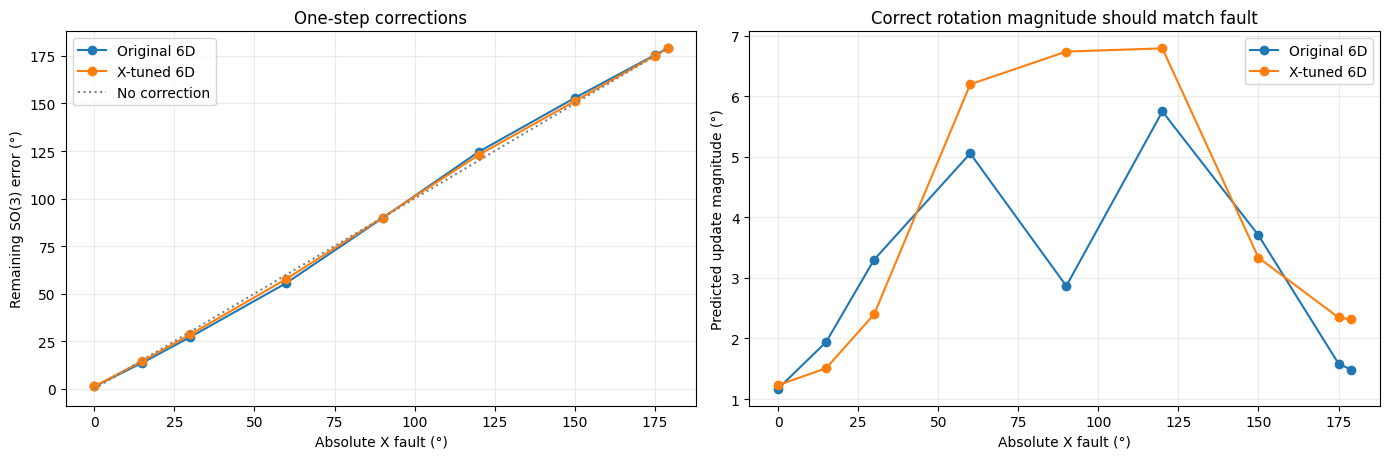

Signed-angle breakdown, important for the 179° branch ambiguity:


,model,signed_angle_deg,mean,median,size
0,Original 6D,-179.0,179.012,179.041,32
1,Original 6D,-175.0,175.526,175.423,32
2,Original 6D,-150.0,153.123,151.752,32
3,Original 6D,-120.0,125.172,122.510,32
4,Original 6D,-90.0,91.063,90.570,32
5,Original 6D,-60.0,55.678,58.147,32
6,Original 6D,-30.0,27.153,28.113,32
7,Original 6D,-15.0,13.724,13.948,32
8,Original 6D,0.0,1.170,0.902,64
9,Original 6D,15.0,13.565,13.930,32


In [15]:
from matplotlib.ticker import MaxNLocator


def make_candidate_model(path):
    candidate = PooledCalibration6DModel(model_config).to(device=DEVICE, dtype=DTYPE)
    if path in (FINETUNE_INIT_CHECKPOINT, RUN_DIR / 'best.pt', RUN_DIR / 'last.pt'):
        load_training_checkpoint(path, model=candidate, map_location=DEVICE, restore_rng_state=False)
    else:
        state = torch.load(path, map_location='cpu', weights_only=True)
        candidate.load_state_dict(state['model_state_dict'], strict=True)
    return candidate.eval().requires_grad_(False)


# Switch to 'full_best' after an optional full run and re-execute this cell and later evaluation cells.
EVAL_CANDIDATE = 'stochastic_last'  # 'stochastic_last', 'stochastic_best', 'full_best', 'full_last'
CANDIDATE_PATH = {
    'stochastic_last': STOCHASTIC_LAST_PATH,
    'stochastic_best': STOCHASTIC_BEST_PATH,
    'full_best': RUN_DIR / 'best.pt',
    'full_last': RUN_DIR / 'last.pt',
}[EVAL_CANDIDATE]
if not CANDIDATE_PATH.is_file():
    raise FileNotFoundError(f'Candidate does not exist: {CANDIDATE_PATH}. Run its training phase first.')
model_original = make_candidate_model(FINETUNE_INIT_CHECKPOINT)
model_tuned = make_candidate_model(CANDIDATE_PATH)
probe_models = {'Original 6D': model_original, 'X-tuned 6D': model_tuned}
print('Evaluation candidate:', EVAL_CANDIDATE, CANDIDATE_PATH)
probe_frames = []
for name, candidate in probe_models.items():
    frame = evaluate_probe(candidate, full_probe_batches)
    frame['model'] = name
    probe_frames.append(frame)
probe_compare = pd.concat(probe_frames, ignore_index=True)
probe_compare.to_csv(RUN_DIR / 'x_only_paired_one_step.csv', index=False)
angle_summary = probe_compare.groupby(['model', 'angle_deg'], as_index=False).agg(mean_remaining=('after_deg','mean'), median_remaining=('after_deg','median'), mean_step=('step_deg','mean'), mean_healthy_drift=('healthy_drift_deg','mean'), n=('after_deg','size'))
display(angle_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.7))
for model_name, values in angle_summary.groupby('model'):
    axes[0].plot(values.angle_deg, values.mean_remaining, '-o', label=model_name)
    axes[1].plot(values.angle_deg, values.mean_step, '-o', label=model_name)
axes[0].plot(PROBE_ANGLES_DEG, PROBE_ANGLES_DEG, ':', color='gray', label='No correction')
axes[0].set(xlabel='Absolute X fault (°)', ylabel='Remaining SO(3) error (°)', title='One-step corrections')
axes[1].set(xlabel='Absolute X fault (°)', ylabel='Predicted update magnitude (°)', title='Correct rotation magnitude should match fault')
for ax in axes: ax.legend(); ax.grid(alpha=.25)
fig.tight_layout(); fig.savefig(RUN_DIR / 'x_only_one_step_comparison.png', dpi=170)
if SHOW_PLOTS: plt.show()
else: plt.close(fig)

print('Signed-angle breakdown, important for the 179° branch ambiguity:')
display(probe_compare.groupby(['model','signed_angle_deg'],as_index=False).after_deg.agg(['mean','median','size']).round(3))

## 10. Parameter-gradient, output-space direction, and sphere diagnostics

In [16]:
# Stable geometric diagnostics. For pure +X/-X faults, signed axis cosine is meaningful
# below 180°, but can be misleading close to 180°; always check full SO(3) residual.

def rotation_vector_principal(R):
    skew = torch.stack((R[...,2,1]-R[...,1,2], R[...,0,2]-R[...,2,0], R[...,1,0]-R[...,0,1]), dim=-1)
    sin_theta = 0.5 * torch.linalg.vector_norm(skew, dim=-1)
    cos_theta = 0.5 * (R.diagonal(dim1=-2,dim2=-1).sum(-1)-1.0)
    angle = torch.atan2(sin_theta, cos_theta)
    return 0.5 * skew / sin_theta.unsqueeze(-1).clamp_min(1e-7) * angle.unsqueeze(-1)


def cosine_masked(a, b):
    an = torch.linalg.vector_norm(a, dim=-1)
    bn = torch.linalg.vector_norm(b, dim=-1)
    cos = (a*b).sum(-1) / (an*bn).clamp_min(1e-8)
    return torch.where((an>1e-6)&(bn>1e-6),cos,torch.full_like(cos,float('nan')))


def skew3(a):
    x,y,z = a.unbind(-1)
    zero = torch.zeros_like(x)
    return torch.stack((zero,-z,y,z,zero,-x,-y,x,zero),dim=-1).reshape(*a.shape[:-1],3,3)


def tangent_sphere(p, vec):
    return vec - (vec*p).sum(-1,keepdim=True)*p


GRAD60_WINDOWS = 16
GRAD60_AXIS_SEEDS = 2
GRAD60_MODELS = probe_models
GRAD60_OUTPUT_DIR = RUN_DIR / 'plots' / 'x_axis_gradients'
GRAD60_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
grad60_batches = build_probe_batches(val_dataset, n_windows=GRAD60_WINDOWS, batch_size=8, seed=VAL_AUG_SEED + 350000, axis_seeds=GRAD60_AXIS_SEEDS)
grad60_rows = []
grad60_sphere = []
south = torch.tensor([0.,0.,-1.], device=DEVICE, dtype=DTYPE)
I = torch.eye(3, device=DEVICE, dtype=DTYPE)
for model_name, candidate in GRAD60_MODELS.items():
    for cases in grad60_batches:
        for angle, (window, keys, indices, sign_id) in cases.items():
            output = model_predictions(window, model_override=candidate)
            p = output.predictions[FAULT_KEY]
            raw = p.rotation_6d.detach().clone().requires_grad_(True)
            R_pred = rotation_6d_to_matrix(raw)
            R_prior = window.current_calibration[FAULT_KEY].transform[:, :3,:3]
            R_truth = window.targets[FAULT_KEY].next_transform[:, :3,:3]
            target_R = R_truth @ R_prior.transpose(-1,-2)
            target_6 = matrix_to_rotation_6d(target_R).detach()
            rot_loss = (raw-target_6).square().mean(-1)
            grad_output = torch.autograd.grad(rot_loss.sum(), raw)[0].detach()
            target_delta = rotation_vector_principal(target_R.detach())
            predicted_delta = rotation_vector_principal(R_pred.detach())
            axis_cos = cosine_masked(predicted_delta,target_delta)
            residual = rotation_geodesic_deg(R_pred.detach(),target_R)
            # Physical tangent gradient at identity: ∂L6D/∂δ for R(δ)=Exp(δ) around identity.
            eps = torch.zeros(raw.shape[0],3,device=DEVICE,dtype=DTYPE,requires_grad=True)
            linear_R = I[None] + skew3(eps)
            start_reg = (matrix_to_rotation_6d(linear_R)-target_6).square().mean(-1)
            tangent_grad = torch.autograd.grad(start_reg.sum(),eps)[0].detach()
            relative = R_prior @ R_truth.transpose(-1,-2)
            start = (relative @ south).detach()
            ideal = tangent_sphere(start, south.expand_as(start))
            model_tangent = torch.cross(predicted_delta,start,dim=-1)
            # Tangent update induced by the negative loss gradient at identity.
            loss_tangent = torch.cross(-tangent_grad,start,dim=-1)
            cos_model_south = cosine_masked(model_tangent,ideal)
            cos_loss_south = cosine_masked(loss_tangent,ideal)
            output_grad_norm = grad_output.norm(dim=-1)
            tangent_grad_norm = tangent_grad.norm(dim=-1)
            for j in range(start.shape[0]):
                grad60_rows.append(dict(model=model_name,angle_deg=float(angle),signed_angle_deg=float(angle)*(1 if sign_id%2==0 else -1),physical_index=int(indices[j]),residual_deg=float(residual[j]),step_deg=float(rotation_geodesic_deg(R_pred[j:j+1],I[None])),axis_cosine=float(axis_cos[j]),model_cos_south=float(cos_model_south[j]),loss_cos_south=float(cos_loss_south[j]),grad_output_norm=float(output_grad_norm[j]),grad_physical_norm=float(tangent_grad_norm[j])))
                grad60_sphere.append(dict(model=model_name,angle_deg=float(angle),sign=1 if sign_id%2==0 else -1,start=start[j].cpu().numpy(),loss_tangent=loss_tangent[j].cpu().numpy(),model_tangent=model_tangent[j].cpu().numpy(),pred_end=(R_pred[j]@start[j]).detach().cpu().numpy()))

grad60_df = pd.DataFrame(grad60_rows)
grad60_df.to_csv(GRAD60_OUTPUT_DIR/'x_axis_gradient_cases.csv',index=False)
display(grad60_df.groupby(['model','angle_deg'],as_index=False)[['residual_deg','axis_cosine','model_cos_south','grad_output_norm','grad_physical_norm']].mean().round(3))

,model,angle_deg,residual_deg,axis_cosine,model_cos_south,grad_output_norm,grad_physical_norm
0,Original 6D,0.0,1.655,NaN,-0.057,0.026,0.000
1,Original 6D,15.0,12.930,0.639,0.669,0.081,0.086
2,Original 6D,30.0,25.261,0.831,0.886,0.155,0.167
3,Original 6D,60.0,51.635,0.852,0.948,0.299,0.289
4,Original 6D,90.0,90.398,0.040,0.127,0.466,0.333
5,Original 6D,120.0,128.937,-0.732,-0.810,0.578,0.289
6,Original 6D,150.0,155.061,-0.775,-0.891,0.638,0.167
7,Original 6D,175.0,175.633,-0.284,-0.363,0.669,0.029
8,Original 6D,179.0,178.929,-0.059,-0.135,0.670,0.006
9,X-tuned 6D,0.0,1.907,NaN,-0.036,0.017,0.000


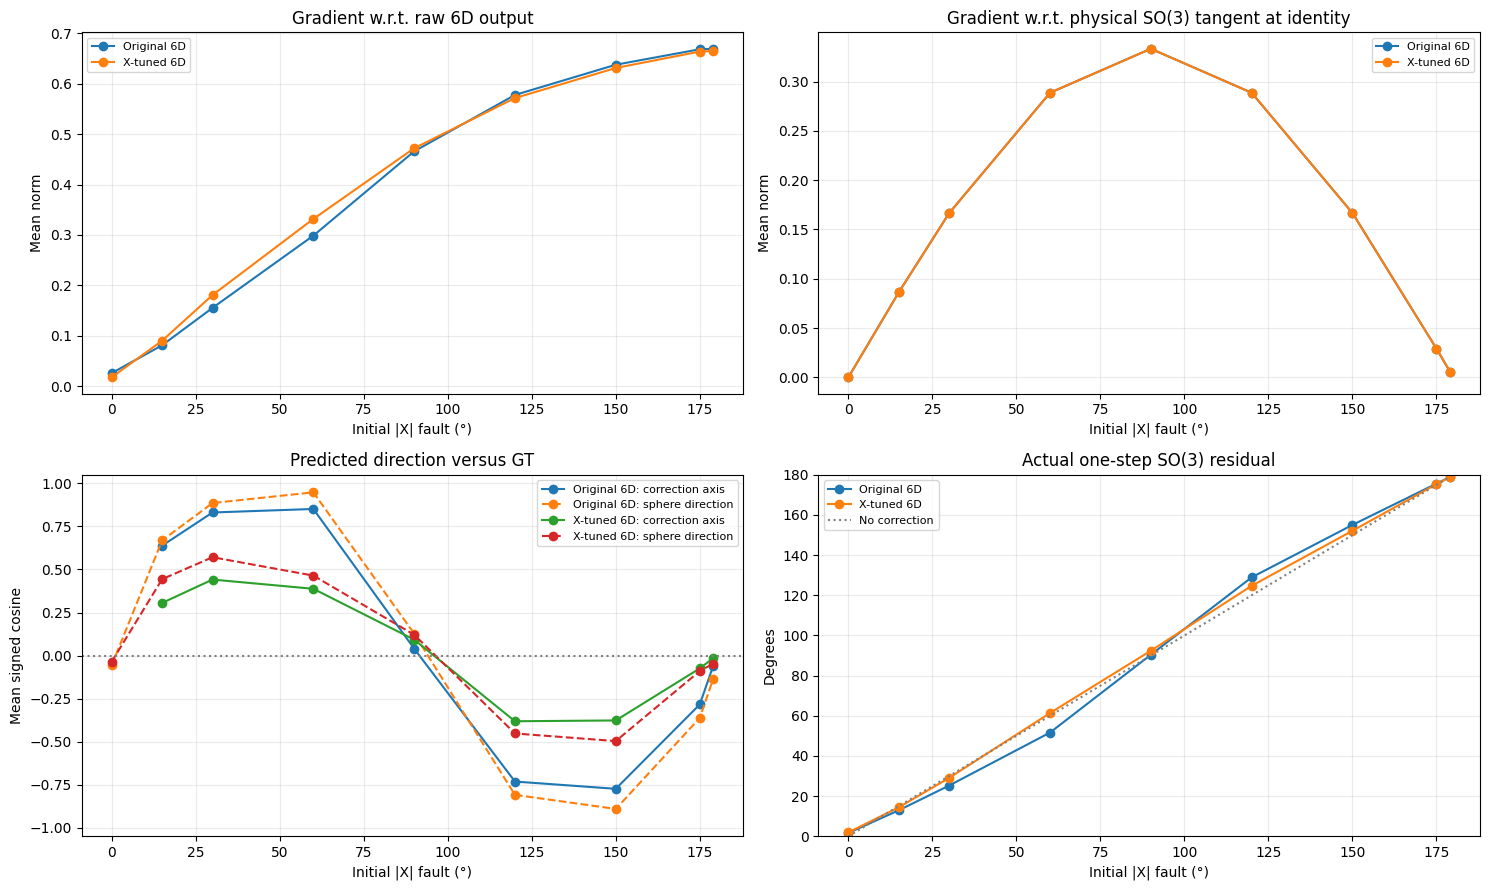

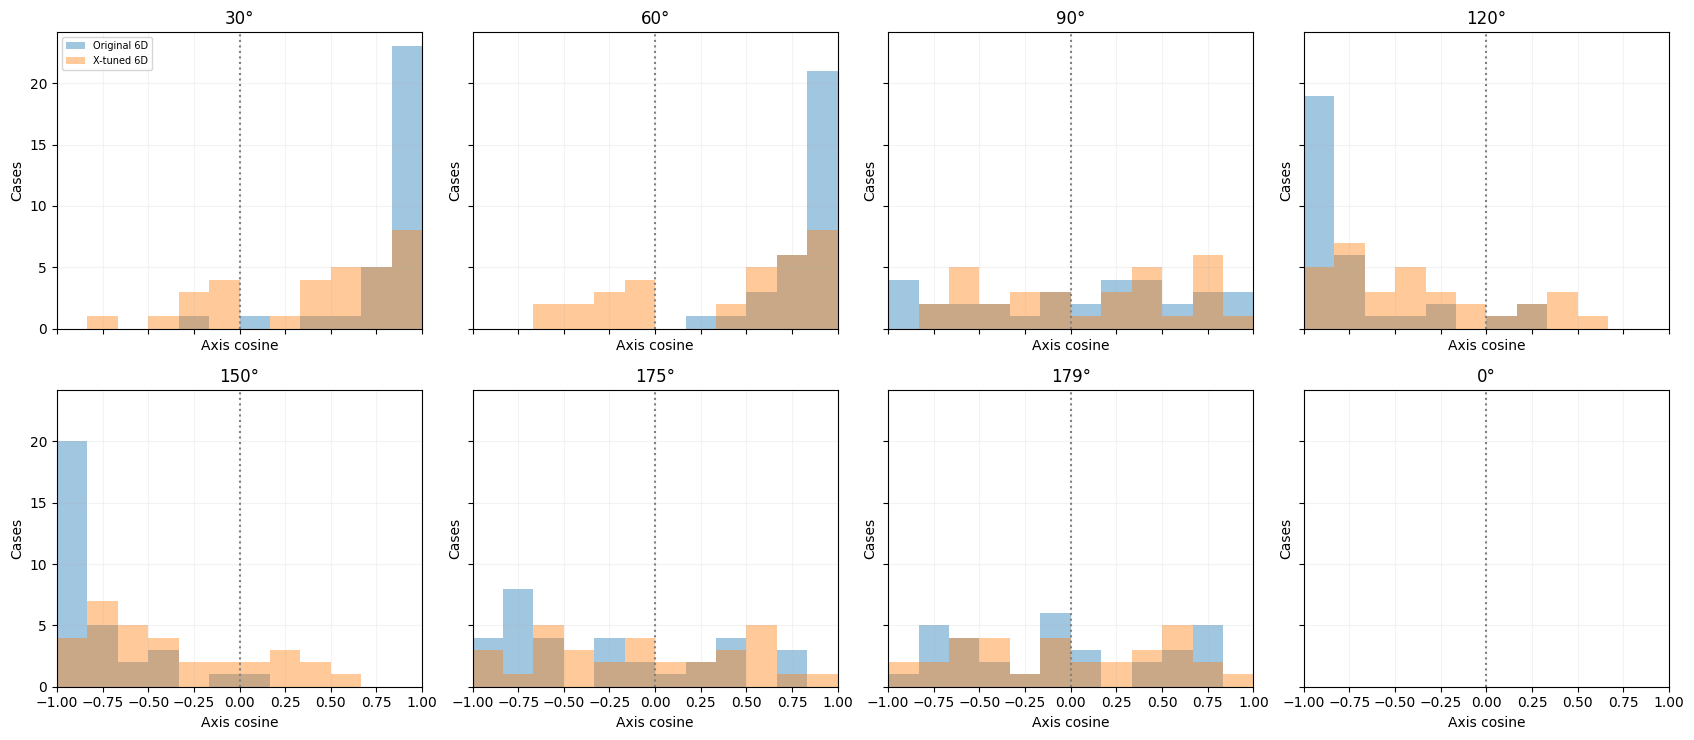

In [17]:
# Gradient norms, predicted-axis cosines, and real SO(3) errors.
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for name, group in grad60_df.groupby('model'):
    agg = group.groupby('angle_deg',as_index=False)[['grad_output_norm','grad_physical_norm','axis_cosine','model_cos_south','residual_deg']].mean()
    axes[0,0].plot(agg.angle_deg, agg.grad_output_norm, '-o', label=name)
    axes[0,1].plot(agg.angle_deg, agg.grad_physical_norm, '-o', label=name)
    axes[1,0].plot(agg.angle_deg, agg.axis_cosine, '-o', label=f'{name}: correction axis')
    axes[1,0].plot(agg.angle_deg, agg.model_cos_south, '--o', label=f'{name}: sphere direction')
    axes[1,1].plot(agg.angle_deg, agg.residual_deg, '-o', label=name)
axes[0,0].set(title='Gradient w.r.t. raw 6D output',ylabel='Mean norm',xlabel='Initial |X| fault (°)')
axes[0,1].set(title='Gradient w.r.t. physical SO(3) tangent at identity',ylabel='Mean norm',xlabel='Initial |X| fault (°)')
axes[1,0].set(title='Predicted direction versus GT',ylabel='Mean signed cosine',xlabel='Initial |X| fault (°)',ylim=(-1.05,1.05))
axes[1,0].axhline(0,color='gray',linestyle=':')
axes[1,1].set(title='Actual one-step SO(3) residual',ylabel='Degrees',xlabel='Initial |X| fault (°)',ylim=(0,180))
axes[1,1].plot(PROBE_ANGLES_DEG,PROBE_ANGLES_DEG,':',color='gray',label='No correction')
for ax in axes.flat: ax.grid(alpha=.25);ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(GRAD60_OUTPUT_DIR/'x_axis_gradient_direction_comparison.png',dpi=170)
if SHOW_PLOTS:plt.show()
else:plt.close(fig)

fig, axarr = plt.subplots(2, 4, figsize=(17, 7.5), sharex=True, sharey=True)
for ax,angle in zip(axarr.flat,(30.,60.,90.,120.,150.,175.,179.,0.)):
    for name,g in grad60_df.loc[grad60_df.angle_deg==angle].groupby('model'):
        ax.hist(g.axis_cosine.dropna(),bins=np.linspace(-1,1,13),density=False,alpha=.42,label=name)
    ax.set(title=f'{angle:g}°',xlim=(-1,1),xlabel='Axis cosine',ylabel='Cases')
    ax.axvline(0,color='gray',linestyle=':')
    ax.grid(alpha=.15)
axarr.flat[0].legend(fontsize=7)
fig.tight_layout();fig.savefig(GRAD60_OUTPUT_DIR/'x_axis_axis_cosine_histograms.png',dpi=170)
if SHOW_PLOTS:plt.show()
else:plt.close(fig)

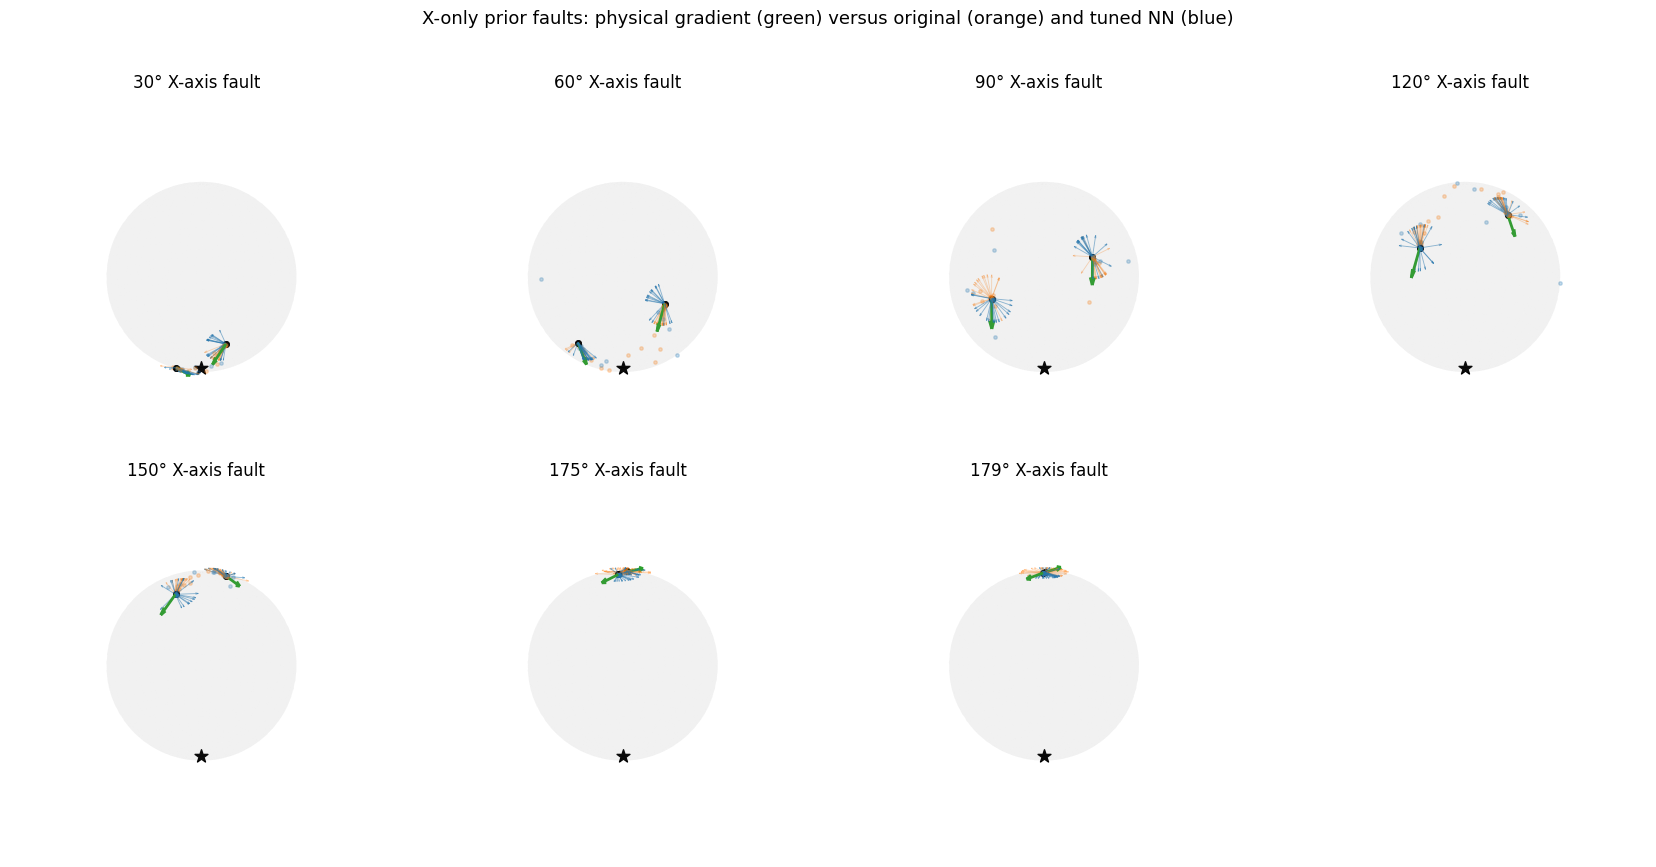

The sphere only depicts Q·south (two-dimensional projection): all conclusions about success must use full SO(3) residuals.


In [18]:
# Honest S² gravity-direction visualization for X-only rotations:
# Every angle gives two real starts (+X and -X). No artificial sweep of rotation axes.
# Orange: negative supervised loss gradient at identity, pushed to the sphere tangent.
# Blue: actual predicted instantaneous sphere update; dots: FINITE predicted endpoints.
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
SPHERE60_ANGLES_DEG = (30.,60.,90.,120.,150.,175.,179.)
fig = plt.figure(figsize=(17, 8.8))
mesh_theta=np.linspace(0,2*np.pi,70);mesh_phi=np.linspace(0,np.pi,36)
xx=np.outer(np.cos(mesh_theta),np.sin(mesh_phi));yy=np.outer(np.sin(mesh_theta),np.sin(mesh_phi));zz=np.outer(np.ones_like(mesh_theta),np.cos(mesh_phi))

for idx,angle in enumerate(SPHERE60_ANGLES_DEG):
    ax=fig.add_subplot(2,4,idx+1,projection='3d')
    ax.plot_surface(xx,yy,zz,alpha=.05,color='gray',linewidth=0,shade=False)
    ax.scatter(0,0,-1,color='black',marker='*',s=95)
    # Show the original model faintly and the tuned model clearly.
    for name,color in [('Original 6D','tab:orange'),('X-tuned 6D','tab:blue')]:
        cases=[d for d in grad60_sphere if d['angle_deg']==angle and d['model']==name]
        for sign in (-1,1):
            signed=[d for d in cases if d['sign']==sign]
            if not signed:continue
            p=signed[0]['start']
            ax.scatter(*p,color='black',s=15)
            loss_vec=np.mean([d['loss_tangent'] for d in signed],axis=0)
            if name=='X-tuned 6D' and np.linalg.norm(loss_vec)>1e-8:
                ax.quiver(*p,*(loss_vec/np.linalg.norm(loss_vec)),color='tab:green',length=.32,linewidth=2,arrow_length_ratio=.28)
            for d in signed:
                vec=d['model_tangent']
                if np.linalg.norm(vec)>1e-8:
                    ax.quiver(*p,*(vec/np.linalg.norm(vec)),color=color,length=.25,linewidth=.65,alpha=.28 if name=='Original 6D' else .5,arrow_length_ratio=.13)
                ax.scatter(*d['pred_end'],color=color,s=6,alpha=.25)
    ax.set(title=f'{angle:g}° X-axis fault',xlim=(-1.12,1.12),ylim=(-1.12,1.12),zlim=(-1.12,1.12))
    ax.set_box_aspect((1,1,1));ax.view_init(elev=15,azim=-58);ax.set_axis_off()
fig.suptitle('X-only prior faults: physical gradient (green) versus original (orange) and tuned NN (blue)',fontsize=13)
fig.tight_layout(rect=(0,0,1,.95));fig.savefig(GRAD60_OUTPUT_DIR/'x_axis_sphere_directions.png',dpi=175)
if SHOW_PLOTS:plt.show()
else:plt.close(fig)
print('The sphere only depicts Q·south (two-dimensional projection): all conclusions about success must use full SO(3) residuals.')

## 11. Chronological feedback rollouts, +X/−X, baseline versus tuned

Completed rollouts: Urban26 1
Completed rollouts: Urban28 1


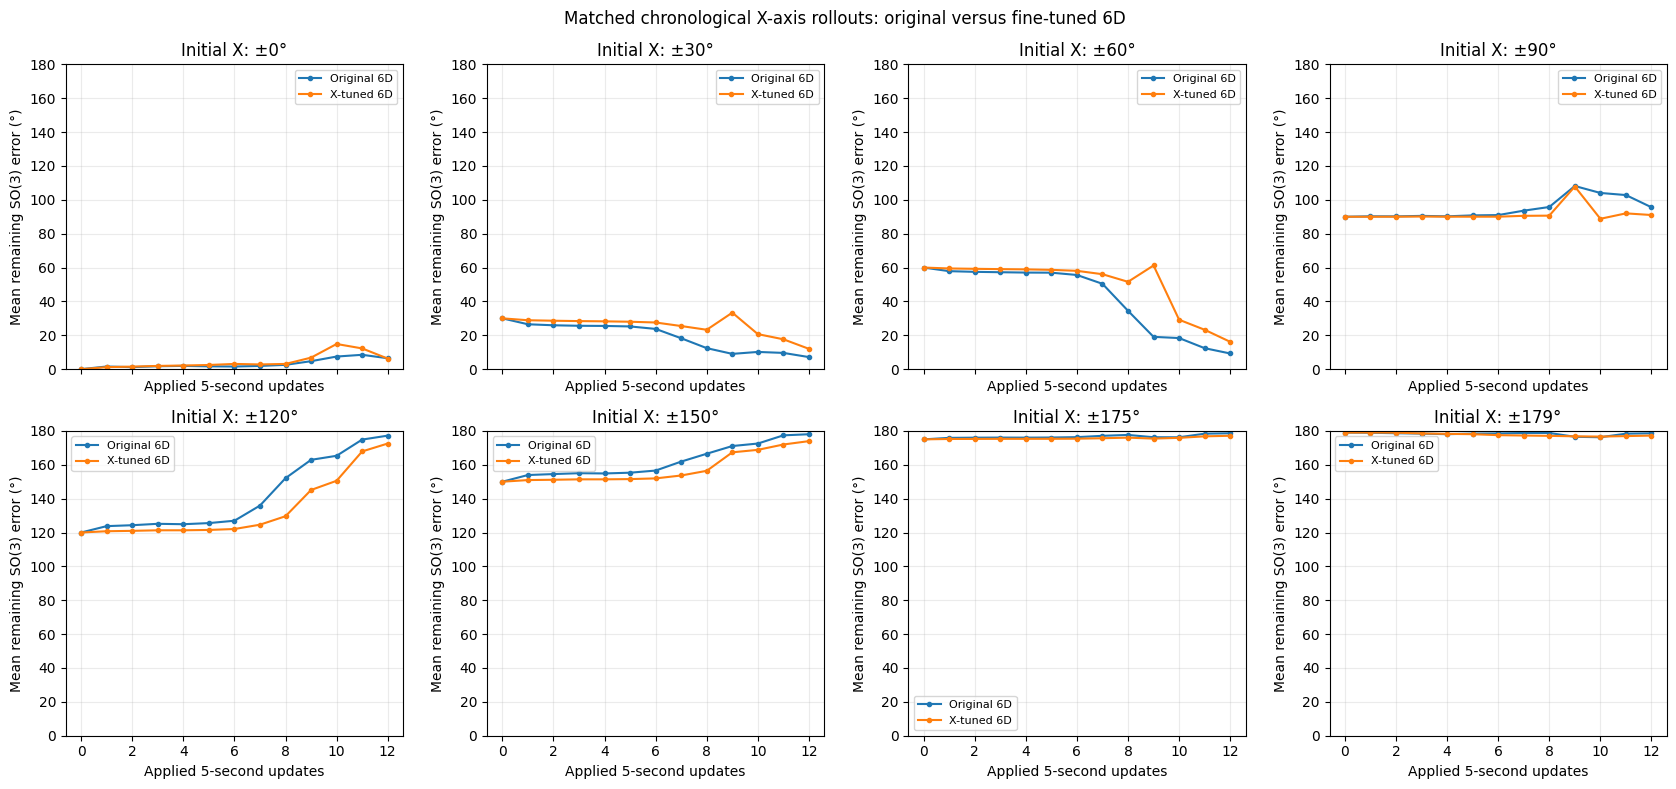

step                      0       1       3       6       12
model       angle_deg                                       
Original 6D 0.0          0.0    1.56    1.73    1.55    6.44
            30.0        30.0   26.50   25.61   23.76    7.12
            60.0        60.0   57.87   57.24   55.61    9.25
            90.0        90.0   90.25   90.51   90.98   95.59
            120.0      120.0  123.76  125.14  126.95  177.21
            150.0      150.0  153.94  155.03  156.58  178.03
            175.0      175.0  175.89  176.06  176.31  178.60
            179.0      179.0  178.90  178.41  178.51  178.59
X-tuned 6D  0.0          0.0    1.19    1.91    3.09    6.25
            30.0        30.0   28.88   28.38   27.55   11.99
            60.0        60.0   59.45   59.07   58.06   16.13
            90.0        90.0   89.99   90.13   90.04   91.02
            120.0      120.0  120.75  121.31  122.07  172.54
            150.0      150.0  150.96  151.39  151.95  173.97
            175.0      175.0  175.23  175.31  175.40  177.12
            179.0      179.0  179.05  178.49  177.49  177.23

In [19]:
# Matched chronological validation rollouts; one faulted IMU, two signs of X.
# Same physical windows, initial GT and fault for both models. Each model feeds back its own prior.
ROL60_SEQUENCES = tuple(VAL_NAMES)
ROL60_STEPS = 12
ROL60_STARTS_PER_SEQUENCE = 1
ROL60_ANGLES = (0.,30.,60.,90.,120.,150.,175.,179.)
ROL60_SIGNS = (-1, 1)
ROL60_UPDATE_ALL_KEYS = False  # Isolate X-axis IMU calibration; True also diagnoses healthy LiDAR drift.
ROL60_RUN = True


def roll60_indices(dataset, sequence):
    indices=np.asarray(dataset.window_indices_for_sequence(sequence),dtype=np.int64)
    max_start=len(indices)-ROL60_STEPS
    if max_start<0:raise ValueError(f'{sequence} has only {len(indices)} windows')
    for start in np.unique(np.linspace(0,max_start,min(ROL60_STARTS_PER_SEQUENCE,max_start+1)).round().astype(int)):
        yield indices[start:start+ROL60_STEPS]


@torch.no_grad()
def rollout_60():
    rows=[]
    for seq in ROL60_SEQUENCES:
        for start_id,indices in enumerate(roll60_indices(val_dataset,seq)):
            # The RNG resets for each window, so physical true frame augmentation is identical across time.
            raw_windows=[]
            for i in indices:
                raw=window_batch_to(collate_windows([val_dataset[int(i)]]),DEVICE,dtype=DTYPE)
                raw_windows.append(physical_augmenter(raw,generator=augmentation_generator(VAL_AUG_SEED+1)).augmented_window)
            reference=raw_windows[0].current_calibration
            for window in raw_windows[1:]:
                for key in CALIBRATION_KEYS:
                    torch.testing.assert_close(window.current_calibration[key].transform,reference[key].transform,atol=2e-5,rtol=2e-5)
            for angle in ROL60_ANGLES:
                for sign in ROL60_SIGNS if angle>0 else (1,):
                    faults={key:torch.zeros(1,6,device=DEVICE,dtype=DTYPE) for key in CALIBRATION_KEYS}
                    tau={key:torch.zeros(1,1,device=DEVICE,dtype=DTYPE) for key in CALIBRATION_KEYS}
                    faults[FAULT_KEY][:,0]=sign*np.deg2rad(angle)
                    initial=apply_independent_prior_faults(reference,faults,tau)
                    for name,candidate in probe_models.items():
                        states={key:replace(st,transform=st.transform.detach().clone(),time_offset=st.time_offset.detach().clone()) for key,st in initial.items()}
                        for step in range(ROL60_STEPS+1):
                            active=float(rotation_geodesic_deg(states[FAULT_KEY].transform[:,:3,:3],reference[FAULT_KEY].transform[:,:3,:3]).mean())
                            healthy=np.mean([float(rotation_geodesic_deg(states[k].transform[:,:3,:3],reference[k].transform[:,:3,:3]).mean()) for k in CALIBRATION_KEYS if k!=FAULT_KEY])
                            rows.append(dict(sequence=seq,start_id=start_id,angle_deg=float(angle),signed_angle_deg=float(sign*angle),model=name,step=step,active_error_deg=active,healthy_error_deg=healthy))
                            if step==ROL60_STEPS:break
                            inp=clone_with_current_calibration(raw_windows[step],states)
                            prediction=model_predictions(inp,model_override=candidate)
                            updated=apply_calibration_6d_update(states,prediction.predictions,keys_to_update=CALIBRATION_KEYS if ROL60_UPDATE_ALL_KEYS else (FAULT_KEY,))
                            # Rotation-only ablation: discard translational/clock changes produced by the untrained outputs.
                            states={key:replace(new_state,transform=torch.cat((torch.cat((new_state.transform[:,:3,:3],states[key].transform[:,:3,3:4]),dim=-1),states[key].transform[:,3:4,:]),dim=-2),time_offset=states[key].time_offset) for key,new_state in updated.items()}
            print('Completed rollouts:',seq,start_id+1,flush=True)
    return pd.DataFrame(rows)

if ROL60_RUN:
    roll60_df=rollout_60()
    roll60_df.to_csv(RUN_DIR/'x_only_chronological_rollouts.csv',index=False)
    roll60_summary=roll60_df.groupby(['model','angle_deg','step'],as_index=False).agg(mean_error=('active_error_deg','mean'),median_error=('active_error_deg','median'),n=('active_error_deg','size'))
    fig,axes=plt.subplots(2,4,figsize=(17,8),squeeze=False,sharex=True)
    for ax,angle in zip(axes.flat,ROL60_ANGLES):
        for name in probe_models:
            curve=roll60_summary[(roll60_summary.model==name)&(roll60_summary.angle_deg==angle)].sort_values('step')
            ax.plot(curve.step,curve.mean_error,'-o',markersize=3,label=name)
        ax.set(title=f'Initial X: ±{angle:g}°',xlabel='Applied 5-second updates',ylabel='Mean remaining SO(3) error (°)',ylim=(0,180))
        ax.grid(alpha=.25);ax.legend(fontsize=8)
    fig.suptitle('Matched chronological X-axis rollouts: original versus fine-tuned 6D')
    fig.tight_layout();fig.savefig(RUN_DIR/'x_only_rollout_comparison.png',dpi=175)
    if SHOW_PLOTS:plt.show()
    else:plt.close(fig)
    display(roll60_summary[roll60_summary.step.isin((0,1,3,6,ROL60_STEPS))].pivot_table(index=['model','angle_deg'],columns='step',values='mean_error').round(2))
else:
    print('Chronological rollouts disabled.')

## 12. Full training (optional, after examining stochastic and rollout diagnostics)

Once full training finishes, set `EVAL_CANDIDATE = 'full_best'` in Section 9 and rerun Sections 9–11 for the trained checkpoint.

In [22]:
def run_6d_epoch(loader, *, training, generator, max_batches=None):
    model.train(training)
    sums, counts = defaultdict(float), defaultdict(float)
    n_samples, optimizer_updates = 0, 0
    pending_samples, pending_microbatches = 0, 0
    started = time.perf_counter()
    if training:
        optimizer.zero_grad(set_to_none=True)

    def optimizer_flush():
        nonlocal pending_samples, pending_microbatches, optimizer_updates
        if pending_samples == 0:
            return
        for p in model.parameters():
            if p.grad is not None:
                p.grad.div_(pending_samples)
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
        optimizer.step()
        optimizer.zero_grad(set_to_none=True)
        optimizer_updates += 1
        pending_samples, pending_microbatches = 0, 0

    with (torch.enable_grad() if training else torch.no_grad()):
        for batch_id, cpu_batch in enumerate(loader):
            if max_batches is not None and batch_id >= max_batches:
                break
            base = window_batch_to(cpu_batch, DEVICE, dtype=DTYPE)
            augmented = make_training_window(base, generator=generator)
            prediction = model_predictions(augmented)
            loss, metrics = compute_6d_objective(augmented, prediction)
            n = len(next(iter(augmented.current_calibration.values())).transform)
            if training:
                (loss * n).backward()
                pending_samples += n
                pending_microbatches += 1
                if pending_microbatches >= GRADIENT_ACCUMULATION_STEPS:
                    optimizer_flush()
            for key, value in metrics.items():
                if key == 'active_rotation_count':
                    continue
                sums[key] += float(value) * n
                counts[key] += n
            n_samples += n
            del base, augmented, prediction, loss
        if training:
            optimizer_flush()
    if not n_samples:
        raise RuntimeError('Epoch used no samples')
    result = metric_average(sums, counts)
    result.update(n_samples=n_samples, optimizer_updates=optimizer_updates, elapsed_s=time.perf_counter()-started)

    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return result


BEST_CHECKPOINT_PATH, LAST_CHECKPOINT_PATH = RUN_DIR / 'best.pt', RUN_DIR / 'last.pt'
HISTORY_PATH = RUN_DIR / 'training_6d_history.csv'
checkpoint_config = dict(run_name=RUN_NAME, architecture='PooledCalibration6DModel', calibration_keys=CALIBRATION_KEYS, source_checkpoint=str(FINETUNE_INIT_CHECKPOINT), head_mlp_lr=HEAD_MLP_LR, transformer_lr=TRANSFORMER_LR, batch_size=BATCH_SIZE, gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS, loss_weights=asdict(LOSS_WEIGHTS), active_weight=ACTIVE_ROTATION_SUPERVISION_WEIGHT, fine_max_deg=FINE_ROTATION_MAX_DEG, rotation_axes=X_AXIS_MASK, fault_key=FAULT_KEY, coarse_range_deg=(COARSE_ROTATION_MIN_DEG, COARSE_ROTATION_MAX_DEG), coarse_probability=COARSE_PRIOR_PROBABILITY, translation_prior_m=PRIOR_TRANSLATION_MAX_M, fine_coarse_imu_only=True, tau_reference_s=REFINED_TAU_BY_SENSOR_S, train_names=tuple(TRAIN_NAMES), val_names=tuple(VAL_NAMES), probe_angles=PROBE_ANGLES_DEG, probe_windows=PROBE_WINDOWS, probe_score_angles=PROBE_SCORE_ANGLES_DEG, zero_drift_weight=ZERO_DRIFT_WEIGHT)
train_generator = augmentation_generator(TRAIN_AUG_SEED)
start_epoch, global_step, best_score, best_epoch = 0, 0, float('inf'), 0
history=[]
if RESUME_FULL_TRAINING:
    if not LAST_CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(LAST_CHECKPOINT_PATH)
    metadata = torch.load(LAST_CHECKPOINT_PATH, map_location='cpu', weights_only=False)
    extra = metadata.get('extra_state') or {}
    if extra.get('config_6d') != checkpoint_config:
        raise RuntimeError('6D resume configuration differs; use a new RUN_NAME rather than resuming')
    loaded = load_training_checkpoint(LAST_CHECKPOINT_PATH, model=model, optimizer=optimizer, scheduler=scheduler, generators={'train_shuffle': train_shuffle_generator, 'train_aug': train_generator}, map_location=DEVICE, restore_rng_state=True)
    start_epoch, global_step = int(loaded.get('epoch', 0)), int(loaded.get('global_step', 0))
    best_score, best_epoch = float(extra['best_probe_score']), int(extra.get('best_epoch',0))
    if HISTORY_PATH.is_file():
        history=pd.read_csv(HISTORY_PATH).to_dict('records')
    print('Resumed exact 6D run at epoch', start_epoch)
else:
    if RUN_FULL_TRAINING and any(p.exists() for p in (BEST_CHECKPOINT_PATH, LAST_CHECKPOINT_PATH, HISTORY_PATH)):
        raise FileExistsError('Run files already exist; choose a new RUN_NAME or RESUME_FULL_TRAINING=True')
    if LOAD_STOCHASTIC_CANDIDATE_FOR_FULL:
        if not STOCHASTIC_BEST_PATH.is_file():
            raise FileNotFoundError(STOCHASTIC_BEST_PATH)
        candidate = torch.load(STOCHASTIC_BEST_PATH, map_location='cpu', weights_only=True)
        model.load_state_dict(candidate['model_state_dict'], strict=True)
        print('Explicitly initialized from stochastic candidate step', candidate['step'])
    else:
        print('Initialized full run from original trained 6D checkpoint; preflight restored.')


def save_6d_checkpoint(path, epoch, metrics):
    save_training_checkpoint(path, model=model, optimizer=optimizer, scheduler=scheduler, epoch=epoch, global_step=global_step, metrics=metrics, generators={'train_shuffle':train_shuffle_generator, 'train_aug':train_generator}, extra_state={'config_6d': checkpoint_config, 'best_probe_score':best_score, 'best_epoch':best_epoch})

Initialized full run from original trained 6D checkpoint; preflight restored.


In [ ]:
# Notebook 60: one-cell switch to FULL training on ALL sensors, one X/Y/Z fault per sample.
# INSERT AFTER the cell defining run_6d_epoch() / save_6d_checkpoint(),
# and IMMEDIATELY BEFORE the cell starting `if RUN_FULL_TRAINING:`.
# Requires the second-stochastic SETTINGS cell (make_multi_training_window, build_multi_probe_cases).
# No changes to the original single-axis augmentation or stochastic cells are necessary.

# CONFIGURATION ----------------------------------------------------------------
FULL_MULTI_INIT_MODE = 'original'  # 'original': all sensors from step zero; 'all_xyz_best': warm-start from BOTH stochastic phases.
FULL_MULTI_RUN_NAME = 'kaist_pooled_calibration_6d_002.30_all_sensors_single_axis_xyz'
FULL_MULTI_BATCH_SIZE = 32
FULL_MULTI_EPOCHS = 100
FULL_MULTI_HEAD_LR = 1e-4
FULL_MULTI_TRANSFORMER_LR = 1e-5
FULL_MULTI_PROBE_WINDOWS = 16
FULL_MULTI_PROBE_BATCH_SIZE = 16
FULL_MULTI_PROBE_EVERY_EPOCHS = 1
FULL_MULTI_PROBE_SEED = VAL_AUG_SEED + 2026000
FULL_MULTI_STAGE = 'all_xyz'

# Continuation settings. TARGET_EPOCHS is the TOTAL number of epochs, not additional epochs.
FULL_MULTI_RESUME = True
FULL_MULTI_TARGET_EPOCHS = 100  # Example: 30 completed epochs + 20 more.

assert FULL_MULTI_INIT_MODE in ('original', 'all_xyz_best')
assert FULL_MULTI_STAGE in multi_perturbers
assert tuple(MULTI_KEYS) == tuple(CALIBRATION_KEYS)
assert tuple(MULTI_AXES) == ('X', 'Y', 'Z')
assert MULTI_IDENTITY_PROBABILITY > 0.0
# The original single-axis resume path is deliberately not used here.
assert not RESUME_FULL_TRAINING, 'Set RESUME_FULL_TRAINING=False in the notebook header; this cell handles mixed-XYZ resume.'

# 1. For a new run, initialize the complete network, including its 6D head.
# For resume, do NOT reload the original checkpoint. We will restore last.pt later,
# including its model, optimizer and scheduler state.
FULL_MULTI_SOURCE_PATH = FINETUNE_INIT_CHECKPOINT if FULL_MULTI_INIT_MODE == 'original' else MULTI_CHECKPOINTS['all_xyz']
if not FULL_MULTI_RESUME:
    if FULL_MULTI_INIT_MODE == 'original':
        load_training_checkpoint(FULL_MULTI_SOURCE_PATH, model=model, map_location=DEVICE, restore_rng_state=False)
    else:
        if not FULL_MULTI_SOURCE_PATH.is_file():
            raise FileNotFoundError(FULL_MULTI_SOURCE_PATH)
        loaded_state = torch.load(FULL_MULTI_SOURCE_PATH, map_location='cpu', weights_only=True)
        model.load_state_dict(loaded_state['model_state_dict'], strict=True)
        del loaded_state
model.freeze_feature_extractor(False)
model.head_6d.requires_grad_(True)
assert all(parameter.requires_grad for parameter in model.parameters())

# 2. FULL-RUN SAMPLING: one sensor (uniformly sampled), one Cartesian axis (uniformly
# sampled), signed angle, 50/50 fine/coarse, and 10% completely healthy priors.
# The sampler is EXACTLY the same function used for the 'all_xyz' stochastic phase.
@torch.no_grad()
def make_training_window(base_window, *, generator):
    augmented, _ = make_multi_training_window(base_window, generator=generator, stage=FULL_MULTI_STAGE)
    return augmented

# 3. BALANCED FULL-RUN PROBES: 3 sensors x 3 axes x 2 signs, same physical windows.
# The old full_probe_batches used a single fault key and X axis, which must not
# determine checkpoint selection for all-sensor training.
full_grid_cases = build_multi_probe_cases(
    val_dataset,
    n_windows=FULL_MULTI_PROBE_WINDOWS,
    batch_size=FULL_MULTI_PROBE_BATCH_SIZE,
    seed=FULL_MULTI_PROBE_SEED,
    angles=PROBE_ANGLES_DEG,
)
full_probe_batches = [cases for _, _, cases in full_grid_cases]
assert len(full_probe_batches) == 3 * 3 * 2 * math.ceil(min(FULL_MULTI_PROBE_WINDOWS, len(val_dataset)) / FULL_MULTI_PROBE_BATCH_SIZE)

# Save original generic helper functions, including when this cell is re-executed.
full_grid_pair_history = []  # Loaded from the prior run when resuming.

if '_base60_evaluate_probe' not in globals():
    _base60_evaluate_probe = evaluate_probe
    _base60_summarize_probe = summarize_probe
    _base60_probe_score = probe_score


def evaluate_probe(candidate, batches):
    if batches is not full_probe_batches:
        return _base60_evaluate_probe(candidate, batches)
    pieces = []
    for key, axis, cases in full_grid_cases:
        frame = _base60_evaluate_probe(candidate, [cases])
        frame['axis'] = axis
        pieces.append(frame)
    frame = pd.concat(pieces, ignore_index=True)
    active = frame.loc[frame.angle_deg.isin(PROBE_SCORE_ANGLES_DEG) & (frame.angle_deg > 0.0)]
    pair_metrics = active.groupby(['fault_key', 'axis'], as_index=False).agg(
        remaining_ratio=('relative_remaining', 'mean'),
        remaining_deg=('after_deg', 'mean'),
        fraction_improving=('improved', 'mean'),
    )
    near_pi = frame.loc[frame.angle_deg == 179.0].groupby(['fault_key', 'axis'], as_index=False).agg(residual_179_deg=('after_deg', 'mean'))
    pair_metrics = pair_metrics.merge(near_pi, on=['fault_key', 'axis'], how='left', validate='one_to_one')
    pair_metrics['epoch'] = int(globals().get('epoch', -1)) + 1 if RUN_FULL_TRAINING else 0
    pair_metrics['global_step'] = int(globals().get('global_step', 0))
    full_grid_pair_history.extend(pair_metrics.to_dict('records'))
    if RUN_FULL_TRAINING:
        pd.DataFrame(full_grid_pair_history).to_csv(RUN_DIR / 'sensor_axis_validation_history.csv', index=False)
    return frame


def summarize_probe(frame):
    summary = _base60_summarize_probe(frame)
    if {'axis', 'fault_key'}.issubset(frame.columns):
        active = frame.loc[frame.angle_deg.isin(PROBE_SCORE_ANGLES_DEG) & (frame.angle_deg > 0)]
        pair_ratio = active.groupby(['fault_key', 'axis']).relative_remaining.mean()
        if len(pair_ratio) != 9:
            raise RuntimeError(f'Incomplete full-run sensor-axis grid: {len(pair_ratio)}/9 pairs.')
        summary['all_xyz_mean_ratio'] = float(pair_ratio.mean())
        summary['all_xyz_worst_ratio'] = float(pair_ratio.max())
    return summary


def probe_score(summary):
    if 'all_xyz_mean_ratio' not in summary:
        return _base60_probe_score(summary)
    mean_ratio = float(summary.all_xyz_mean_ratio.iloc[0])
    worst_ratio = float(summary.all_xyz_worst_ratio.iloc[0])
    zero = summary.loc[np.isclose(summary.angle_deg, 0.0), 'final_deg']
    drift0 = float(zero.mean()) if len(zero) else 0.0
    return mean_ratio + 0.25 * (worst_ratio - mean_ratio) + ZERO_DRIFT_WEIGHT * drift0 / 30.0

# 4. Reset output paths, optimizer, scheduler, and history for this new run.
RUN_NAME = FULL_MULTI_RUN_NAME
RUN_DIR = ROOT / 'runs' / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT_PATH = RUN_DIR / 'best.pt'
LAST_CHECKPOINT_PATH = RUN_DIR / 'last.pt'
HISTORY_PATH = RUN_DIR / 'training_6d_history.csv'
if FULL_MULTI_RESUME:
    if not LAST_CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(f'Mixed-XYZ last checkpoint not found: {LAST_CHECKPOINT_PATH}')
elif any(path.is_file() for path in (BEST_CHECKPOINT_PATH, LAST_CHECKPOINT_PATH, HISTORY_PATH)):
    raise FileExistsError(f'{RUN_DIR} already contains a run. Set FULL_MULTI_RESUME=True to continue it.')

BATCH_SIZE = FULL_MULTI_BATCH_SIZE
NUM_EPOCHS = FULL_MULTI_EPOCHS
HEAD_MLP_LR = FULL_MULTI_HEAD_LR
TRANSFORMER_LR = FULL_MULTI_TRANSFORMER_LR
PROBE_EVERY_EPOCHS = FULL_MULTI_PROBE_EVERY_EPOCHS
GRADIENT_ACCUMULATION_STEPS = 1
LOAD_STOCHASTIC_CANDIDATE_FOR_FULL = False
RESUME_FULL_TRAINING = False

train_shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED)
train_loader = make_kaist_dataloader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=DROP_LAST_TRAIN, num_workers=NUM_WORKERS, generator=train_shuffle_generator)
val_loader = make_kaist_dataloader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)
optimizer = torch.optim.AdamW(parameter_groups(model), weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=LR_REDUCE_FACTOR, patience=LR_PATIENCE_EPOCHS)
train_generator = augmentation_generator(TRAIN_AUG_SEED)
start_epoch, global_step, best_score, best_epoch = 0, 0, float('inf'), 0
history = []

# 5. Replace the stale Notebook 60 single-IMU/X metadata before checkpoints are saved.
checkpoint_config.update({
    'run_name': RUN_NAME,
    'source_checkpoint': str(FULL_MULTI_SOURCE_PATH),
    'initialization_mode': FULL_MULTI_INIT_MODE,
    'fault_key': 'one_uniformly_selected_sensor',
    'fault_keys': tuple(CALIBRATION_KEYS),
    'rotation_axes': (True, True, True),
    'one_calibration_per_sample': True,
    'one_rotation_axis_per_sample': True,
    'fine_coarse_imu_only': False,
    'coarse_probability': MULTI_COARSE_PROBABILITY,
    'identity_probability': MULTI_IDENTITY_PROBABILITY,
    'head_mlp_lr': HEAD_MLP_LR,
    'transformer_lr': TRANSFORMER_LR,
    'batch_size': BATCH_SIZE,
    'probe_windows': FULL_MULTI_PROBE_WINDOWS,
    'probe_axes': tuple(MULTI_AXES),
    'probe_signs': ('+', '-'),
    'probe_checkpoint_score': 'pair_mean + 0.25 * (pair_worst - pair_mean) + zero_drift_weight * drift_deg / 30',
})

# 6. Resume all saved training state, or run the original initialization probe.
if FULL_MULTI_RESUME:
    # Only load checkpoints created by your own trusted training run.
    raw_checkpoint = torch.load(LAST_CHECKPOINT_PATH, map_location='cpu', weights_only=False)
    saved_extra = raw_checkpoint.get('extra_state') or {}
    saved_config = saved_extra.get('config_6d')
    if saved_config is None:
        raise RuntimeError('last.pt has no config_6d metadata. Cannot verify that this is the same experiment.')
    if saved_config != checkpoint_config:
        differences = {
            key: (saved_config.get(key, '<missing>'), checkpoint_config.get(key, '<missing>'))
            for key in set(saved_config) | set(checkpoint_config)
            if saved_config.get(key, '<missing>') != checkpoint_config.get(key, '<missing>')
        }
        raise RuntimeError(f'Resume config differs from the checkpoint. Fix the setup, do not silently change the run: {differences}')
    if 'best_probe_score' not in saved_extra:
        raise RuntimeError('last.pt is missing the previous best score.')
    del raw_checkpoint

    restored = load_training_checkpoint(
        LAST_CHECKPOINT_PATH,
        model=model,
        optimizer=optimizer,
        scheduler=scheduler,
        generators={'train_shuffle': train_shuffle_generator, 'train_aug': train_generator},
        map_location=DEVICE,
        restore_rng_state=True,
    )
    start_epoch = int(restored['epoch'])
    global_step = int(restored['global_step'])
    best_score = float(saved_extra['best_probe_score'])
    best_epoch = int(saved_extra.get('best_epoch', 0))
    NUM_EPOCHS = int(FULL_MULTI_TARGET_EPOCHS)
    if NUM_EPOCHS <= start_epoch:
        raise ValueError(f'Target {NUM_EPOCHS} must exceed completed epoch {start_epoch}.')
    if not HISTORY_PATH.is_file():
        raise FileNotFoundError(f'Cannot append training history because {HISTORY_PATH} is missing.')
    history_frame = pd.read_csv(HISTORY_PATH)
    if 'epoch' not in history_frame.columns:
        raise RuntimeError('Previous history is missing its epoch column.')
    # In an interrupted save, a CSV can be one epoch ahead of last.pt.
    history_frame = history_frame.loc[history_frame['epoch'] <= start_epoch].copy()
    if history_frame.empty or int(history_frame['epoch'].iloc[-1]) != start_epoch:
        raise RuntimeError(f'CSV history does not contain the saved epoch {start_epoch}.')
    history = history_frame.to_dict('records')
    pair_history_path = RUN_DIR / 'sensor_axis_validation_history.csv'
    if pair_history_path.is_file():
        pair_frame = pd.read_csv(pair_history_path)
        if 'epoch' in pair_frame.columns:
            pair_frame = pair_frame.loc[pair_frame['epoch'] <= start_epoch]
        full_grid_pair_history = pair_frame.to_dict('records')
    del history_frame, restored

    print(f'RESUMED {RUN_NAME}: epochs completed={start_epoch}, target={NUM_EPOCHS}, updates={global_step}')
    print(f'Previous best: epoch {best_epoch}, score {best_score:.5f}')
    print('Optimizer LR restored:', [(group['name'], group['lr']) for group in optimizer.param_groups])
    print('AdamW state entries restored:', len(optimizer.state))
    if not optimizer.state:
        raise RuntimeError('Optimizer state is EMPTY after loading last.pt; this would not be a real AdamW resume.')
    print('Scheduler state restored:', scheduler.state_dict())
    print('Checkpoint:', LAST_CHECKPOINT_PATH)
else:
    # Matched 9-task score at the START, before the first optimizer update.
    base_grid = evaluate_probe(model, full_probe_batches)
    base_summary = summarize_probe(base_grid)
    print('Initial all-XYZ score:', round(probe_score(base_summary), 4))
    print('Initial mean/worst pair ratios:', round(float(base_summary.all_xyz_mean_ratio.iloc[0]), 3), round(float(base_summary.all_xyz_worst_ratio.iloc[0]), 3))
    print('Initial ±179° SO(3) residuals by sensor and axis:')
    print(base_grid.loc[base_grid.angle_deg == 179.0].groupby(['fault_key', 'axis']).after_deg.mean().unstack('axis').round(1).to_string())
    print('Source (full network including 6D head):', FULL_MULTI_SOURCE_PATH)

# Common diagnostics for new and resumed runs.

print('Training sensor/axis: UNIFORM over imu/lidar/lidar_right and X/Y/Z')
print('Fine/coarse/identity:', 1.0 - MULTI_COARSE_PROBABILITY, MULTI_COARSE_PROBABILITY, MULTI_IDENTITY_PROBABILITY)
print('LR:', [(item['name'], item['lr']) for item in optimizer.param_groups])
print('Output:', RUN_DIR)

RUN_FULL_TRAINING = True
print('Ready: run the NEXT cell `if RUN_FULL_TRAINING:`; it continues at epoch', start_epoch + 1)


RESUMED kaist_pooled_calibration_6d_002.30_all_sensors_single_axis_xyz: epochs completed=68, target=100, updates=4216
Previous best: epoch 64, score 0.54335
Optimizer LR restored: [('transformer', 1e-05), ('pooler_mlp_head', 0.0001)]
AdamW state entries restored: 164
Scheduler state restored: {'factor': 0.5, 'default_min_lr': 0, 'min_lrs': [0, 0], 'patience': 10, 'cooldown': 0, 'cooldown_counter': 0, 'mode': 'min', 'threshold': 0.0001, 'threshold_mode': 'rel', 'eps': 1e-08, 'last_epoch': 68, '_last_lr': [1e-05, 0.0001], 'mode_worse': inf, 'best': 0.1338268243239827, 'num_bad_epochs': 0}
Checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.30_all_sensors_single_axis_xyz/last.pt
Training sensor/axis: UNIFORM over imu/lidar/lidar_right and X/Y/Z
Fine/coarse/identity: 0.5 0.5 0.1
LR: [('transformer', 1e-05), ('pooler_mlp_head', 0.0001)]
Output: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.30_all

In [26]:

if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

In [27]:
if RUN_FULL_TRAINING:
    for epoch in range(start_epoch, NUM_EPOCHS):
        train_shuffle_generator.manual_seed(RANDOM_SEED + 12001 + epoch)
        train = run_6d_epoch(train_loader, training=True, generator=train_generator, max_batches=MAX_TRAIN_BATCHES_PER_EPOCH)
        val = run_6d_epoch(val_loader, training=False, generator=augmentation_generator(VAL_AUG_SEED), max_batches=MAX_VAL_BATCHES_PER_EPOCH)
        scheduler.step(val['loss_total'])
        improved = False
        global_step += train['optimizer_updates']
        row = dict(epoch=epoch+1, global_step=global_step, train_loss=train['loss_total'], val_loss=val['loss_total'], train_rotation_6d=train['loss_rotation_6d'], val_rotation_6d=val['loss_rotation_6d'], train_rotation_chordal=train['loss_rotation_chordal'], val_rotation_chordal=val['loss_rotation_chordal'], train_translation=train['loss_translation'], val_translation=val['loss_translation'], train_tau=train['loss_tau'], val_tau=val['loss_tau'], train_active_deg=train['active_rotation_error_deg'], val_active_deg=val['active_rotation_error_deg'], head_mlp_lr=optimizer.param_groups[1]['lr'], transformer_lr=optimizer.param_groups[0]['lr'])
        if (epoch+1) % PROBE_EVERY_EPOCHS == 0:
            probe = evaluate_probe(model, full_probe_batches)
            summary = summarize_probe(probe)
            score = probe_score(summary)
            row['probe_score'] = score
            for angle in PROBE_ANGLES_DEG:
                sub=summary.loc[summary.angle_deg==angle].iloc[0]
                row[f'probe_{int(angle)}_final_deg'] = float(sub.final_deg)
                row[f'probe_{int(angle)}_improves'] = float(sub.fraction_improving)
            if score < best_score:
                improved = True
                best_score, best_epoch = score, epoch+1
                save_6d_checkpoint(BEST_CHECKPOINT_PATH, epoch+1, row)
                # print('New best angular probe checkpoint at epoch', best_epoch, '| score',round(score,4))
        history.append(row)
        pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)
        save_6d_checkpoint(LAST_CHECKPOINT_PATH, epoch+1, row)
        angles_report=', '.join(f'{int(a)}°={row[f"probe_{int(a)}_final_deg"]:.1f}°' for a in (0.0,30.0,60.0,90.0,120.0,150.0,175.0,179.0)) if 'probe_score' in row else 'not evaluated'
        print(f'Epoch {epoch+1:3d}/{NUM_EPOCHS} train={train["loss_total"]:.4f} val={val["loss_total"]:.4f} | fixed probe: {angles_report} | LR={row["head_mlp_lr"]:.1e}/{row["transformer_lr"]:.1e}'+ (" BEST" if improved else ""), flush=True)
else:
    print('Full training disabled.')

Epoch  69/100 train=0.1630 val=0.1354 | fixed probe: not evaluated | LR=1.0e-04/1.0e-05
Epoch  70/100 train=0.1410 val=0.1354 | fixed probe: 0°=1.1°, 30°=13.8°, 60°=32.5°, 90°=38.3°, 120°=39.4°, 150°=49.7°, 175°=67.8°, 179°=96.1° | LR=1.0e-04/1.0e-05
Epoch  71/100 train=0.1524 val=0.1343 | fixed probe: not evaluated | LR=1.0e-04/1.0e-05
Epoch  72/100 train=0.1532 val=0.1431 | fixed probe: 0°=1.0°, 30°=15.0°, 60°=31.2°, 90°=37.1°, 120°=39.8°, 150°=50.8°, 175°=65.1°, 179°=96.9° | LR=1.0e-04/1.0e-05
Epoch  73/100 train=0.1501 val=0.1342 | fixed probe: not evaluated | LR=1.0e-04/1.0e-05
Epoch  74/100 train=0.1488 val=0.1395 | fixed probe: 0°=1.0°, 30°=13.2°, 60°=30.3°, 90°=36.5°, 120°=41.3°, 150°=51.2°, 175°=66.5°, 179°=98.0° | LR=1.0e-04/1.0e-05 BEST
Epoch  75/100 train=0.1678 val=0.1372 | fixed probe: not evaluated | LR=1.0e-04/1.0e-05
Epoch  76/100 train=0.1597 val=0.1314 | fixed probe: 0°=1.3°, 30°=15.0°, 60°=32.2°, 90°=38.3°, 120°=39.2°, 150°=49.1°, 175°=67.3°, 179°=95.6° | LR=1.0e-04

## 13. Post-training XYZ checkpoint comparison: original vs full best
Execute these five cells in order after the preceding full-training cell has saved RUN_DIR / "best.pt".

They create two independent, frozen models with all 6D weights restored, evaluate identical held-out physical windows, and compare each of the nine sensor–axis pairs in both signed directions. Evaluation uses a new fixed validation augmentation seed and never updates model weights.
- One-step: SO(3) residual, correction magnitude, predicted/GT signed rotation-axis cosine and its near-179° distribution, healthy-sensor predicted drift, paired CSVs.
- Chronological feedback: twelve 5-second windows per trajectory with rotation-only updates to the faulted sensor. Each checkpoint has independent feedback, but the input trajectories and initial faults are matched.
- Outputs: RUN_DIR/plots/post_training_xyz_comparison/*.csv and *.png.
Interpretation: near 179°, a signed principal-axis cosine can be misleading because opposite 179° axes represent nearby rotations. Judge correction quality with full SO(3) residuals and convergence, not cosine alone. By default, these are validation results; keep the test sequences untouched until final model selection.

In [28]:
# Notebook 60 — post-training evaluation, CELL 1/5: checkpoints and matched evaluation settings.
# Run AFTER full training has produced RUN_DIR / 'best.pt'. Does not touch the training model or optimizer.

EVAL61_ORIGINAL_PATH = Path(FINETUNE_INIT_CHECKPOINT)   # Expected: .../002.28_coarse_120_179_finetune/best.pt
EVAL61_FULL_BEST_PATH = Path(RUN_DIR) / 'best.pt'
EVAL61_DIR = Path(RUN_DIR) / 'plots' / 'post_training_xyz_comparison'
EVAL61_DIR.mkdir(parents=True, exist_ok=True)

# Both models see the very same held-out physical windows, randomized true frames, axes and signs.
EVAL61_DATASET = val_dataset  # Do not select the final test split during iterative analysis.
EVAL61_ANGLES = (0.0, 15.0, 30.0, 60.0, 90.0, 120.0, 150.0, 175.0, 179.0)
EVAL61_KEYS = ('imu', 'lidar', 'lidar_right')
EVAL61_AXES = ('X', 'Y', 'Z')
EVAL61_WINDOWS = 32
EVAL61_BATCH_SIZE = 8
EVAL61_SEED = VAL_AUG_SEED + 3_100_000

# Chronological rollout: identical sequences and initial faults for both checkpoints.
EVAL61_ROLLOUT_SEQUENCES = tuple(VAL_NAMES)     # Both held-out validation sequences by default.
EVAL61_ROLLOUT_STARTS = 1                      # Increase to 2–3 for additional motion diversity.
EVAL61_ROLLOUT_TRUTHS = 1                      # Increase to 2–3 for randomized true frames.
EVAL61_ROLLOUT_STEPS = 12
EVAL61_ROLLOUT_ANGLES = (0.0, 30.0, 60.0, 90.0, 120.0, 150.0, 175.0, 179.0)
EVAL61_ROLLOUT_SEED = VAL_AUG_SEED + 3_200_000
EVAL61_ROLLOUT_PLOT_ANGLES = (30.0, 90.0, 150.0, 179.0)
EVAL61_RUN_ROLLOUTS = True

assert tuple(CALIBRATION_KEYS) == EVAL61_KEYS
assert tuple(MULTI_AXES) == EVAL61_AXES, 'Run the mixed-XYZ settings cell first.'
assert all(0.0 <= angle < 180.0 for angle in EVAL61_ANGLES + EVAL61_ROLLOUT_ANGLES)
for checkpoint_path in (EVAL61_ORIGINAL_PATH, EVAL61_FULL_BEST_PATH):
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f'Checkpoint missing: {checkpoint_path}')
if EVAL61_ORIGINAL_PATH.resolve() == EVAL61_FULL_BEST_PATH.resolve():
    raise ValueError('Original and full-best checkpoint paths must differ.')


def eval61_load_model(checkpoint_path):
    """Construct a fresh, frozen copy with all Transformer/pooler/MLP/6D-head weights loaded."""
    candidate = PooledCalibration6DModel(model_config).to(device=DEVICE, dtype=DTYPE)
    load_training_checkpoint(checkpoint_path, model=candidate, map_location=DEVICE, restore_rng_state=False)
    return candidate.eval().requires_grad_(False)


EVAL61_MODELS = {
    'Original': eval61_load_model(EVAL61_ORIGINAL_PATH),
    'Full best': eval61_load_model(EVAL61_FULL_BEST_PATH),
}
changed = [(a - b).square().sum().item() for a, b in zip(EVAL61_MODELS['Original'].parameters(), EVAL61_MODELS['Full best'].parameters())]
print('Original (all 6D weights):', EVAL61_ORIGINAL_PATH)
print('Full-run best:', EVAL61_FULL_BEST_PATH)
print('Parameter L2 difference:', math.sqrt(sum(changed)))
print('Evaluation: 3 sensors × 3 axes × both signs ×', len(EVAL61_ANGLES), 'one-step angles')
print('Chronological rollouts:', EVAL61_ROLLOUT_STEPS, 'steps; sequences=', EVAL61_ROLLOUT_SEQUENCES)


Original (all 6D weights): /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.27_full_rotation_regression/best.pt
Full-run best: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.30_all_sensors_single_axis_xyz/best.pt
Parameter L2 difference: 5.635239498587267
Evaluation: 3 sensors × 3 axes × both signs × 9 one-step angles
Chronological rollouts: 12 steps; sequences= ('Urban26', 'Urban28')


In [29]:
# Notebook 60 — post-training evaluation, CELL 2/5: paired one-step XYZ corrections and cosines.
# IMPORTANT: signed rotation-axis cosine can flip close to 180°; SO(3) residual is the success metric.


def eval61_axis_cosine(predicted_R, target_R):
    """Signed principal rotation-axis cosine, undefined for zero-angle rotations."""
    def skew(R):
        return torch.stack((R[..., 2, 1] - R[..., 1, 2], R[..., 0, 2] - R[..., 2, 0], R[..., 1, 0] - R[..., 0, 1]), dim=-1)
    a, b = skew(predicted_R), skew(target_R)
    na, nb = torch.linalg.vector_norm(a, dim=-1), torch.linalg.vector_norm(b, dim=-1)
    cosine = (a * b).sum(dim=-1) / (na * nb).clamp_min(1e-12)
    return torch.where((na > 1e-5) & (nb > 1e-5), cosine.clamp(-1, 1), torch.full_like(cosine, torch.nan))


@torch.inference_mode()
def eval61_one_step():
    """Test all sensor/axis/sign combinations using the same physical cases for both checkpoints."""
    cases = build_multi_probe_cases(EVAL61_DATASET, n_windows=EVAL61_WINDOWS, batch_size=EVAL61_BATCH_SIZE, seed=EVAL61_SEED, angles=EVAL61_ANGLES)
    rows = []
    for task_id, (key, axis, axis_cases) in enumerate(cases):
        for angle, (window, keys, indices, sign_id) in axis_cases.items():
            if angle == 0.0 and sign_id == 1:
                continue  # Avoid counting the same zero-fault example twice.
            signed_angle = float(angle) * (+1.0 if sign_id == 0 else -1.0)
            truth_R = window.targets[key].next_transform[:, :3, :3]
            prior_R = window.current_calibration[key].transform[:, :3, :3]
            required_R = truth_R @ prior_R.transpose(-1, -2)
            start_error = rotation_geodesic_deg(prior_R, truth_R)
            if not torch.allclose(start_error, torch.full_like(start_error, abs(signed_angle)), atol=0.07, rtol=0):
                raise AssertionError(f'{key}/{axis}/{signed_angle:g}: incorrect injected fault {start_error.tolist()}')
            for label, candidate in EVAL61_MODELS.items():
                output = model_predictions(window, model_override=candidate).predictions
                predicted_R = output[key].delta_rotation
                final_error = rotation_geodesic_deg(predicted_R @ prior_R, truth_R)
                predicted_step = rotation_geodesic_deg(predicted_R, torch.eye(3, device=DEVICE, dtype=DTYPE).expand_as(predicted_R))
                cosine = eval61_axis_cosine(predicted_R, required_R)
                healthy_predicted_drift = torch.stack([
                    rotation_geodesic_deg(output[healthy].delta_rotation, torch.eye(3, device=DEVICE, dtype=DTYPE).expand_as(output[healthy].delta_rotation))
                    for healthy in EVAL61_KEYS if healthy != key
                ]).mean(dim=0)
                if not bool(torch.isfinite(final_error).all()):
                    raise FloatingPointError(f'Non-finite one-step error: {label}, {key}, {axis}, {signed_angle:g}')
                for j, index in enumerate(indices):
                    c = float(cosine[j])
                    rows.append(dict(model=label, fault_key=key, axis=axis, signed_angle_deg=signed_angle, angle_deg=float(angle), physical_index=int(index),
                                     before_deg=float(start_error[j]), after_deg=float(final_error[j]), predicted_step_deg=float(predicted_step[j]),
                                     axis_cosine=c, abs_axis_cosine=abs(c), improvement_deg=float(start_error[j] - final_error[j]),
                                     relative_remaining=float(final_error[j] / start_error[j]) if float(start_error[j]) > 1e-3 else np.nan,
                                     healthy_predicted_drift_deg=float(healthy_predicted_drift[j])))
        if (task_id + 1) % 6 == 0 or task_id + 1 == len(cases):
            print(f'One-step sensor-axis-sign groups completed: {task_id + 1}/{len(cases)}', flush=True)
    return pd.DataFrame.from_records(rows)


EVAL61_ONE_DF = eval61_one_step()
EVAL61_ONE_DF.to_csv(EVAL61_DIR / 'one_step_individual.csv', index=False)
EVAL61_ONE_SUMMARY = EVAL61_ONE_DF.groupby(['model', 'fault_key', 'axis', 'signed_angle_deg', 'angle_deg'], as_index=False).agg(
    mean_residual_deg=('after_deg', 'mean'), median_residual_deg=('after_deg', 'median'), p90_residual_deg=('after_deg', lambda x: x.quantile(.9)),
    mean_step_deg=('predicted_step_deg', 'mean'), mean_axis_cosine=('axis_cosine', 'mean'), mean_abs_axis_cosine=('abs_axis_cosine', 'mean'),
    success_10deg=('after_deg', lambda x: (x < 10).mean()), success_30deg=('after_deg', lambda x: (x < 30).mean()), n=('after_deg', 'size'))
EVAL61_ONE_SUMMARY.to_csv(EVAL61_DIR / 'one_step_summary_signed.csv', index=False)

# Pair individual original/full-best results by actual held-out physical window and fault, not by separately sampled conditions.
case_index = ['fault_key', 'axis', 'signed_angle_deg', 'physical_index']
paired = EVAL61_ONE_DF.pivot(index=case_index, columns='model', values='after_deg').dropna()
assert len(paired) * len(EVAL61_MODELS) == len(EVAL61_ONE_DF), 'Paired cases are not one-to-one.'
paired['improvement_best_minus_original_deg'] = paired['Original'] - paired['Full best']
paired.reset_index().to_csv(EVAL61_DIR / 'one_step_paired_improvement.csv', index=False)

print('One-step remaining angle at ±179°, averaged across signs:')
display(EVAL61_ONE_DF[EVAL61_ONE_DF.angle_deg == 179.0].groupby(['model', 'fault_key', 'axis']).after_deg.mean().unstack('axis').round(2))
print('Per-task relative residuals (mean over positive/negative faults excluding zero):')
display(EVAL61_ONE_DF[EVAL61_ONE_DF.angle_deg > 0].groupby(['model', 'fault_key', 'axis']).relative_remaining.mean().unstack('axis').round(3))
print('Mean paired error reduction, positive means full best improved on the original:')
display(paired.groupby(level=['fault_key', 'axis']).improvement_best_minus_original_deg.mean().unstack('axis').round(2))


One-step sensor-axis-sign groups completed: 6/72
One-step sensor-axis-sign groups completed: 12/72
One-step sensor-axis-sign groups completed: 18/72
One-step sensor-axis-sign groups completed: 24/72
One-step sensor-axis-sign groups completed: 30/72
One-step sensor-axis-sign groups completed: 36/72
One-step sensor-axis-sign groups completed: 42/72
One-step sensor-axis-sign groups completed: 48/72
One-step sensor-axis-sign groups completed: 54/72
One-step sensor-axis-sign groups completed: 60/72
One-step sensor-axis-sign groups completed: 66/72
One-step sensor-axis-sign groups completed: 72/72
One-step remaining angle at ±179°, averaged across signs:


axis                        X       Y       Z
model     fault_key                          
Full best imu          123.62   32.23  126.48
          lidar         75.86   43.05   98.29
          lidar_right   93.26   39.99   88.92
Original  imu          167.22   51.65  171.27
          lidar        178.97  126.48   80.39
          lidar_right  178.85  124.87   80.70

Per-task relative residuals (mean over positive/negative faults excluding zero):


axis                       X      Y      Z
model     fault_key                       
Full best imu          0.216  0.154  0.670
          lidar        0.837  0.176  0.225
          lidar_right  0.846  0.206  0.254
Original  imu          0.425  0.219  0.738
          lidar        0.975  0.407  0.391
          lidar_right  0.980  0.407  0.383

Mean paired error reduction, positive means full best improved on the original:


axis,X,Y,Z
fault_key,,,
imu,29.08,8.96,24.86
lidar,32.24,31.48,16.76
lidar_right,30.64,31.36,17.29


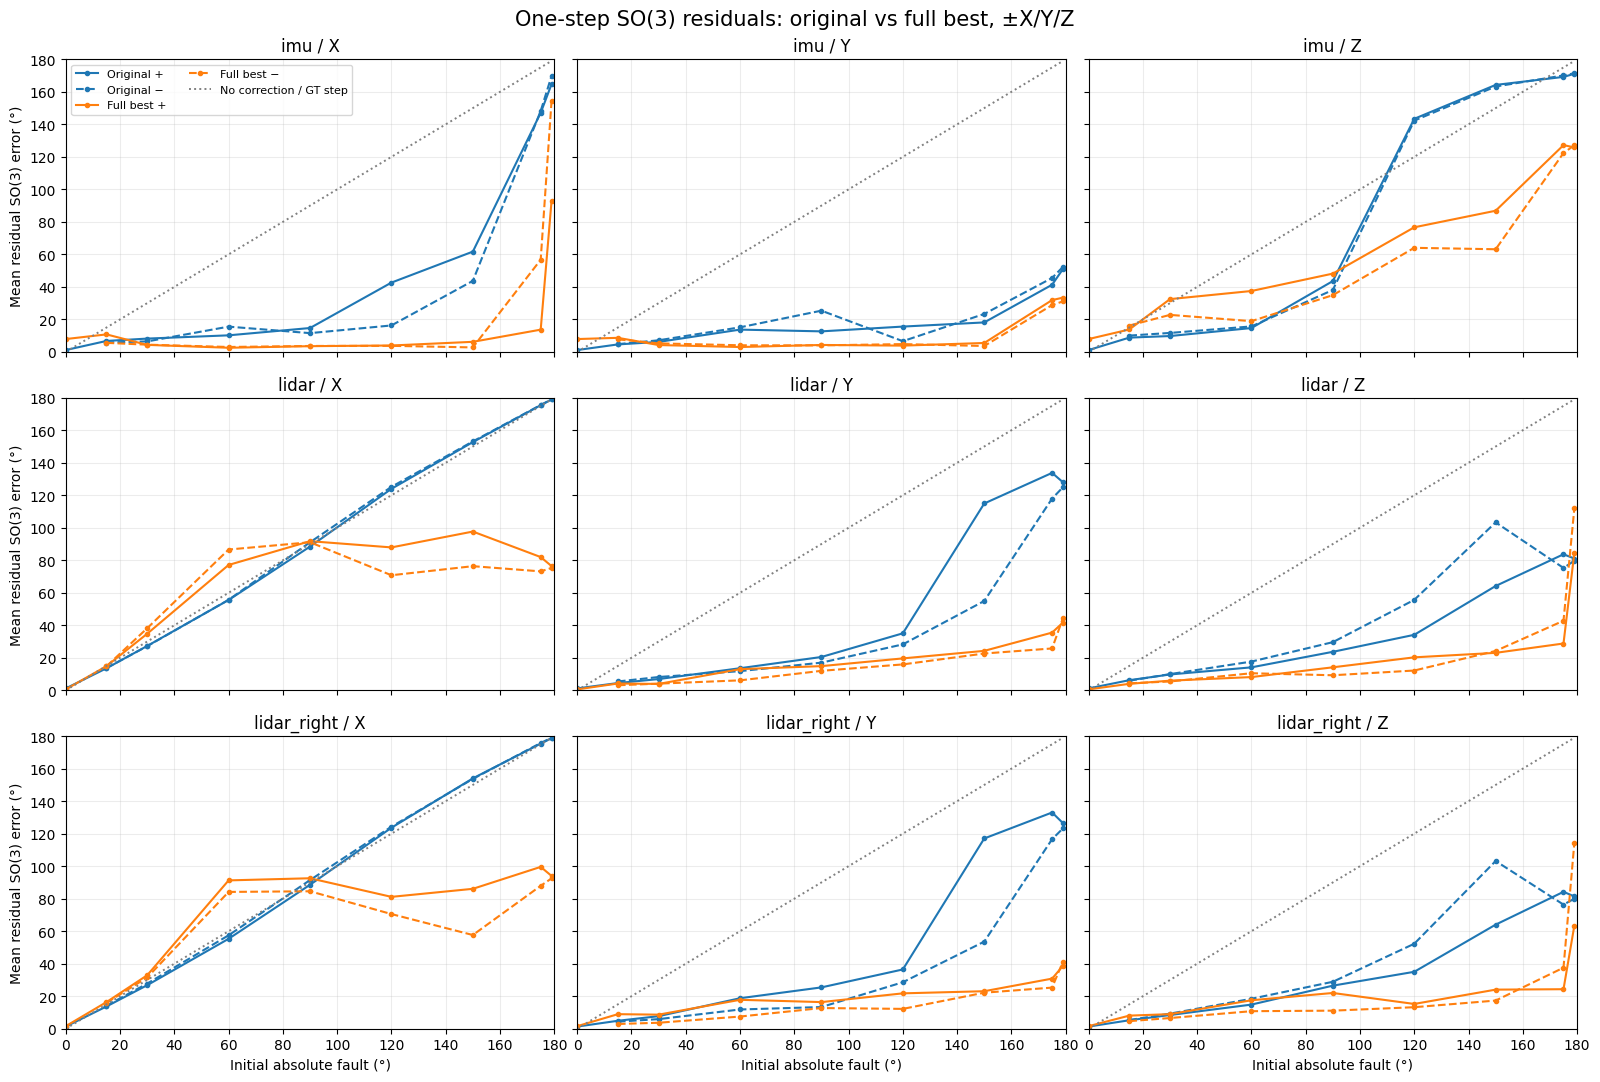

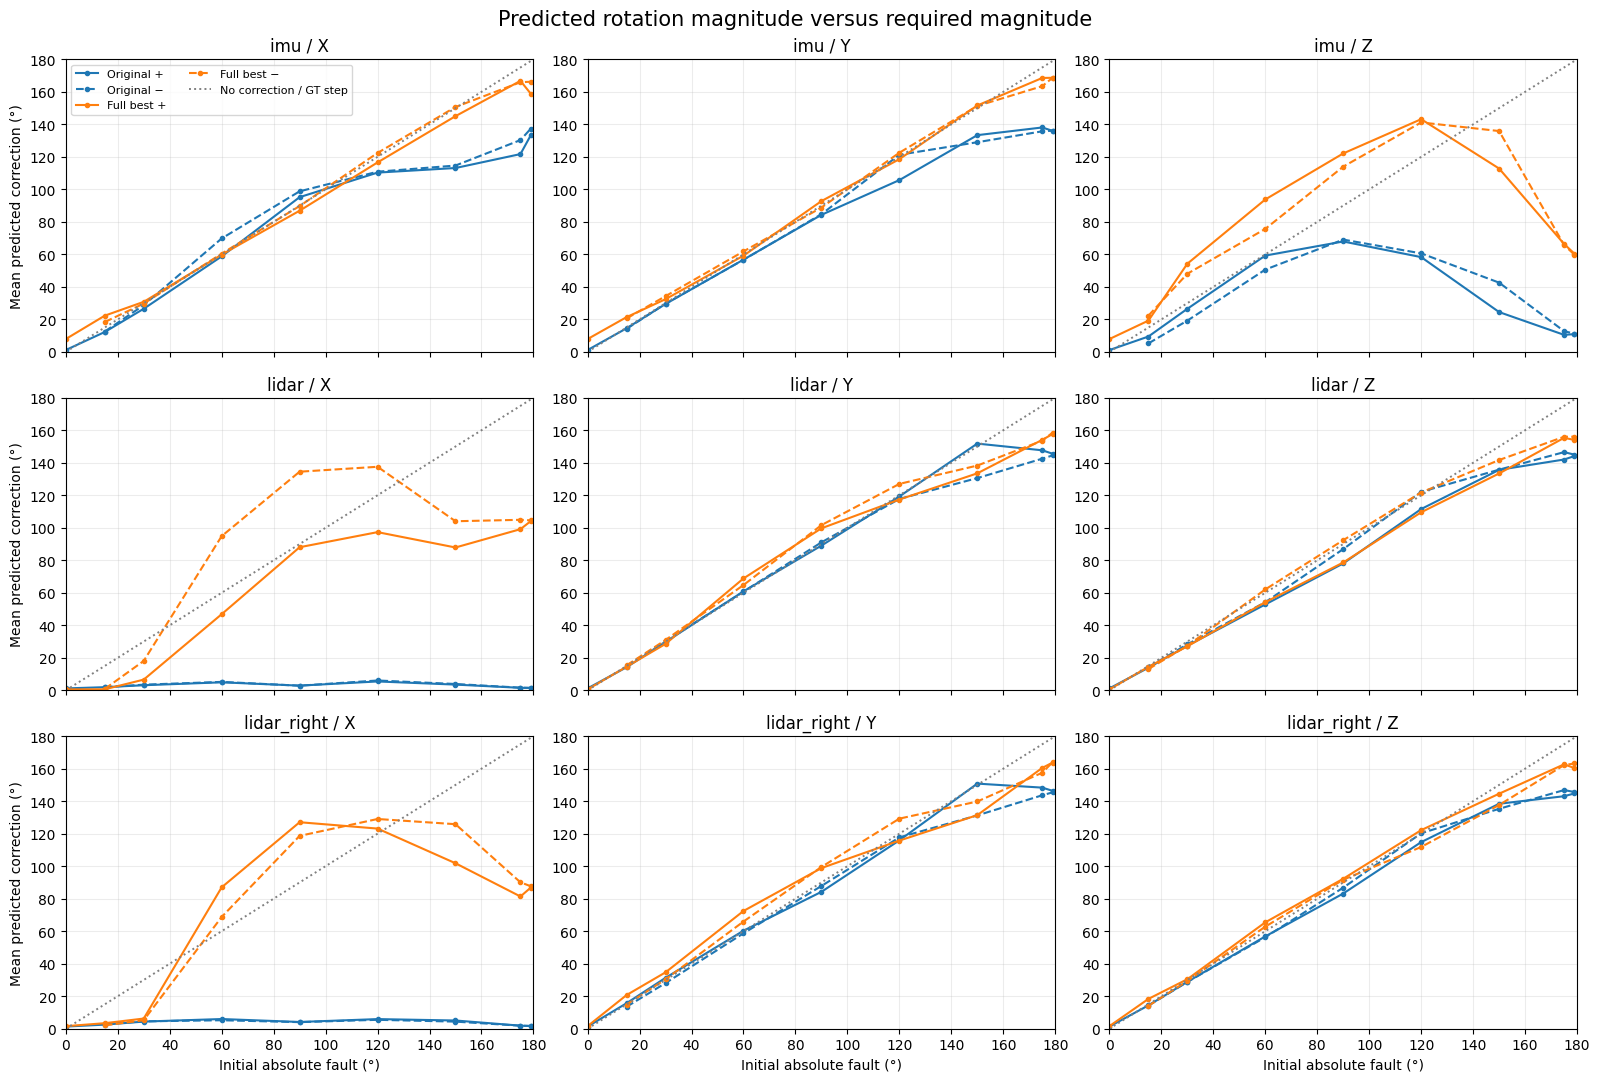

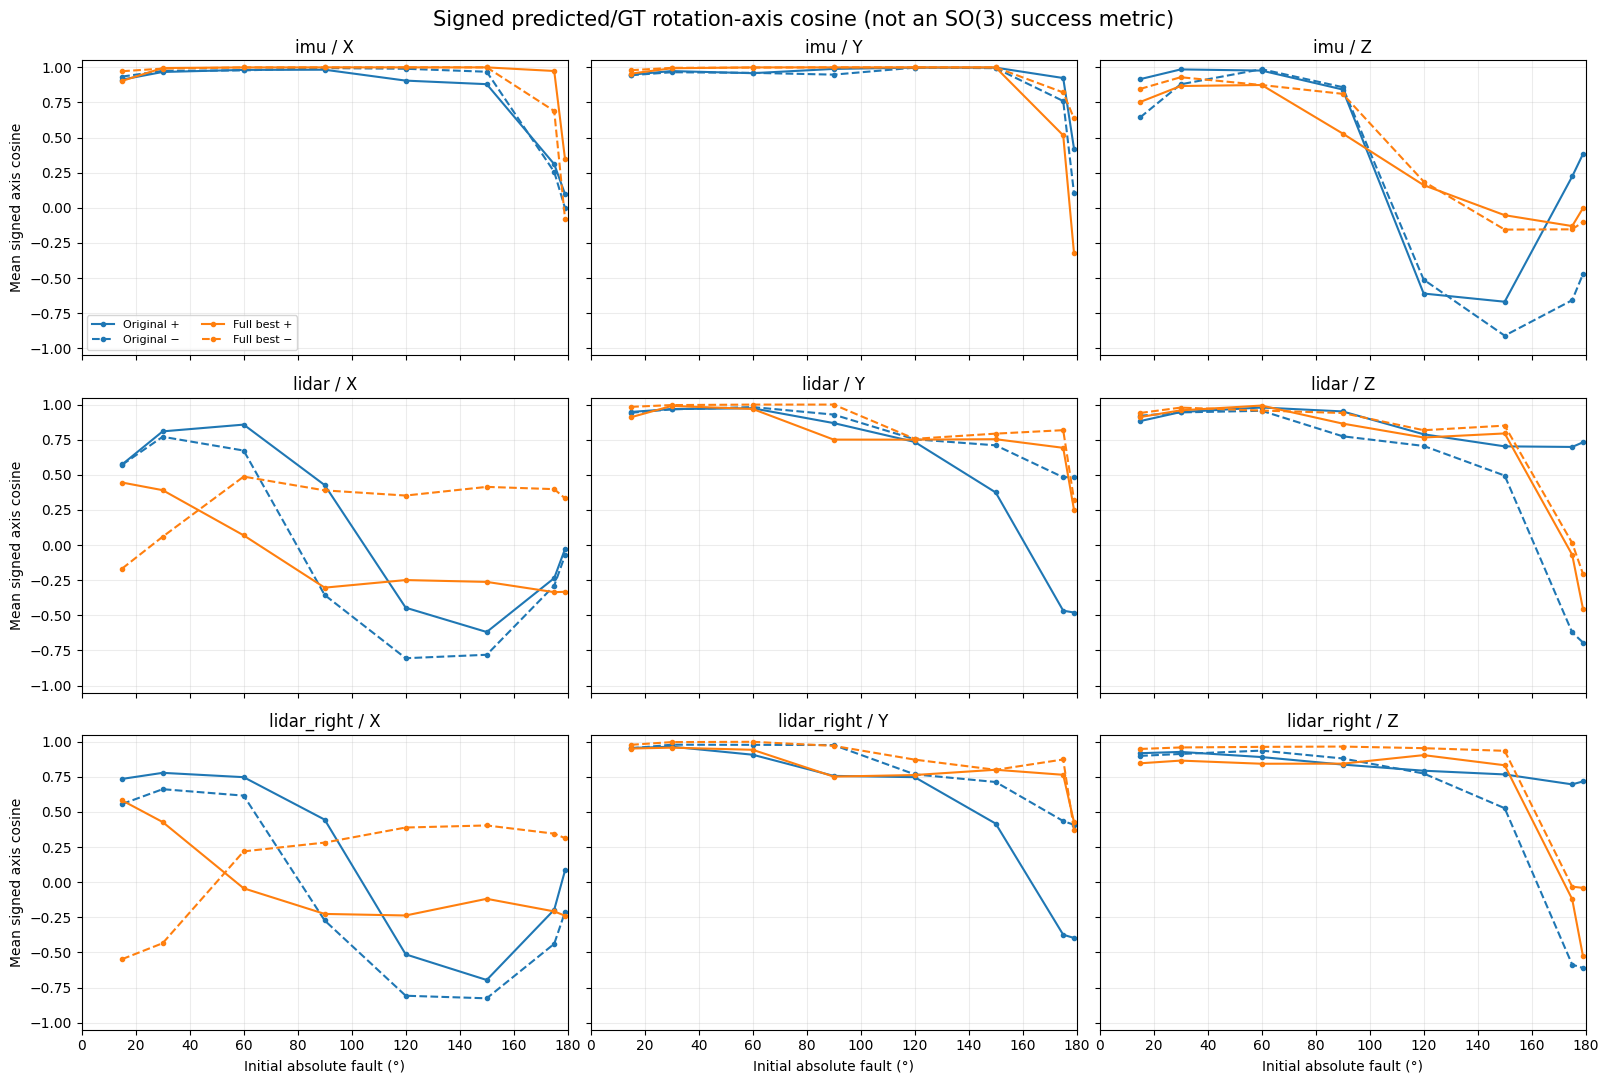

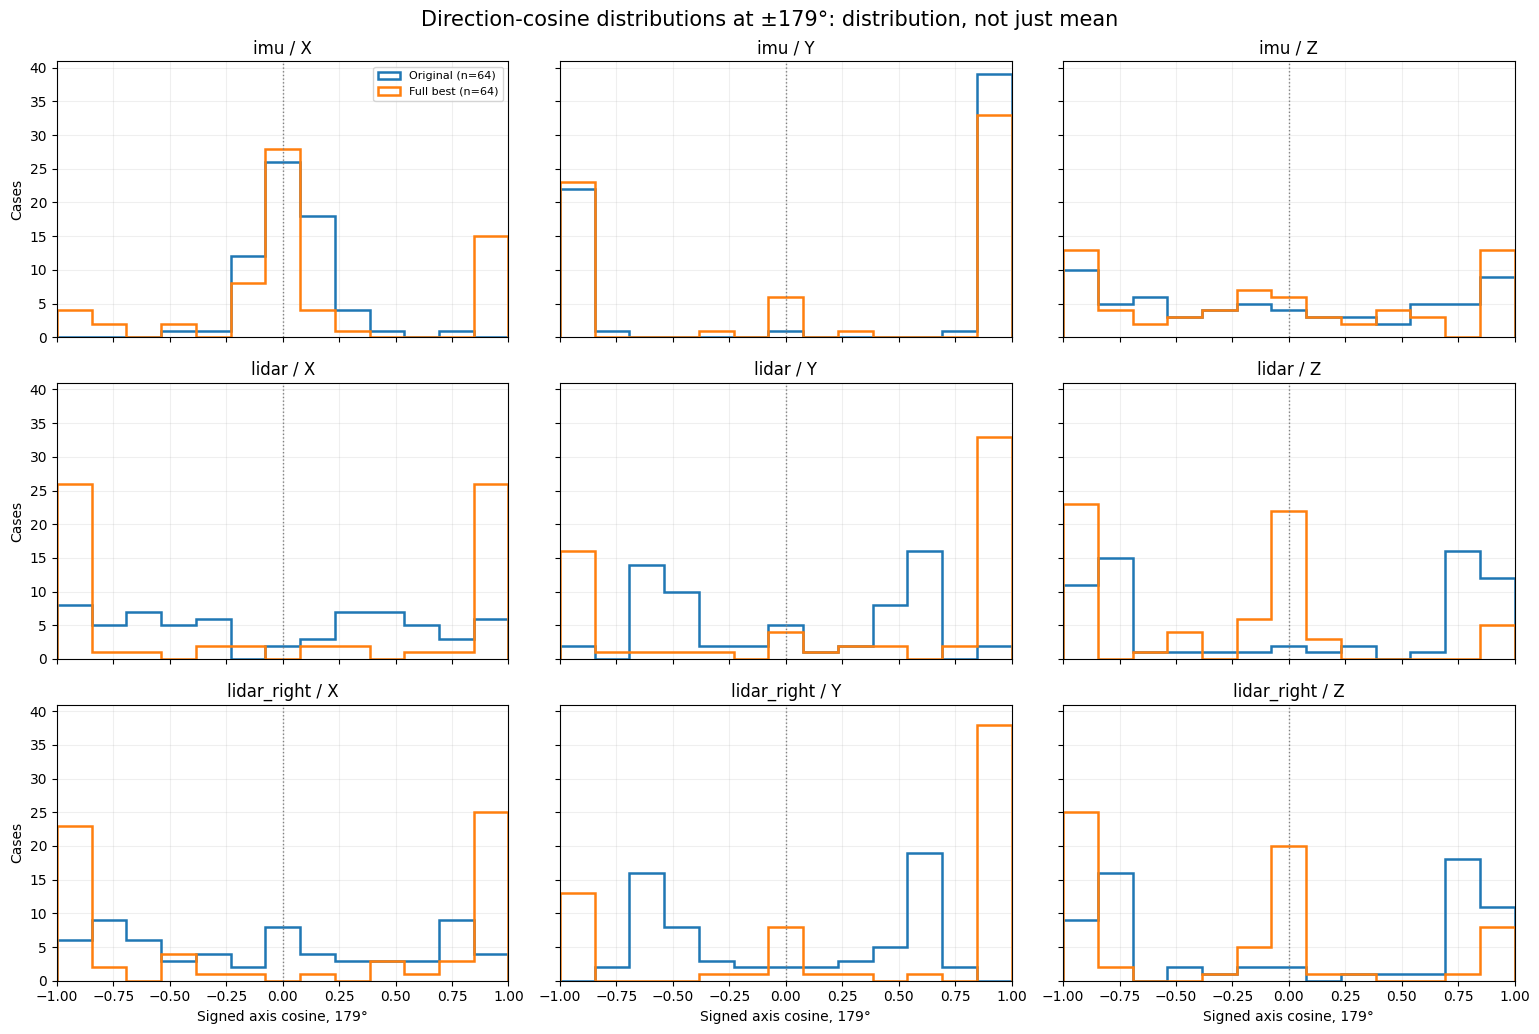

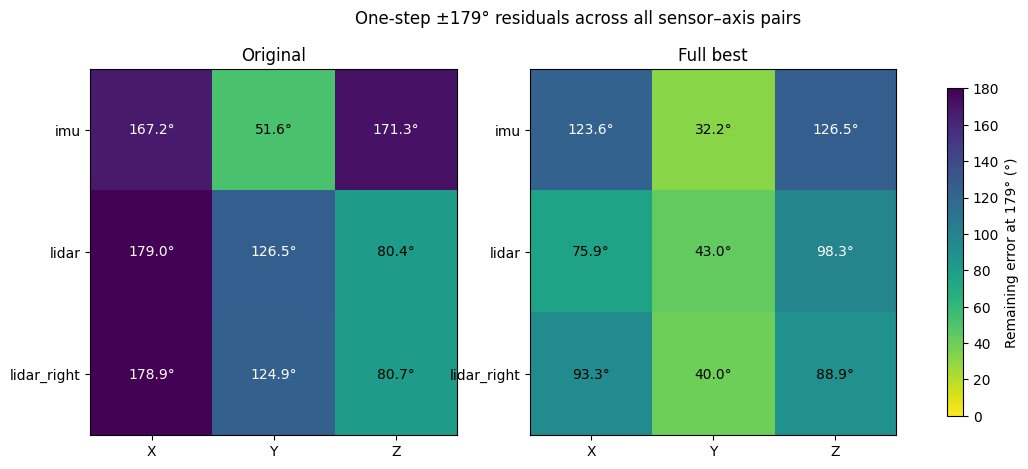

Saved one-step comparisons and cosine plots under: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.30_all_sensors_single_axis_xyz/plots/post_training_xyz_comparison


In [30]:
# Notebook 60 — post-training evaluation, CELL 3/5: one-step SO(3), magnitude and axis-cosine figures.

if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

def eval61_plot_grid(metric, title, ylabel, filename, *, target_line=False, ylim=None):
    """Nine panels: rows are sensors, columns are X/Y/Z; solid/dashed denote +/− fault."""
    fig, axes = plt.subplots(3, 3, figsize=(16, 11), sharex=True, sharey=(metric != 'mean_step_deg'))
    model_colors = {'Original': 'tab:blue', 'Full best': 'tab:orange'}
    for row, key in enumerate(EVAL61_KEYS):
        for col, axis in enumerate(EVAL61_AXES):
            ax = axes[row, col]
            for label in EVAL61_MODELS:
                for sign, style in ((1, '-'), (-1, '--')):
                    group = EVAL61_ONE_SUMMARY[(EVAL61_ONE_SUMMARY.model == label) & (EVAL61_ONE_SUMMARY.fault_key == key) & (EVAL61_ONE_SUMMARY.axis == axis)]
                    group = group[group.signed_angle_deg >= 0] if sign > 0 else group[group.signed_angle_deg < 0]
                    group = group.sort_values('angle_deg')
                    ax.plot(group.angle_deg, group[metric], style, color=model_colors[label], marker='o', markersize=3, label=f'{label} {"+" if sign > 0 else "−"}')
            if target_line:
                ax.plot(EVAL61_ANGLES, EVAL61_ANGLES, ':', color='gray', linewidth=1.4, label='No correction / GT step')
            if ylim is not None:
                ax.set_ylim(*ylim)
            ax.set_title(f'{key} / {axis}')
            ax.set_xlim(0, 180)
            ax.grid(alpha=.23)
            if row == 2:
                ax.set_xlabel('Initial absolute fault (°)')
            if col == 0:
                ax.set_ylabel(ylabel)
    axes[0, 0].legend(fontsize=8, ncol=2)
    fig.suptitle(title, fontsize=15)
    fig.tight_layout()
    fig.savefig(EVAL61_DIR / filename, dpi=180)
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)


eval61_plot_grid('mean_residual_deg', 'One-step SO(3) residuals: original vs full best, ±X/Y/Z', 'Mean residual SO(3) error (°)', 'one_step_residuals.png', target_line=True, ylim=(0, 180))
eval61_plot_grid('mean_step_deg', 'Predicted rotation magnitude versus required magnitude', 'Mean predicted correction (°)', 'one_step_update_magnitudes.png', target_line=True, ylim=(0, 180))
eval61_plot_grid('mean_axis_cosine', 'Signed predicted/GT rotation-axis cosine (not an SO(3) success metric)', 'Mean signed axis cosine', 'one_step_axis_cosines.png', ylim=(-1.05, 1.05))

# At near-180°, a mean cosine near zero can hide two clusters near +1 and −1.
fig, axes = plt.subplots(3, 3, figsize=(15.5, 10.5), sharex=True, sharey=True)
for row, key in enumerate(EVAL61_KEYS):
    for col, axis in enumerate(EVAL61_AXES):
        ax = axes[row, col]
        part = EVAL61_ONE_DF[(EVAL61_ONE_DF.fault_key == key) & (EVAL61_ONE_DF.axis == axis) & (EVAL61_ONE_DF.angle_deg == 179.0)]
        for label, color in (('Original', 'tab:blue'), ('Full best', 'tab:orange')):
            vals = part.loc[part.model == label, 'axis_cosine'].dropna().to_numpy()
            ax.hist(vals, bins=np.linspace(-1, 1, 14), histtype='step', linewidth=1.8, color=color, label=f'{label} (n={len(vals)})')
        ax.axvline(0, color='gray', linestyle=':', linewidth=1)
        ax.set_title(f'{key} / {axis}')
        ax.set_xlim(-1, 1)
        ax.grid(alpha=.2)
        if row == 2:
            ax.set_xlabel('Signed axis cosine, 179°')
        if col == 0:
            ax.set_ylabel('Cases')
axes[0, 0].legend(fontsize=8)
fig.suptitle('Direction-cosine distributions at ±179°: distribution, not just mean', fontsize=15)
fig.tight_layout()
fig.savefig(EVAL61_DIR / 'one_step_179_axis_cosine_histograms.png', dpi=180)
if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)

# Direct paired comparison at the difficult 179° boundary.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, label in zip(axes, EVAL61_MODELS):
    values = EVAL61_ONE_DF[(EVAL61_ONE_DF.model == label) & (EVAL61_ONE_DF.angle_deg == 179.0)]
    grid = values.groupby(['fault_key', 'axis']).after_deg.mean().unstack('axis').reindex(index=EVAL61_KEYS, columns=EVAL61_AXES)
    heat = ax.imshow(grid.to_numpy(), vmin=0, vmax=180, cmap='viridis_r')
    ax.set_xticks(range(3), EVAL61_AXES)
    ax.set_yticks(range(3), EVAL61_KEYS)
    ax.set_title(label)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{grid.iloc[i, j]:.1f}°', ha='center', va='center', color='white' if grid.iloc[i, j] > 95 else 'black')
fig.colorbar(heat, ax=axes, label='Remaining error at 179° (°)', shrink=.85)
fig.suptitle('One-step ±179° residuals across all sensor–axis pairs')
fig.savefig(EVAL61_DIR / 'one_step_179_heatmaps.png', dpi=180, bbox_inches='tight')
if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)
print('Saved one-step comparisons and cosine plots under:', EVAL61_DIR)


In [31]:
# Notebook 60 — post-training evaluation, CELL 4/5: truly chronological matched 12-window XYZ rollouts.
# A single key is faulted, only its ROTATION is updated; translation/time and healthy keys stay fixed.
# Each model receives the SAME physical windows/initial calibration but feeds back its OWN predictions.


@torch.inference_mode()
def eval61_chronological_rollouts():
    rows = []
    for sequence_id, sequence in enumerate(EVAL61_ROLLOUT_SEQUENCES):
        indices = np.asarray(EVAL61_DATASET.window_indices_for_sequence(sequence), dtype=np.int64)
        max_start = len(indices) - EVAL61_ROLLOUT_STEPS
        if max_start < 0:
            raise ValueError(f'{sequence}: need {EVAL61_ROLLOUT_STEPS} consecutive 5-second windows; got {len(indices)}')
        starts = np.unique(np.linspace(0, max_start, min(EVAL61_ROLLOUT_STARTS, max_start + 1)).round().astype(int))
        for start_id, start in enumerate(starts):
            window_indices = indices[start:start + EVAL61_ROLLOUT_STEPS]
            for truth_id in range(EVAL61_ROLLOUT_TRUTHS):
                # Reset the physical augmentation RNG for every chronological window: true rig is constant.
                seed = EVAL61_ROLLOUT_SEED + sequence_id * 1_000_003 + start_id * 100_003 + truth_id * 1009
                physical_windows = []
                for index in window_indices:
                    base = window_batch_to(collate_windows([EVAL61_DATASET[int(index)]]), DEVICE, dtype=DTYPE)
                    physical_windows.append(physical_augmenter(base, generator=augmentation_generator(seed)).augmented_window)
                truth = physical_windows[0].current_calibration
                for physical in physical_windows[1:]:
                    for key in EVAL61_KEYS:
                        torch.testing.assert_close(physical.current_calibration[key].transform, truth[key].transform, atol=2e-5, rtol=2e-5)
                        torch.testing.assert_close(physical.current_calibration[key].time_offset, truth[key].time_offset, atol=2e-6, rtol=2e-6)

                for fault_key in EVAL61_KEYS:
                    for axis_id, axis in enumerate(EVAL61_AXES):
                        for angle in EVAL61_ROLLOUT_ANGLES:
                            for sign in ((1,) if angle == 0 else (1, -1)):
                                signed_angle = float(sign * angle)
                                xi = {key: torch.zeros(1, 6, device=DEVICE, dtype=DTYPE) for key in EVAL61_KEYS}
                                tau = {key: torch.zeros(1, 1, device=DEVICE, dtype=DTYPE) for key in EVAL61_KEYS}
                                xi[fault_key][0, axis_id] = np.deg2rad(signed_angle)
                                initial_states = apply_independent_prior_faults(truth, xi, tau)

                                for label, candidate in EVAL61_MODELS.items():
                                    states = {key: replace(st, transform=st.transform.clone(), time_offset=st.time_offset.clone()) for key, st in initial_states.items()}
                                    for step in range(EVAL61_ROLLOUT_STEPS + 1):
                                        prior_R = states[fault_key].transform[:, :3, :3]
                                        truth_R = truth[fault_key].transform[:, :3, :3]
                                        residual = float(rotation_geodesic_deg(prior_R, truth_R)[0])
                                        current_row = dict(model=label, sequence=sequence, start_index=int(window_indices[0]), truth_id=truth_id,
                                                           fault_key=fault_key, axis=axis, signed_angle_deg=signed_angle, angle_deg=float(angle),
                                                           step=step, residual_deg=residual, predicted_step_deg=np.nan, axis_cosine=np.nan)
                                        if step < EVAL61_ROLLOUT_STEPS:
                                            input_window = clone_with_current_calibration(physical_windows[step], states)
                                            output = model_predictions(input_window, model_override=candidate).predictions[fault_key]
                                            predicted_R = output.delta_rotation
                                            desired_R = truth_R @ prior_R.transpose(-1, -2)
                                            current_row['predicted_step_deg'] = float(rotation_geodesic_deg(predicted_R, torch.eye(3, device=DEVICE, dtype=DTYPE).expand_as(predicted_R))[0])
                                            current_row['axis_cosine'] = float(eval61_axis_cosine(predicted_R, desired_R)[0])
                                            next_transform = states[fault_key].transform.clone()
                                            next_transform[:, :3, :3] = predicted_R @ prior_R
                                            states = dict(states)
                                            states[fault_key] = replace(states[fault_key], transform=next_transform)
                                        rows.append(current_row)
                print(f'Completed paired 12-window XYZ rollouts: {sequence}, start={int(window_indices[0])}, truth={truth_id + 1}/{EVAL61_ROLLOUT_TRUTHS}', flush=True)
    return pd.DataFrame.from_records(rows)


if EVAL61_RUN_ROLLOUTS:
    EVAL61_ROLL_DF = eval61_chronological_rollouts()
    EVAL61_ROLL_DF.to_csv(EVAL61_DIR / 'rollout_12_window_individual.csv', index=False)
    EVAL61_ROLL_SUMMARY = EVAL61_ROLL_DF.groupby(['model', 'fault_key', 'axis', 'angle_deg', 'signed_angle_deg', 'step'], as_index=False).agg(
        mean_residual_deg=('residual_deg', 'mean'), median_residual_deg=('residual_deg', 'median'), p90_residual_deg=('residual_deg', lambda x: x.quantile(.9)),
        success_10deg=('residual_deg', lambda x: (x < 10).mean()), success_30deg=('residual_deg', lambda x: (x < 30).mean()),
        mean_axis_cosine=('axis_cosine', 'mean'), n=('residual_deg', 'size'))
    EVAL61_ROLL_SUMMARY.to_csv(EVAL61_DIR / 'rollout_12_window_summary_signed.csv', index=False)
    final = EVAL61_ROLL_DF[EVAL61_ROLL_DF.step == EVAL61_ROLLOUT_STEPS]
    print('Final 12-window residuals at ±179°, averaged over signs, sequences and runs:')
    display(final[final.angle_deg == 179.0].groupby(['model', 'fault_key', 'axis']).residual_deg.mean().unstack('axis').round(2))
    print('12-window success rate below 10° at 179°:')
    display(final[final.angle_deg == 179.0].groupby(['model', 'fault_key', 'axis']).residual_deg.apply(lambda x: (x < 10).mean()).unstack('axis').round(3))
    print('Errors at steps 0, 1, 3, 6 and 12 (averaged across signed faults):')
    display(EVAL61_ROLL_DF[EVAL61_ROLL_DF.step.isin((0, 1, 3, 6, EVAL61_ROLLOUT_STEPS))].groupby(['model', 'fault_key', 'axis', 'angle_deg', 'step']).residual_deg.mean().unstack('step').round(2))
else:
    print('Chronological rollouts disabled by EVAL61_RUN_ROLLOUTS=False.')


Completed paired 12-window XYZ rollouts: Urban26, start=0, truth=1/1
Completed paired 12-window XYZ rollouts: Urban28, start=94, truth=1/1
Final 12-window residuals at ±179°, averaged over signs, sequences and runs:


axis                        X       Y      Z
model     fault_key                         
Full best imu            8.04    4.69  24.98
          lidar          5.35   24.41  90.69
          lidar_right    4.51   42.44  74.81
Original  imu           90.62    4.16  90.56
          lidar        178.58  179.23   5.36
          lidar_right  177.44  177.34   2.29

12-window success rate below 10° at 179°:


axis                      X    Y     Z
model     fault_key                   
Full best imu          0.75  1.0  0.75
          lidar        1.00  0.5  0.50
          lidar_right  0.75  0.5  0.50
Original  imu          0.50  1.0  0.50
          lidar        0.00  0.0  1.00
          lidar_right  0.00  0.0  1.00

Errors at steps 0, 1, 3, 6 and 12 (averaged across signed faults):


step                                     0      1      3      6      12
model     fault_key   axis angle_deg                                   
Full best imu         X    0.0          0.0   0.39   4.02  22.64   5.13
                           30.0        30.0   2.59   5.87  22.74   6.47
                           60.0        60.0   2.16   4.94  22.82   6.62
                           90.0        90.0   3.99   6.03  22.78   5.48
                           120.0      120.0   1.84   4.93  22.76   6.16
...                                     ...    ...    ...    ...    ...
Original  lidar_right Z    90.0        90.0  13.32   8.11   7.27   2.56
                           120.0      120.0  16.58   8.98   8.27   3.17
                           150.0      150.0  67.11  54.55  54.17  69.06
                           175.0      175.0  55.48  13.09  12.91   2.25
                           179.0      179.0  60.38  12.75  12.32   2.29

[144 rows x 5 columns]

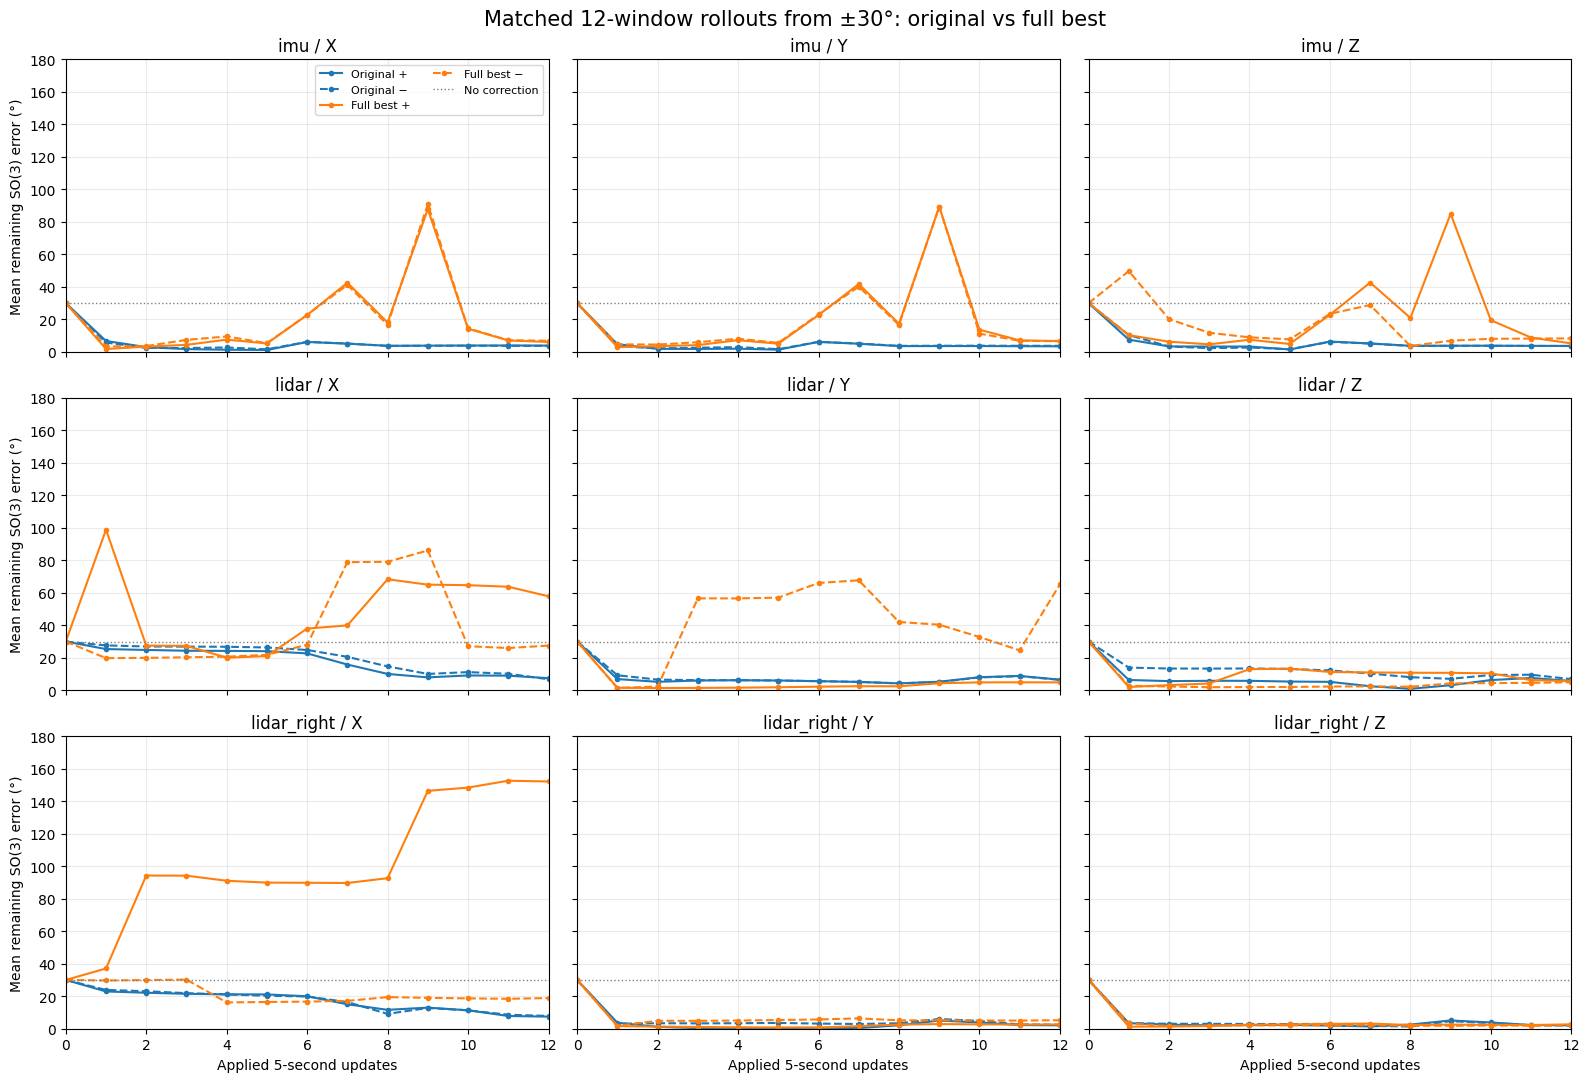

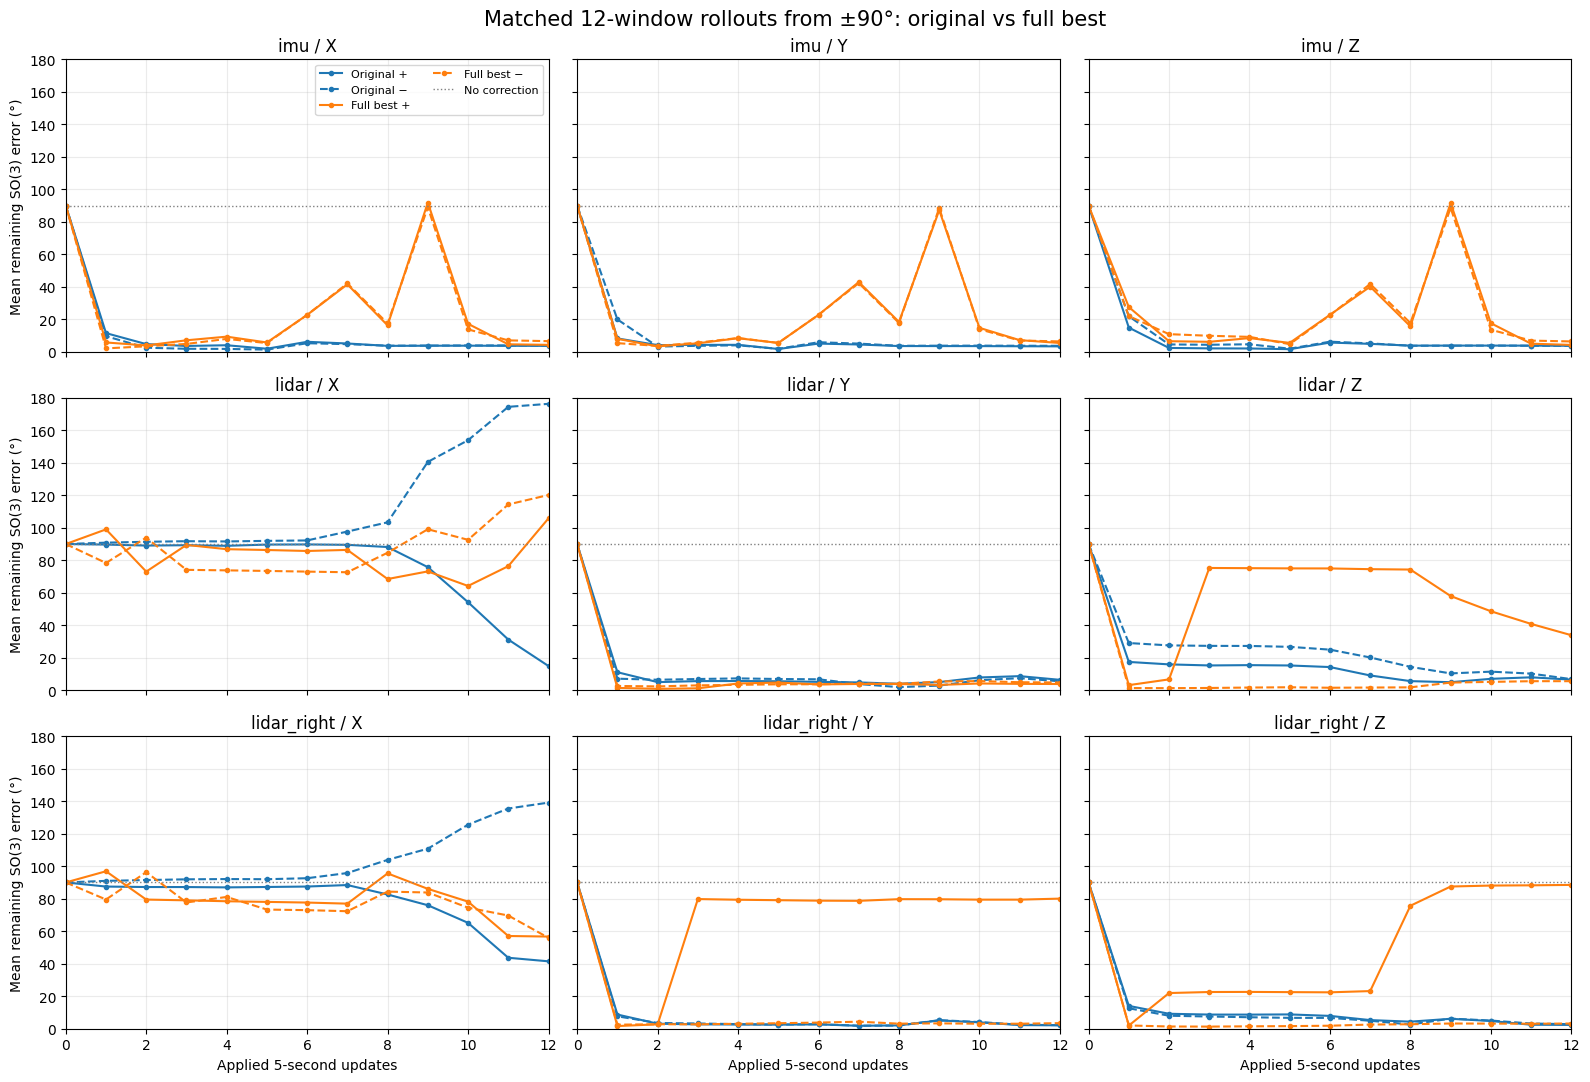

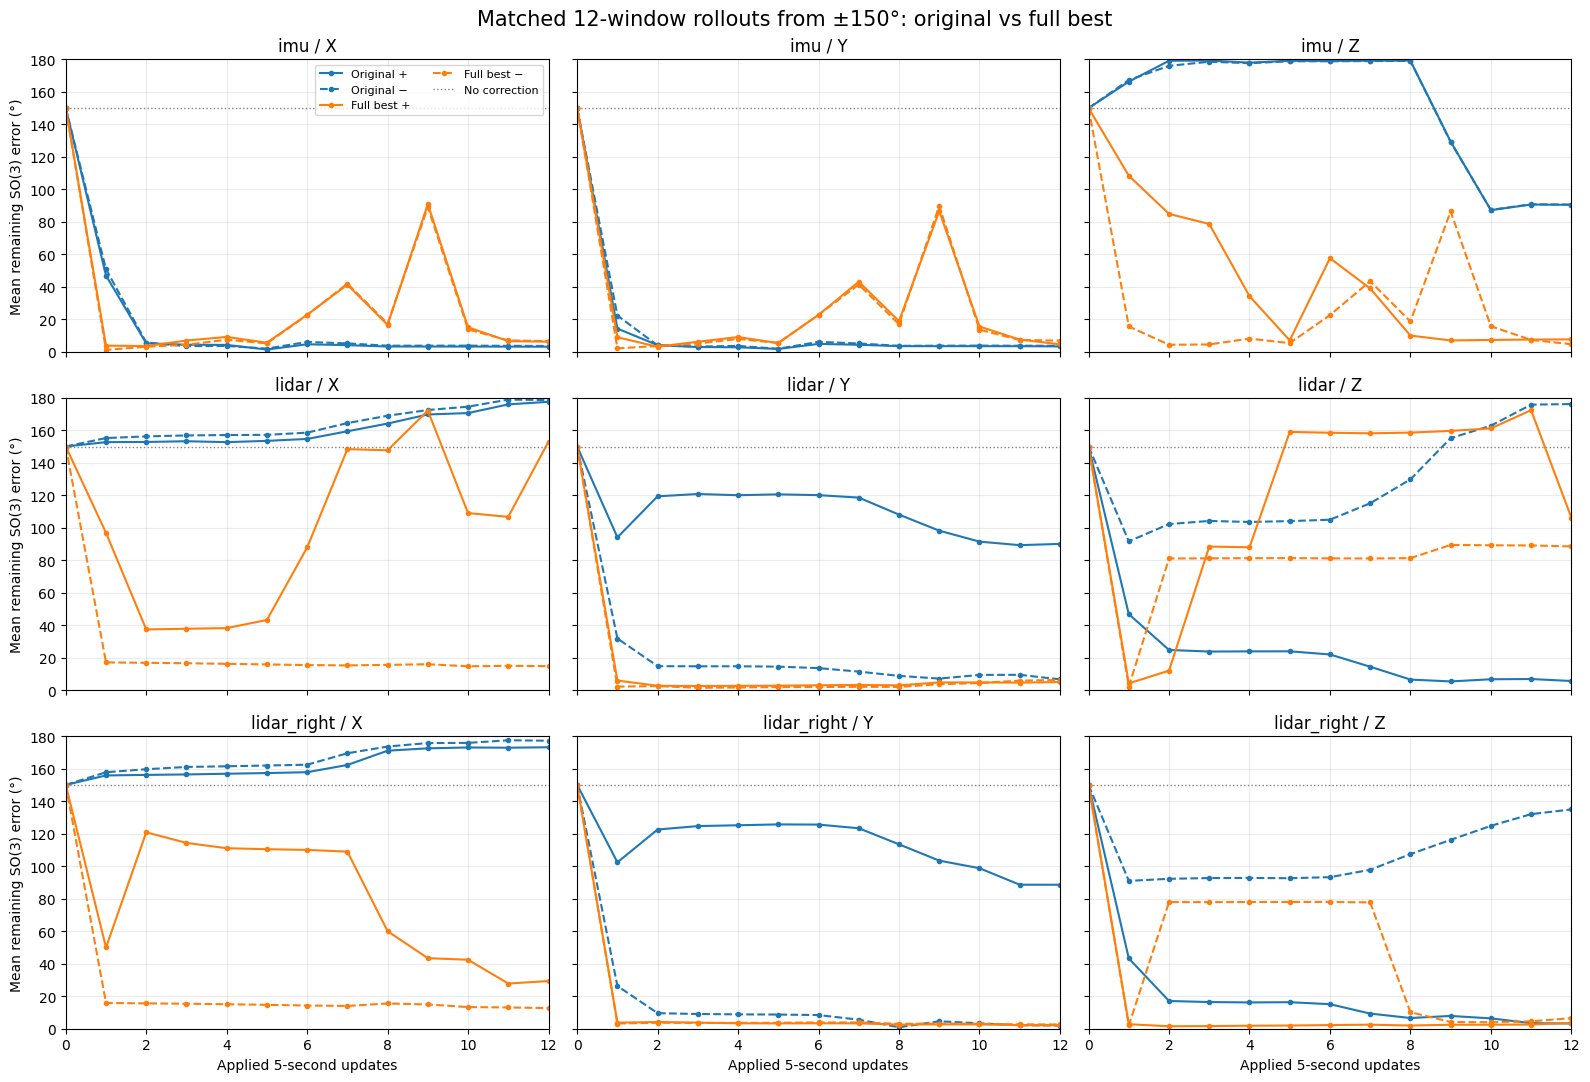

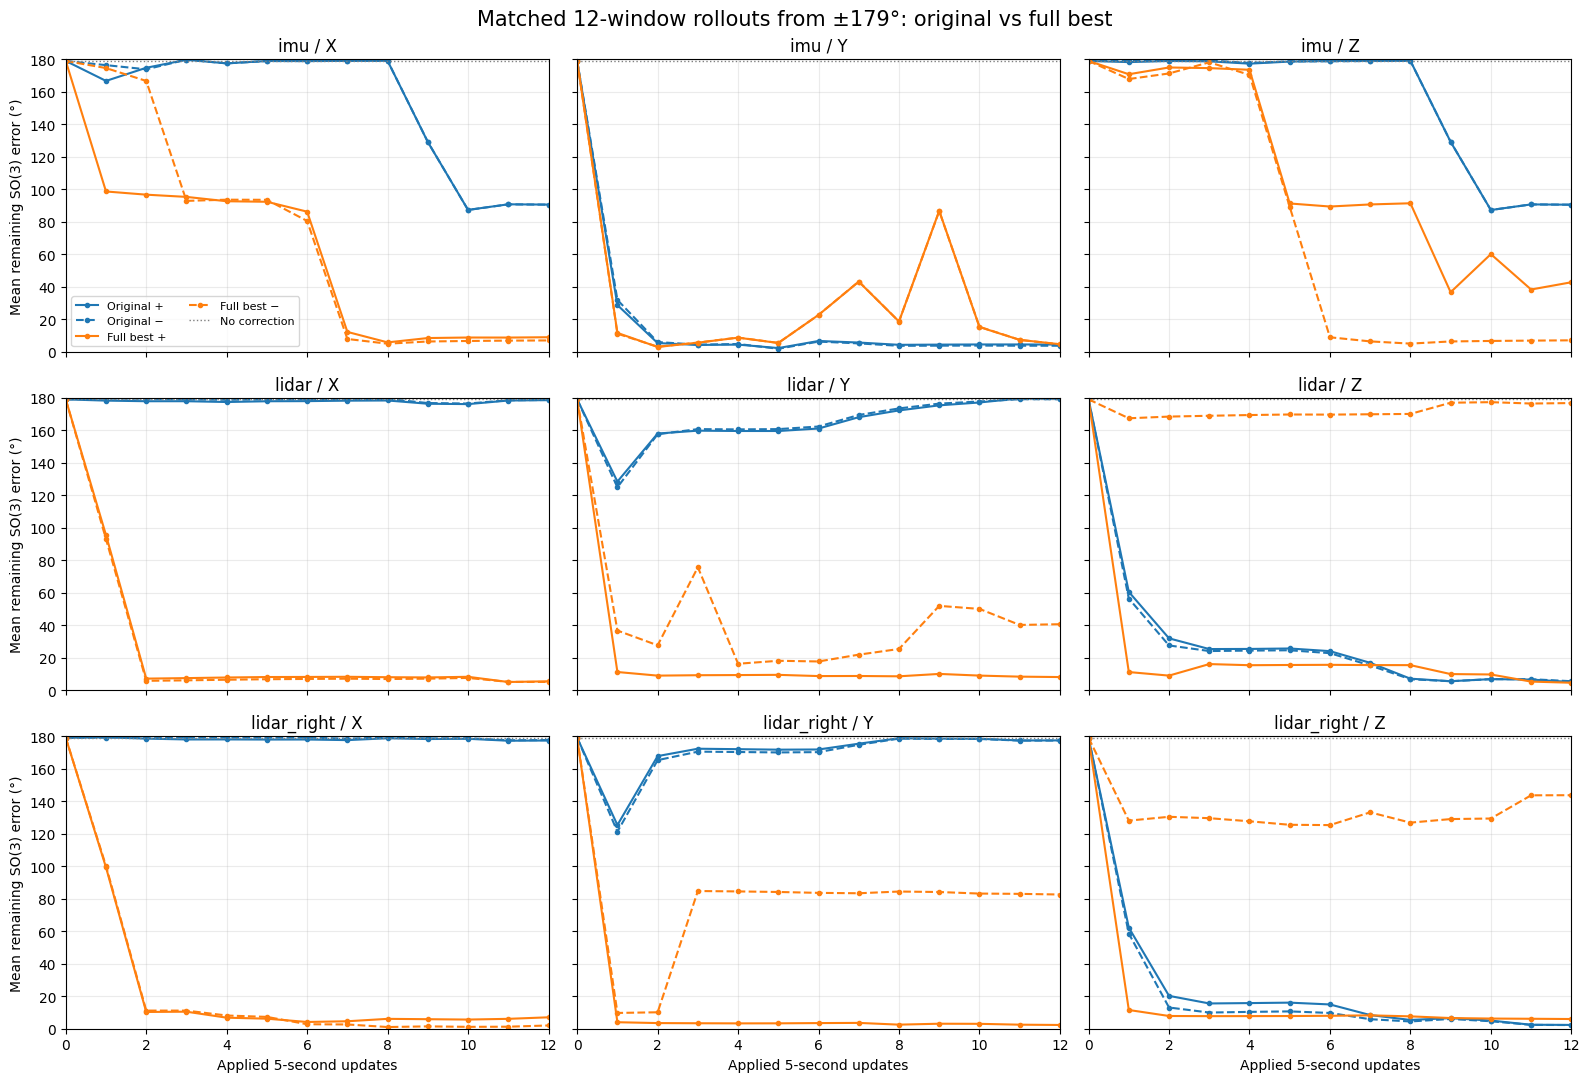

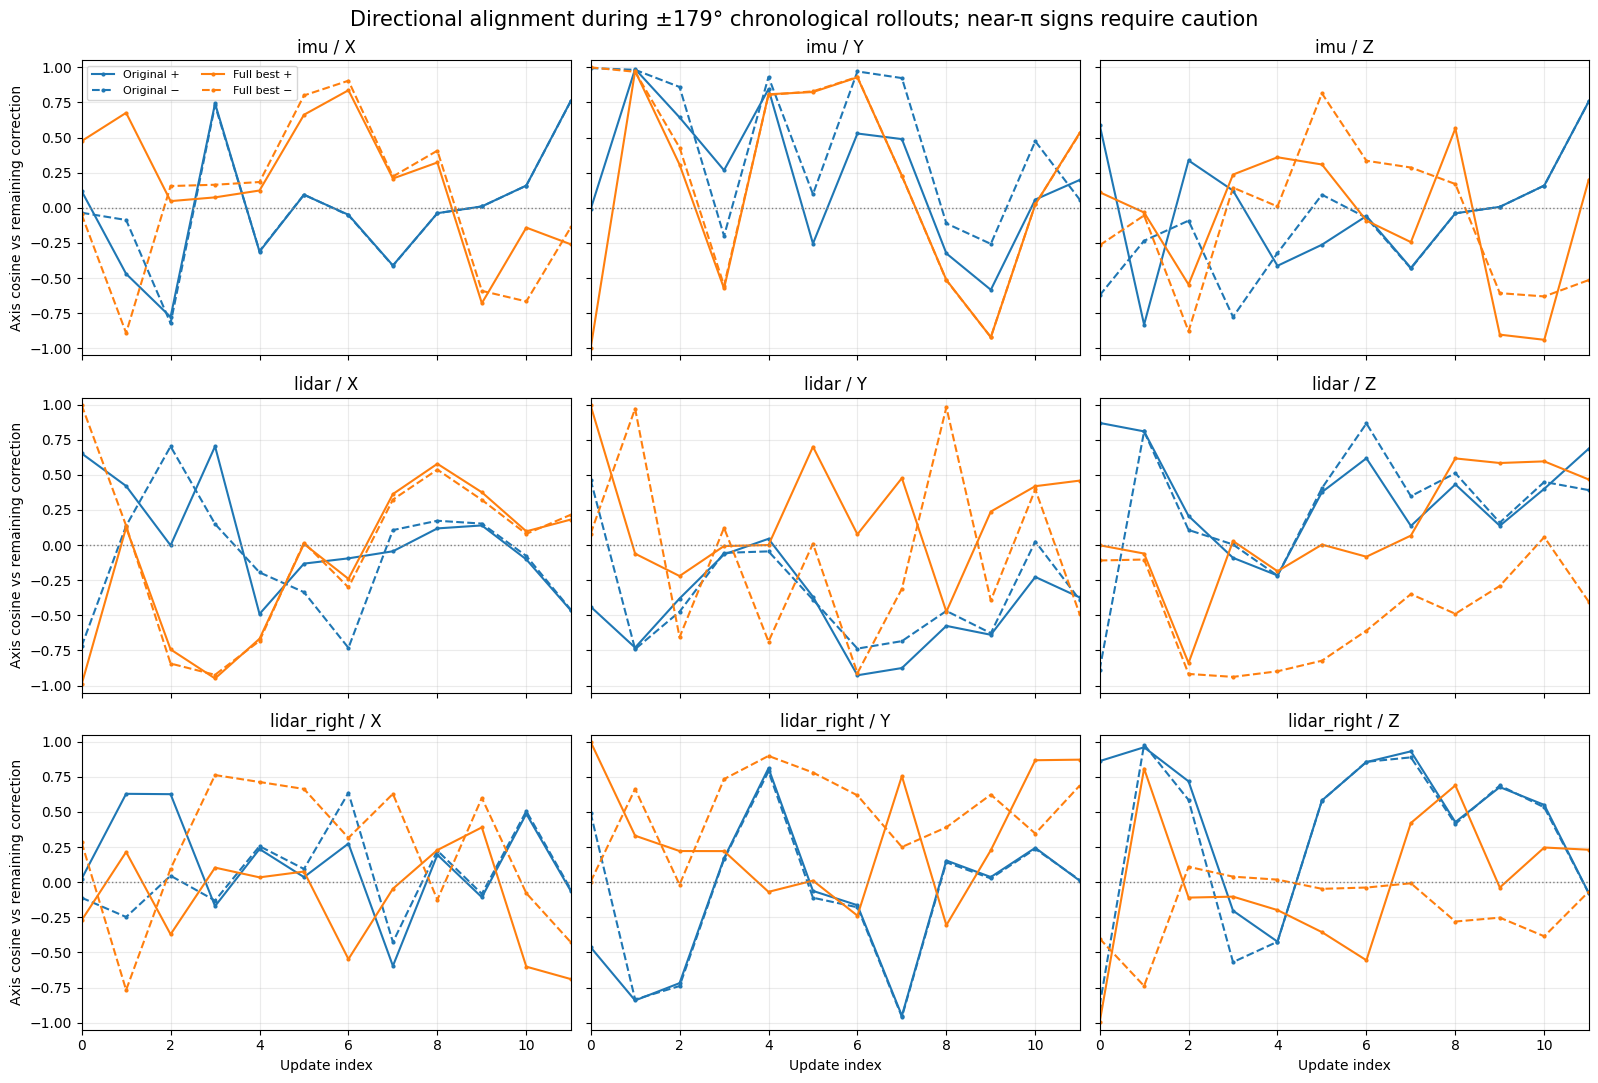

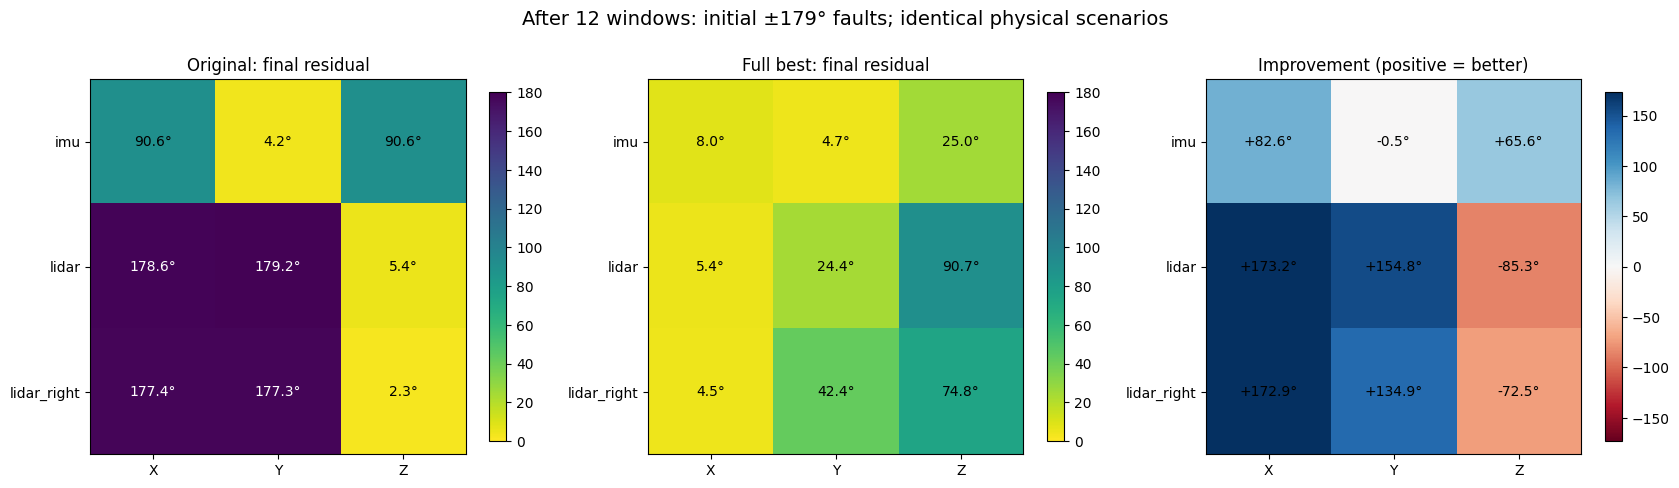

Saved matched 12-window rollout plots and per-case CSV files under: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.30_all_sensors_single_axis_xyz/plots/post_training_xyz_comparison


In [32]:
# Notebook 60 — post-training evaluation, CELL 5/5: 12-window convergence, direction cosines and summary heatmaps.

if EVAL61_RUN_ROLLOUTS:
    colors = {'Original': 'tab:blue', 'Full best': 'tab:orange'}

    # For each initial error, compare BOTH models and BOTH signs in 3x3 sensor/axis panels.
    for angle in EVAL61_ROLLOUT_PLOT_ANGLES:
        fig, axes = plt.subplots(3, 3, figsize=(16, 11), sharex=True, sharey=True)
        for row, key in enumerate(EVAL61_KEYS):
            for col, axis in enumerate(EVAL61_AXES):
                ax = axes[row, col]
                for label in EVAL61_MODELS:
                    for sign, style in ((1, '-'), (-1, '--')):
                        data = EVAL61_ROLL_SUMMARY[(EVAL61_ROLL_SUMMARY.model == label) & (EVAL61_ROLL_SUMMARY.fault_key == key) & (EVAL61_ROLL_SUMMARY.axis == axis) & (EVAL61_ROLL_SUMMARY.signed_angle_deg == sign * angle)].sort_values('step')
                        ax.plot(data.step, data.mean_residual_deg, style, marker='o', markersize=3, color=colors[label], label=f'{label} {"+" if sign > 0 else "−"}')
                ax.axhline(angle, linestyle=':', color='gray', linewidth=1, label='No correction')
                ax.set(title=f'{key} / {axis}', xlim=(0, EVAL61_ROLLOUT_STEPS), ylim=(0, 180))
                ax.grid(alpha=.25)
                if row == 2:
                    ax.set_xlabel('Applied 5-second updates')
                if col == 0:
                    ax.set_ylabel('Mean remaining SO(3) error (°)')
        axes[0, 0].legend(fontsize=8, ncol=2)
        fig.suptitle(f'Matched 12-window rollouts from ±{angle:g}°: original vs full best', fontsize=15)
        fig.tight_layout()
        fig.savefig(EVAL61_DIR / f'rollout_12_steps_{int(angle)}deg.png', dpi=180)
        if SHOW_PLOTS:
            plt.show()
        else:
            plt.close(fig)

    # How quickly does the direction cosine improve as the estimate gets closer to truth?
    fig, axes = plt.subplots(3, 3, figsize=(16, 11), sharex=True, sharey=True)
    angle = 179.0
    for row, key in enumerate(EVAL61_KEYS):
        for col, axis in enumerate(EVAL61_AXES):
            ax = axes[row, col]
            for label in EVAL61_MODELS:
                for sign, style in ((1, '-'), (-1, '--')):
                    values = EVAL61_ROLL_SUMMARY[(EVAL61_ROLL_SUMMARY.model == label) & (EVAL61_ROLL_SUMMARY.fault_key == key) & (EVAL61_ROLL_SUMMARY.axis == axis) & (EVAL61_ROLL_SUMMARY.signed_angle_deg == sign * angle)].sort_values('step')
                    ax.plot(values.step, values.mean_axis_cosine, style, marker='.', markersize=4, color=colors[label], label=f'{label} {"+" if sign > 0 else "−"}')
            ax.axhline(0, color='gray', linestyle=':', linewidth=1)
            ax.set(title=f'{key} / {axis}', xlim=(0, EVAL61_ROLLOUT_STEPS - 1), ylim=(-1.05, 1.05))
            ax.grid(alpha=.25)
            if row == 2:
                ax.set_xlabel('Update index')
            if col == 0:
                ax.set_ylabel('Axis cosine vs remaining correction')
    axes[0, 0].legend(fontsize=8, ncol=2)
    fig.suptitle('Directional alignment during ±179° chronological rollouts; near-π signs require caution', fontsize=15)
    fig.tight_layout()
    fig.savefig(EVAL61_DIR / 'rollout_179_axis_cosines_by_step.png', dpi=180)
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)

    # Final residual matrices for both models, averaged over signs and independent sequences.
    final = EVAL61_ROLL_DF[(EVAL61_ROLL_DF.step == EVAL61_ROLLOUT_STEPS) & (EVAL61_ROLL_DF.angle_deg == 179.0)]
    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    matrices = {}
    for label in EVAL61_MODELS:
        matrices[label] = final[final.model == label].groupby(['fault_key', 'axis']).residual_deg.mean().unstack('axis').reindex(index=EVAL61_KEYS, columns=EVAL61_AXES)
    grids = (matrices['Original'], matrices['Full best'], matrices['Original'] - matrices['Full best'])
    titles = ('Original: final residual', 'Full best: final residual', 'Improvement (positive = better)')
    for ax, grid, title in zip(axes, grids, titles):
        if title.startswith('Improvement'):
            limit = max(10, np.nanmax(abs(grid.to_numpy())))
            heat = ax.imshow(grid.to_numpy(), cmap='RdBu', vmin=-limit, vmax=limit)
        else:
            heat = ax.imshow(grid.to_numpy(), cmap='viridis_r', vmin=0, vmax=180)
        ax.set_xticks(range(3), EVAL61_AXES)
        ax.set_yticks(range(3), EVAL61_KEYS)
        ax.set_title(title)
        for i in range(3):
            for j in range(3):
                ax.text(j, i, f'{grid.iloc[i, j]:+.1f}°' if title.startswith('Improvement') else f'{grid.iloc[i, j]:.1f}°', ha='center', va='center', fontsize=10,
                        color='white' if (not title.startswith('Improvement') and grid.iloc[i, j] > 95) else 'black')
        fig.colorbar(heat, ax=ax, shrink=.8)
    fig.suptitle('After 12 windows: initial ±179° faults; identical physical scenarios', fontsize=14)
    fig.tight_layout()
    fig.savefig(EVAL61_DIR / 'rollout_179_final_heatmaps.png', dpi=180)
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)

    # Paired improvement CSV, comparing identical sequence/start/truth/axis/sign trajectories.
    pairing = ['sequence', 'start_index', 'truth_id', 'fault_key', 'axis', 'signed_angle_deg', 'step']
    paired = EVAL61_ROLL_DF.pivot(index=pairing, columns='model', values='residual_deg').dropna()
    assert len(paired) * len(EVAL61_MODELS) == len(EVAL61_ROLL_DF), 'Rollout comparisons were not correctly paired.'
    paired['improvement_full_best_deg'] = paired['Original'] - paired['Full best']
    paired.reset_index().to_csv(EVAL61_DIR / 'rollout_12_window_paired_improvement.csv', index=False)
    print('Saved matched 12-window rollout plots and per-case CSV files under:', EVAL61_DIR)
else:
    print('No rollout plots: EVAL61_RUN_ROLLOUTS=False')
